# Churn Analysis

The **Customer Churn Data** file (CSV format) contains qualitative and quantitative data about customers of an Indian telecommunications company, describing various aspects of the company's customer base.

The objective of this dataset is to identify specific actions that can help prevent customers from churning. The dataset consists of the following columns:

- `device` – user's device brand (Categorical)
- `first_payment_amount` – user's first payment amount (Numeric)
- `age` – user's age (Numeric or categorical?)
- `city` – user's city (Categorical)
- `number_of_cards` – number of cards owned by the user
- `payments_initiated` – number of payments initiated by the user
- `payments_failed` – number of failed payments
- `payments_completed` – number of completed payments
- `payments_completed_amount_first_7days` – total amount of payments completed during the first 7 days after joining
- `reward_purchase_count_first_7days` – number of rewards claimed during the first 7 days
- `coins_redeemed_first_7days` – number of coins redeemed during the first 7 days
- `is_referral` – whether the user was referred
- `visits_feature_1` – number of visits made by the user to product feature 1
- `visits_feature_2` – number of visits made by the user to product feature 2
- `given_permission_1` – whether the user has granted permission 1
- `given_permission_2` – whether the user has granted permission 2
- `user_id` – user identifier
- `is_churned` – whether the user churned

In [489]:
# package installation
install.packages("dplyr")
install.packages("ggplot2")
install.packages("gridExtra")
install.packages("purrr")
install.packages("FSelectorRcpp")
install.packages("tidyr")
install.packages("forcats")
install.packages("caret")
install.packages("pROC")

Warning message:
"package 'dplyr' is in use and will not be installed"
Warning message:
"package 'ggplot2' is in use and will not be installed"
Warning message:
"package 'gridExtra' is in use and will not be installed"
Warning message:
"package 'purrr' is in use and will not be installed"
Warning message:
"package 'FSelectorRcpp' is in use and will not be installed"
Warning message:
"package 'tidyr' is in use and will not be installed"
Warning message:
"package 'forcats' is in use and will not be installed"
Warning message:
"package 'caret' is in use and will not be installed"
Warning message:
"package 'pROC' is in use and will not be installed"


In [490]:
# library loading
library(dplyr)
library(ggplot2)
library(gridExtra)
library(purrr)
library(FSelectorRcpp)
library(tidyr)
library(forcats)
library(caret)
library(pROC)

Before going into the analysis in greater depth, it is important to first import the data, display a small sample of the dataset, and examine its structure.

In [ ]:
data <- read.csv("../data/customer_churn_data.csv")
head(data)
tail(data)

,device,first_payment_amount,age,city,number_of_cards,payments_initiated,payments_failed,payments_completed,payments_completed_amount_first_7days,reward_purchase_count_first_7days,coins_redeemed_first_7days,is_referral,visits_feature_1,visits_feature_2,given_permission_1,given_permission_2,user_id,is_churned
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<lgl>,<int>,<int>,<int>,<int>,<int>,<int>
1,samsung,0,20,Ahmedabad,2,1,0,1,0,NA,0,FALSE,3,0,1,0,269438,0
2,xiaomi,0,20,Surat,1,1,0,1,0,NA,0,TRUE,0,0,1,0,139521,0
3,xiaomi,0,20,Kullu,1,2,1,1,0,0,0,TRUE,0,0,0,1,307352,0
4,oneplus,0,20,Mumbai,2,4,1,2,322,2,20,FALSE,0,0,1,1,456424,0
5,apple,0,20,Pune,2,1,0,1,0,0,0,FALSE,0,1,1,1,398779,0
6,oppo,0,20,Ahmedabad,0,1,0,1,0,0,0,TRUE,0,0,1,1,136656,0


,device,first_payment_amount,age,city,number_of_cards,payments_initiated,payments_failed,payments_completed,payments_completed_amount_first_7days,reward_purchase_count_first_7days,coins_redeemed_first_7days,is_referral,visits_feature_1,visits_feature_2,given_permission_1,given_permission_2,user_id,is_churned
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<lgl>,<int>,<int>,<int>,<int>,<int>,<int>
104138,samsung,53,NA,Bangalore,1,2,0,2,63,3,23,FALSE,0,1,1,1,4833,1
104139,samsung,55,NA,Ongole,0,3,1,2,56,2,20,TRUE,0,0,1,0,30036,1
104140,vivo,67,NA,Chennai,1,1,0,1,67,2,53,TRUE,0,0,1,0,377399,1
104141,apple,67,NA,Bangalore,3,2,0,2,137,NA,0,FALSE,0,0,1,1,8415,1
104142,samsung,83,NA,Hyderabad,5,3,1,2,211,5,140,FALSE,0,0,0,1,8056,1
104143,oneplus,437,NA,Hyderabad,1,1,0,1,437,0,0,FALSE,0,0,1,1,109558,1


In [492]:
str(data)

'data.frame':	104143 obs. of  18 variables:
 $ device                               : chr  "samsung" "xiaomi" "xiaomi" "oneplus" ...
 $ first_payment_amount                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ age                                  : int  20 20 20 20 20 20 20 20 20 20 ...
 $ city                                 : chr  "Ahmedabad" "Surat" "Kullu" "Mumbai" ...
 $ number_of_cards                      : int  2 1 1 2 2 0 0 0 0 0 ...
 $ payments_initiated                   : int  1 1 2 4 1 1 1 17 1 1 ...
 $ payments_failed                      : int  0 0 1 1 0 0 0 0 0 0 ...
 $ payments_completed                   : int  1 1 1 2 1 1 1 12 1 1 ...
 $ payments_completed_amount_first_7days: int  0 0 0 322 0 0 0 143 0 0 ...
 $ reward_purchase_count_first_7days    : int  NA NA 0 2 0 0 0 6 0 NA ...
 $ coins_redeemed_first_7days           : int  0 0 0 20 0 0 0 190 0 0 ...
 $ is_referral                          : logi  FALSE TRUE TRUE FALSE FALSE TRUE ...
 $ visits_feature_1              

At this initial stage, the data appear to follow an appropriate format: numerical variables are not stored as character strings, categorical variables seem clean (with no unusual characters), and so on. However, these aspects should be examined in greater detail.

The only point worth highlighting at this stage is the presence of missing values (`NA`), which can already be identified in this initial overview. Therefore, these missing values will need to be investigated further in the following sections.

## 1. Exploratory Data Analysis

- Descriptive statistics and overall data quality assessment.
- Visualizations to understand the distribution of variables and categories.
- Visualizations to explore the relationships between the attributes and the target variable, `is_churned`.
- Summary of the conclusions drawn from this section.

The `summary()` function is used as a first step to gain an initial understanding of the variables in the dataset.

In [493]:
summary(data)

       device       first_payment_amount      age               city       
 Length   :104143   Min.   :   0.00      Min.   :20.00   Length   :104143  
 N.unique :    77   1st Qu.:   2.00      1st Qu.:27.00   N.unique :   752  
 N.blank  :   118   Median :  12.00      Median :31.00   N.blank  :  5842  
 Min.nchar:     0   Mean   :  34.77      Mean   :32.69   Min.nchar:     0  
 Max.nchar:    38   3rd Qu.:  37.00      3rd Qu.:36.00   Max.nchar:    33  
                    Max.   :4370.00      Max.   :80.00                     
                                         NAs    :142                       
 number_of_cards  payments_initiated payments_failed   payments_completed
 Min.   : 0.000   Min.   :  1.000    Min.   : 0.0000   Min.   :  1.000   
 1st Qu.: 1.000   1st Qu.:  1.000    1st Qu.: 0.0000   1st Qu.:  1.000   
 Median : 1.000   Median :  2.000    Median : 0.0000   Median :  1.000   
 Mean   : 1.989   Mean   :  2.847    Mean   : 0.4399   Mean   :  1.831   
 3rd Qu.: 3.000   3rd 

Using this function, it is possible to start extracting information such as means, quartiles, and medians. It also helps identify potential outliers. For example, in `payments_completed_amount`, the median is 21.00, while the maximum value is 11,107.00, which is considerably higher. The same occurs with variables such as `first_payment_amount`, where the median is 12.00 and the maximum value is 4,370.00, again indicating a potentially extreme value.

On the other hand, missing values (`NA`) can also be observed across several variables. To provide a clearer overview of their distribution, the following table is constructed.

In [494]:
nulls <- data.frame(
  null_values = colSums(is.na(data)),
  null_percentage = round(colSums(is.na(data)) / nrow(data) * 100, 2)
)

num_variables_with_nulls <- nrow(nulls[nulls$null_values > 0, ])

print(nulls)
print(paste("Number of variables with null values:", num_variables_with_nulls))
print(paste("Number of variables:", ncol(data)))

                                      null_values null_percentage
device                                          0            0.00
first_payment_amount                            0            0.00
age                                           142            0.14
city                                            0            0.00
number_of_cards                               472            0.45
payments_initiated                            472            0.45
payments_failed                               472            0.45
payments_completed                            472            0.45
payments_completed_amount_first_7days         472            0.45
reward_purchase_count_first_7days           23264           22.34
coins_redeemed_first_7days                    472            0.45
is_referral                                     0            0.00
visits_feature_1                             2646            2.54
visits_feature_2                             2646            2.54
given_perm

It is found that 10 out of the 18 variables contain missing values (`NA`), with `reward_purchase_count_first_7days` standing out in particular, as missing values account for 22.34% of its observations. For the remaining variables, the proportion of missing values does not appear particularly concerning at first glance or high enough to compromise the analysis.

However, this table only takes `NA` values into account. When examining the information returned by the `summary(data)` function, it becomes apparent that there are also blank values (`""`) in categorical variables. To ensure an accurate analysis of missing data, these blank values must also be taken into consideration.

In [495]:
missing_values <- sapply(data, function(x) {
  if (is.character(x)) {
    is.na(x) | trimws(x) == ""
  } else {
    is.na(x)
  }
})

missing_values <- data.frame(
    missing_count = colSums(missing_values),
    missing_percentage = round(colSums(missing_values) / nrow(data) * 100, 2) 
)

print(missing_values)
print(paste("Number of variables with missing values:", nrow(missing_values[missing_values$missing_count > 0, ])))
print(paste("Number of variables:", ncol(data)))

                                      missing_count missing_percentage
device                                          118               0.11
first_payment_amount                              0               0.00
age                                             142               0.14
city                                           5842               5.61
number_of_cards                                 472               0.45
payments_initiated                              472               0.45
payments_failed                                 472               0.45
payments_completed                              472               0.45
payments_completed_amount_first_7days           472               0.45
reward_purchase_count_first_7days             23264              22.34
coins_redeemed_first_7days                      472               0.45
is_referral                                       0               0.00
visits_feature_1                               2646               2.54
visits

After accounting for blank values (`""`), the number of variables containing missing values increases from 10 to 12. In the `city` variable, missing values account for 5.61% of the observations.

It is also important to check for duplicate categories in the categorical variables `city` and `device`. For example, the same category may appear more than once due to differences in capitalization, with some values written in uppercase and others in lowercase.

In [496]:
unique(data$device)

[1] "samsung"                               
 [2] "xiaomi"                                
 [3] "oneplus"                               
 [4] "apple"                                 
 [5] "oppo"                                  
 [6] "hmd global"                            
 [7] "realme"                                
 [8] "sony"                                  
 [9] "motorola"                              
[10] "huawei"                                
[11] "vivo"                                  
[12] "asus"                                  
[13] "lge"                                   
[14] "yu"                                    
[15] "lyf"                                   
[16] "swipe"                                 
[17] "google"                                
[18] "lenovo"                                
[19] "zuk"                                   
[20] "infinix mobility limited"              
[21] "blackberry"                            
[22] "10or"                                  
[23] "tecno mobile limited"                  
[24] "tecno"                                 
[25] "yuho"                                  
[26] "mobiistar"                             
[27] "micromax"                              
[28] "infinix"                               
[29] ""                                      
[30] "lava"                                  
[31] "gionee"                                
[32] "coolpad"                               
[33] "lemobile"                              
[34] "ulefone"                               
[35] "blackshark"                            
[36] "hmd global oy"                         
[37] "intex"                                 
[38] "zte"                                   
[39] "letv"                                  
[40] "panasonic"                             
[41] "xolo"                                  
[42] "htc"                                   
[43] "infocus"                               
[44] "tcl"                                   
[45] "yulong"                                
[46] "inone"                                 
[47] "doogee"                                
[48] "iball slide"                           
[49] "longcheer"                             
[50] "vernee"                                
[51] "fortuneship"                           
[52] "nubia"                                 
[53] "ivoomi"                                
[54] "leeco"                                 
[55] "acer"                                  
[56] "blu"                                   
[57] "sonimtech"                             
[58] "smartron"                              
[59] "foxconn international holdings limited"
[60] "comio"                                 
[61] "haier"                                 
[62] "celkon"                                
[63] "eastaeon"                              
[64] "itel mobile limited"                   
[65] "foxda"                                 
[66] "meizu"                                 
[67] "billion"                               
[68] "tp-link"                               
[69] "essential products"                    
[70] "vsmart"                                
[71] "elephone"                              
[72] "t54"                                   
[73] "unknown"                               
[74] "centric"                               
[75] "lg electronics"                        
[76] "innovatech"                            
[77] "karbonn"

Regarding the formatting of the values, all device brands appear to be written entirely in lowercase, and no duplicate categories seem to be present. However, the value `device = unknown` is also observed, suggesting that it may represent a missing value. Therefore, it should also be taken into account when analyzing missing data.

In [497]:
unique(data$city)

[1] "Ahmedabad"                         "Surat"                            
  [3] "Kullu"                             "Mumbai"                           
  [5] "Pune"                              "Warangal"                         
  [7] "Kanchipuram"                       "Hyderabad"                        
  [9] "Jalandhar"                         "Berhampur"                        
 [11] "Bangalore"                         "NCR"                              
 [13] "Thiruvananthapuram"                "Madurai"                          
 [15] "Ludhiana"                          ""                                 
 [17] "Lucknow"                           "Kharagpur"                        
 [19] "Pimpri-Chinchwad"                  "Tiruvarur"                        
 [21] "Bageshwar "                        "Sirsa"                            
 [23] "Churu"                             "Varanasi"                         
 [25] "Hanumangarh"                       "Kurnool"                          
 [27] "Coimbatore"                        "Kolkata"                          
 [29] "Vijayawada"                        "Jamshedpur"                       
 [31] "Vadodara"                          "Amritsar"                         
 [33] "cambodia"                          "Nizamabad"                        
 [35] "Ambala"                            "Nanded"                           
 [37] "Banswara"                          "Agra"                             
 [39] "Amravati"                          "Sonipat"                          
 [41] "Jaipur"                            "Sundargarh/ rourkela"             
 [43] "Visakhapatnam"                     "Kolar"                            
 [45] "Mysore"                            "Chennai"                          
 [47] "Junagadh"                          "Dehradun"                         
 [49] "Rajkot"                            "Nagpur"                           
 [51] "Sangli"                            "Bharuch"                          
 [53] "Bhopal"                            "Kankroli"                         
 [55] "Kochi"                             "Third-largest in the Indian state"
 [57] "Haridwar"                          "Beawar City"                      
 [59] "Bhagalpur"                         "Kishanganj"                       
 [61] "San Francisco"                     "Anantapur"                        
 [63] "Rewa"                              "Ajmer"                            
 [65] "Bhuj"                              "Secunderabad"                     
 [67] "Rupnagar"                          "Bhubaneshwar"                     
 [69] "Muktsar"                           "ludhiana"                         
 [71] "Pratapgarh"                        "Renebennur"                       
 [73] "Bareilly"                          "Nashik"                           
 [75] "Gaya"                              "Chattarpur"                       
 [77] "Chandigarh"                        "Thrissur"                         
 [79] "Vellore"                           "Dispur/Guwahati"                  
 [81] "Guwahati"                          "Hisar"                            
 [83] "Saharanpur"                        "Allahabad"                        
 [85] "Mahesana"                          "Yamunanagar"                      
 [87] "Nalgonda"                          "Singrauli"                        
 [89] "Jammu"                             "Kachachh,Gujrat"                  
 [91] "Hailakandi"                        "Adilabad"                         
 [93] "Krishnagiri"                       "Medininagar"                      
 [95] "Gwalior"                           "Tiruvallur"                       
 [97] "Indore"                            "Pithampur"                        
 [99] "Patna"                             "Gangtok"                          
[101] "Muzaffarnagar"                     "Pathankot"                        
[103] "Telangana"       

In this case, a large number of values are present, so simply inspecting them visually is not a good practice. Nevertheless, some cities appear to be written entirely in uppercase, while others use lowercase or different capitalization formats. This will be checked in the following step.

In [498]:
# we can create a function to clean the strings by converting them to lowercase and trimming whitespace
clean_string <- function(x) {
  tolower(trimws(x))
}

print(paste("Number of unique cities before cleaning:", length(unique(data$city))))
print(paste("Number of unique cleaned cities:", length(unique(clean_string(data$city)))))

[1] "Number of unique cities before cleaning: 752"
[1] "Number of unique cleaned cities: 723"


In [499]:
# see if there are also any "unknown" values in the city column
sum(tolower(trimws(data$city)) == "unknown", na.rm = TRUE)

[1] 0

It can be concluded that duplicate categories were indeed present. After standardizing the city names, the number of unique cities decreased from 752 to 723. Unlike the `device` variable, no `unknown` values were found in this case.

In [500]:
print(paste("Number of unique devices before cleaning:", length(unique(data$device))))
print(paste("Number of unique cleaned devices:", length(unique(clean_string(data$device)))))

[1] "Number of unique devices before cleaning: 77"
[1] "Number of unique cleaned devices: 77"


It is confirmed that there are no duplicate categories in `device` resulting from differences in capitalization or formatting.

After completing this initial data quality analysis, the city names are standardized to a consistent format to avoid duplicate categories. Additionally, all blank (`""`) and `unknown` values are replaced with `NA`, as they are considered missing values.

In [501]:
data <- data %>%
  mutate(across(
    where(is.character),
    ~ {
      x <- tolower(trimws(.x))
      x[x == "" | x == "unknown"] <- NA_character_
      x
    }
  ))

summary(data$city)
summary(data$device)
head(data)

   Length  N.unique   N.blank Min.nchar Max.nchar       NAs 
   104143       722         0         2        33      5842 

   Length  N.unique   N.blank Min.nchar Max.nchar       NAs 
   104143        75         0         2        38       119 

,device,first_payment_amount,age,city,number_of_cards,payments_initiated,payments_failed,payments_completed,payments_completed_amount_first_7days,reward_purchase_count_first_7days,coins_redeemed_first_7days,is_referral,visits_feature_1,visits_feature_2,given_permission_1,given_permission_2,user_id,is_churned
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<lgl>,<int>,<int>,<int>,<int>,<int>,<int>
1,samsung,0,20,ahmedabad,2,1,0,1,0,NA,0,FALSE,3,0,1,0,269438,0
2,xiaomi,0,20,surat,1,1,0,1,0,NA,0,TRUE,0,0,1,0,139521,0
3,xiaomi,0,20,kullu,1,2,1,1,0,0,0,TRUE,0,0,0,1,307352,0
4,oneplus,0,20,mumbai,2,4,1,2,322,2,20,FALSE,0,0,1,1,456424,0
5,apple,0,20,pune,2,1,0,1,0,0,0,FALSE,0,1,1,1,398779,0
6,oppo,0,20,ahmedabad,0,1,0,1,0,0,0,TRUE,0,0,1,1,136656,0


### Variable and Category Distributions

In this section, visualizations are created to examine the individual distributions of the variables. The analysis begins with the target variable, `is_churned`.

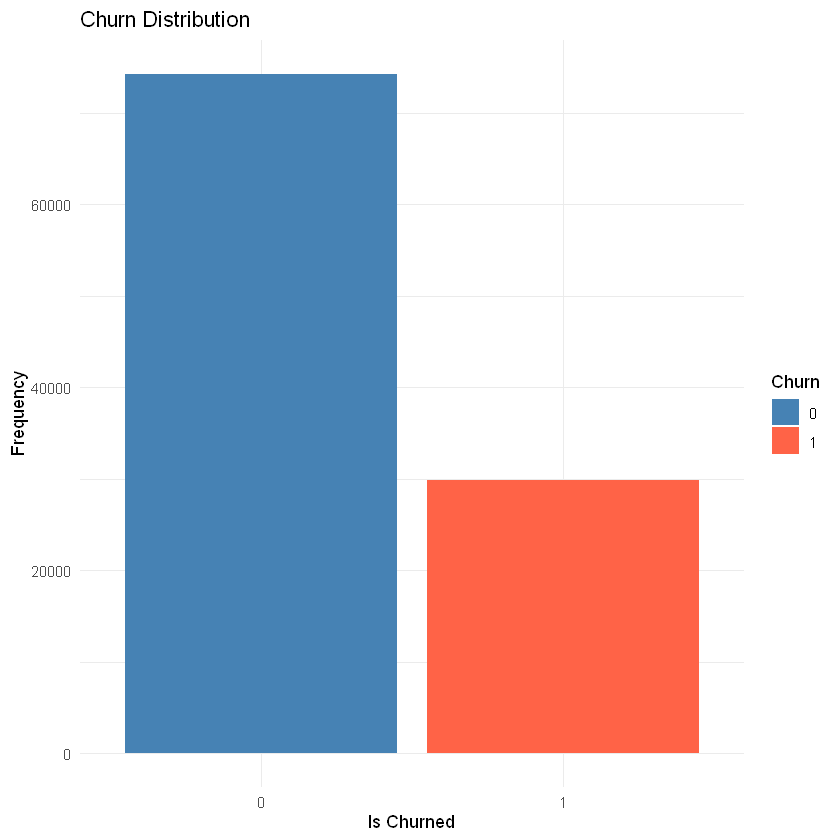

In [502]:
ggplot(data, aes(x = as.factor(is_churned),
                 fill = as.factor(is_churned))) +
  geom_bar() +
  scale_fill_manual(values = c("0" = "steelblue", "1" = "tomato")) +
  labs(
    title = "Churn Distribution",
    x = "Is Churned",
    y = "Frequency",
    fill = "Churn"
  ) +
  theme_minimal()

A clear imbalance can be observed between the number of instances in the dataset with `is_churned = 0` and `is_churned = 1`. The percentage of each class is calculated below:

In [503]:
churned_0_percentage <- round(sum(data$is_churned == 0, na.rm = TRUE) / nrow(data) * 100, 2)
churned_1_percentage <- round(sum(data$is_churned == 1, na.rm = TRUE) / nrow(data) * 100, 2)

churned_distribution <- data.frame(
  churn_status = c("Not churned", "Churned"),
  percentage = c(churned_0_percentage, churned_1_percentage)
)

print(churned_distribution)

  churn_status percentage
1  Not churned      71.32
2      Churned      28.68


It can be observed that there are considerably more instances of *Not churned* (71.32%) than of *Churned* (28.68%). Although this class imbalance is not particularly severe, it could lead the model to develop a greater tendency to predict the majority class, making it more difficult to correctly identify users who churn.

For this reason, it will be important to pay particular attention to the model's performance on the *Churned* class. This is especially relevant from a business perspective, since failing to identify a customer who is about to leave (false negative) may have a higher cost than incorrectly classifying a customer as churned when they actually remain (false positive).

The analysis continues with the visualization of the remaining categorical variables: `device`, `city`, `given_permission_1`, `given_permission_2`, and `is_referral`.

In [504]:
# count the frequency and relative frequency of each device type
device_count <- data %>%
  group_by(device) %>%
  summarise(
    frequency = n(),
    relative_frequency = n() / nrow(data) * 100
  ) %>%
  arrange(desc(frequency))

head(device_count, 20)

device,frequency,relative_frequency
<chr>,<int>,<dbl>
xiaomi,25009,24.01409600
samsung,16657,15.99435392
apple,15811,15.18200935
oneplus,14613,14.03166799
vivo,8523,8.18393939
oppo,7093,6.81082742
realme,3615,3.47118865
motorola,3378,3.24361695
huawei,3226,3.09766379


It was already known that there were 75 different device types. Therefore, displaying all of them would not be the most suitable option. Instead, only the 20 most frequent categories are displayed.

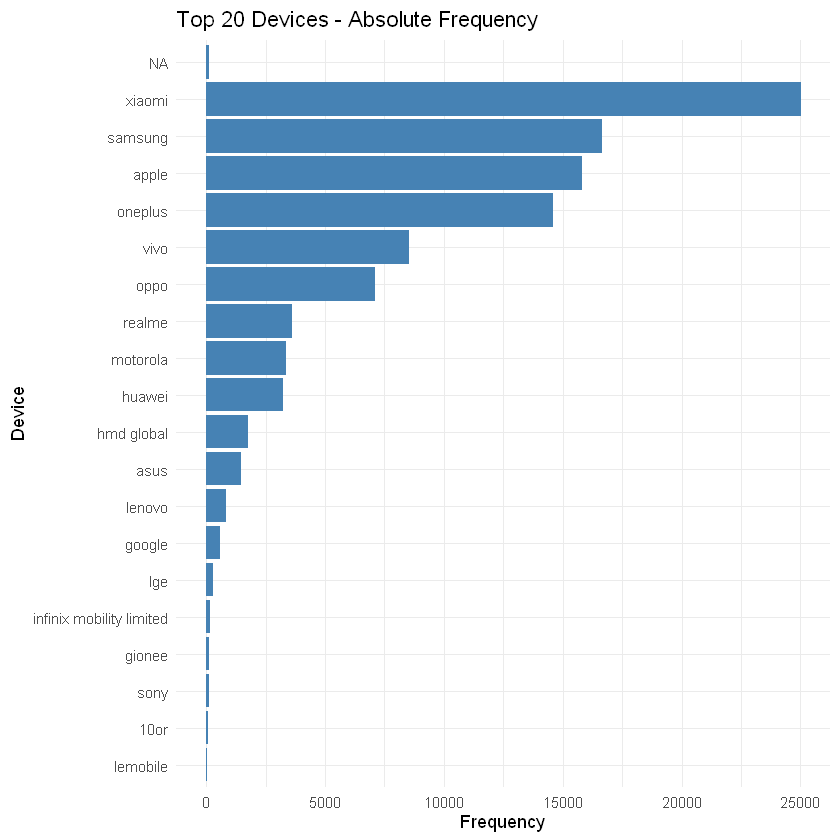

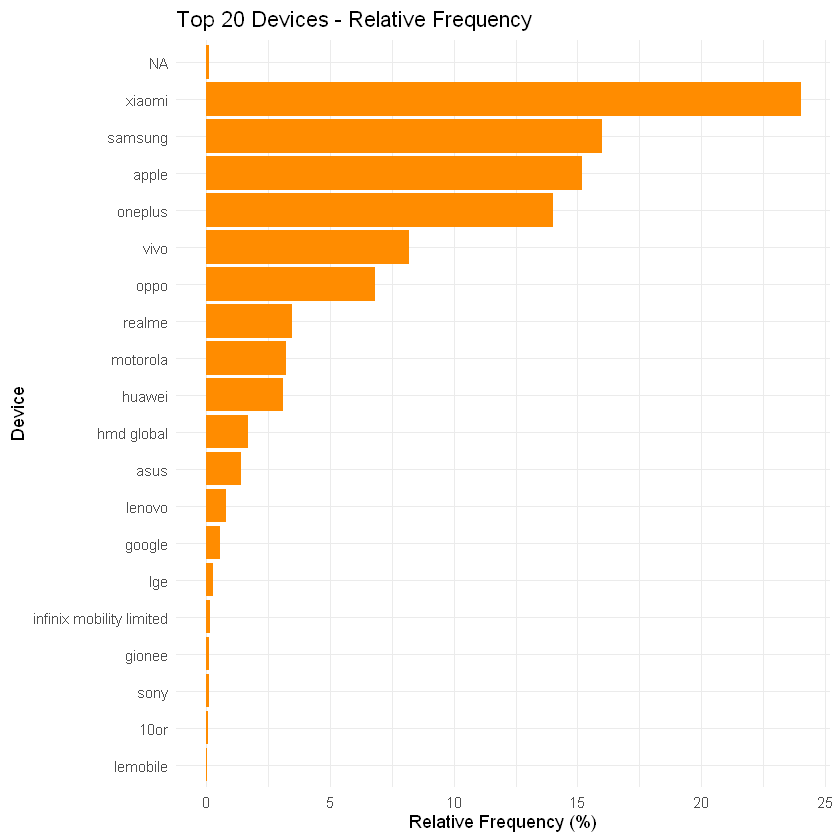

In [505]:
# save the top 20 devices in a new data frame
top20 <- device_count[1:20, ]

# plot the top 20 devices by absolute frequency
ggplot(top20, aes(x = reorder(device, frequency), y = frequency)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Top 20 Devices - Absolute Frequency",
    x = "Device",
    y = "Frequency"
  ) +
  theme_minimal()

# plot the top 20 devices by relative frequency
ggplot(top20, aes(x = reorder(device, relative_frequency),
                  y = relative_frequency)) +
  geom_col(fill = "darkorange") +
  coord_flip() +
  labs(
    title = "Top 20 Devices - Relative Frequency",
    x = "Device",
    y = "Relative Frequency (%)"
  ) +
  theme_minimal()

It can be observed that a large proportion of the dataset's instances are concentrated in just 10 device types. To determine the exact proportion of observations they account for, the cumulative relative frequency is calculated.

In [506]:
device_count <- data %>%
  group_by(device) %>%
  summarise(
    frequency = n()
  ) %>%
  ungroup() %>%
  mutate(
    relative_frequency = frequency / sum(frequency) * 100
  ) %>%
  arrange(desc(frequency)) %>%
  mutate(
    accumulated_relative_frequency = cumsum(relative_frequency)
  )

head(device_count, 20)

device,frequency,relative_frequency,accumulated_relative_frequency
<chr>,<int>,<dbl>,<dbl>
xiaomi,25009,24.01409600,24.01410
samsung,16657,15.99435392,40.00845
apple,15811,15.18200935,55.19046
oneplus,14613,14.03166799,69.22213
vivo,8523,8.18393939,77.40607
oppo,7093,6.81082742,84.21689
realme,3615,3.47118865,87.68808
motorola,3378,3.24361695,90.93170
huawei,3226,3.09766379,94.02936


It can be observed that the 10 most frequent device brands account for 95.70% of all observations, despite representing only 13.33% of the total number of distinct brands. This highlights a high concentration of records within a relatively small subset of brands, while the remaining 87.67% account for just 4.30% of the observations.

As with the `device` variable, the most frequent cities in the dataset are also examined, given that there are 722 distinct cities.

In [507]:
city_count <- data %>%
  group_by(city) %>%
  summarise(
    frequency = n()
  ) %>%
  ungroup() %>%
  mutate(
    relative_frequency = frequency / sum(frequency) * 100
  ) %>%
  arrange(desc(frequency)) %>%
  mutate(
    accumulated_relative_frequency = cumsum(relative_frequency)
  )

head(city_count, 20)

city,frequency,relative_frequency,accumulated_relative_frequency
<chr>,<int>,<dbl>,<dbl>
ncr,14642,14.0595143,14.05951
bangalore,13696,13.1511479,27.21066
mumbai,10480,10.0630863,37.27375
hyderabad,9746,9.3582862,46.63203
NA,5842,5.6095945,52.24163
pune,4484,4.3056182,56.54725
ahmedabad,3643,3.4980748,60.04532
surat,3262,3.1322316,63.17755
chennai,2517,2.4168691,65.59442


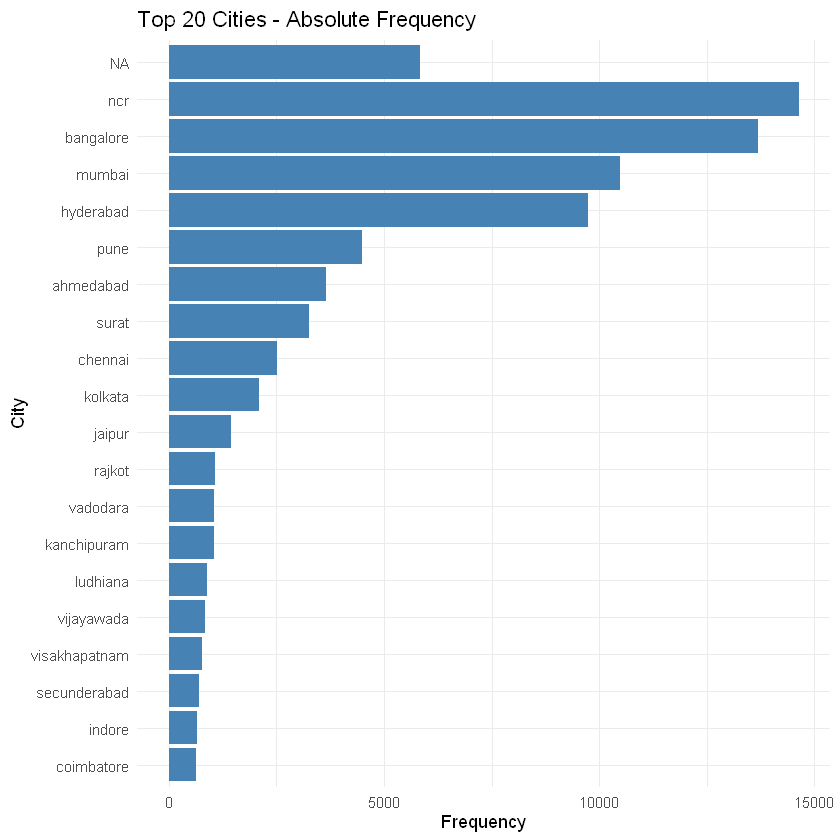

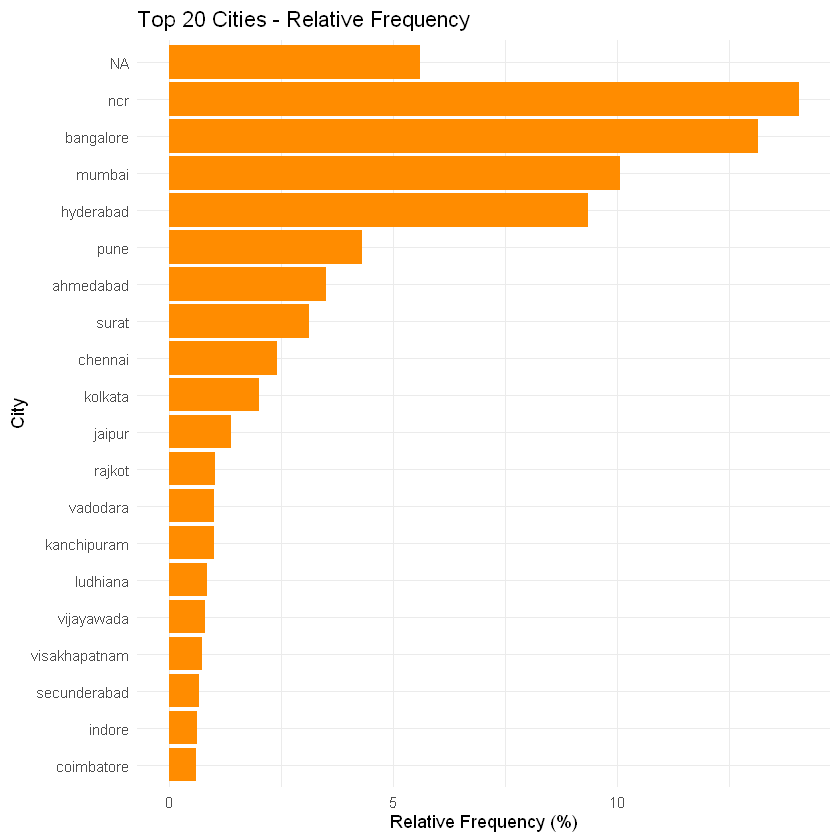

In [508]:
# save the top 20 cities in a new data frame
top20 <- city_count[1:20, ]

# plot the top 20 devices by absolute frequency
ggplot(top20, aes(x = reorder(city, frequency), y = frequency)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Top 20 Cities - Absolute Frequency",
    x = "City",
    y = "Frequency"
  ) +
  theme_minimal()

# plot the top 20 devices by relative frequency
ggplot(top20, aes(x = reorder(city, relative_frequency),
                  y = relative_frequency)) +
  geom_col(fill = "darkorange") +
  coord_flip() +
  labs(
    title = "Top 20 Cities - Relative Frequency",
    x = "City",
    y = "Relative Frequency (%)"
  ) +
  theme_minimal()

For the `city` variable, the top 10 cities do not account for as large a proportion of the observations as they do in the `device` variable. In this case, they account for 67.61% of the total observations. It is also worth examining the proportion of missing values (`NA`), which stands at approximately 5% and is among the highest across the variables.

The analysis continues with the binary variables `given_permission_1` and `given_permission_2`.

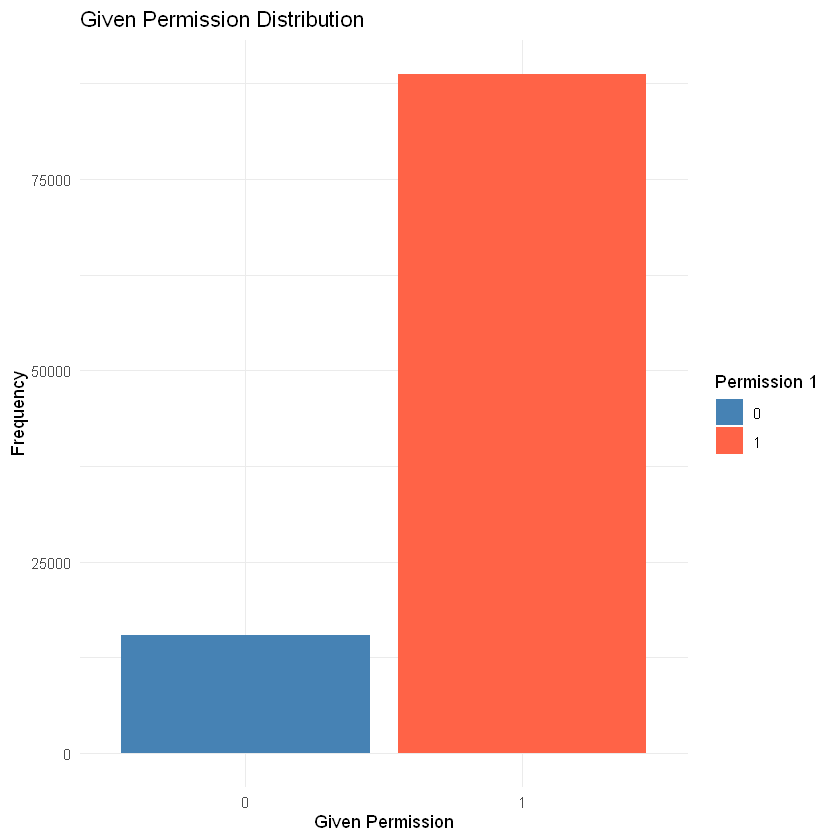

In [509]:
# given_permission_1 distribution
ggplot(data, aes(x = as.factor(given_permission_1),
                 fill = as.factor(given_permission_1))) +
  geom_bar() +
  scale_fill_manual(values = c("0" = "steelblue", "1" = "tomato")) +
  labs(
    title = "Given Permission Distribution",
    x = "Given Permission",
    y = "Frequency",
    fill = "Permission 1"
  ) +
  theme_minimal()

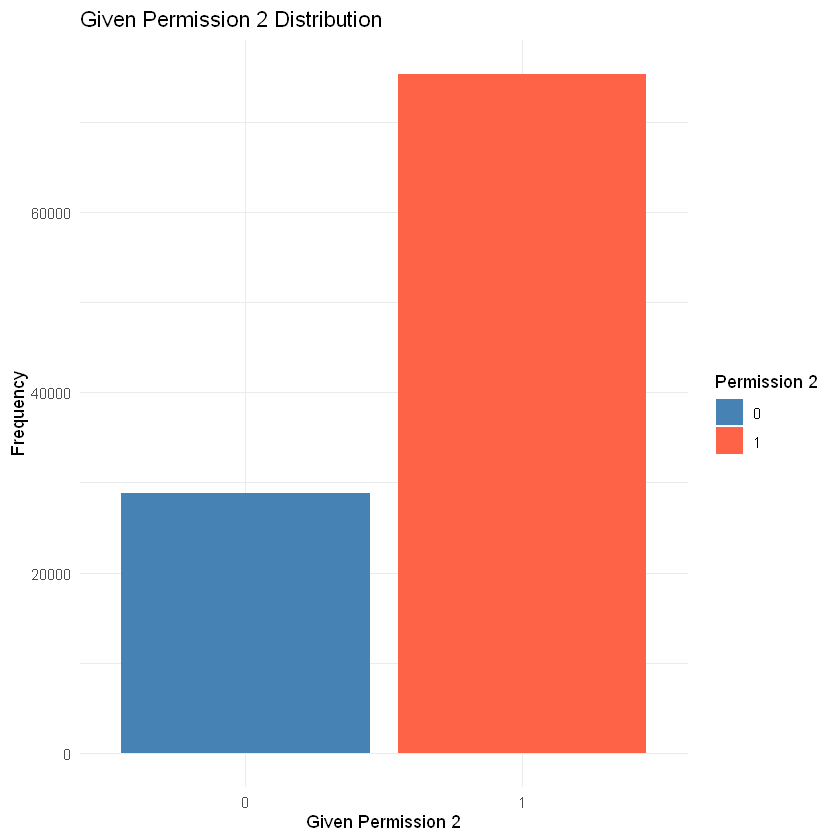

In [510]:
# given_permission_2 distribution
ggplot(data, aes(x = as.factor(given_permission_2),
                 fill = as.factor(given_permission_2))) +
  geom_bar() +
  scale_fill_manual(values = c("0" = "steelblue", "1" = "tomato")) +
  labs(
    title = "Given Permission 2 Distribution",
    x = "Given Permission 2",
    y = "Frequency",
    fill = "Permission 2"
  ) +
  theme_minimal()

In [511]:
given_permission_1_percentage <- round(sum(data$given_permission_1 == 1, na.rm = TRUE) / nrow(data) * 100, 2)
print(paste("Percentage of users who gave permission 1:", given_permission_1_percentage, "%"))

given_permission_2_percentage <- round(sum(data$given_permission_2 == 1, na.rm = TRUE) / nrow(data) * 100, 2)
print(paste("Percentage of users who gave permission 2:", given_permission_2_percentage, "%"))

[1] "Percentage of users who gave permission 1: 85.23 %"
[1] "Percentage of users who gave permission 2: 72.33 %"


It can be observed that 85.23% of users have granted permission type 1, while 72.33% have granted permission type 2. Therefore, both permissions show relatively high acceptance rates among users.

Finally, the `is_referral` variable is examined.

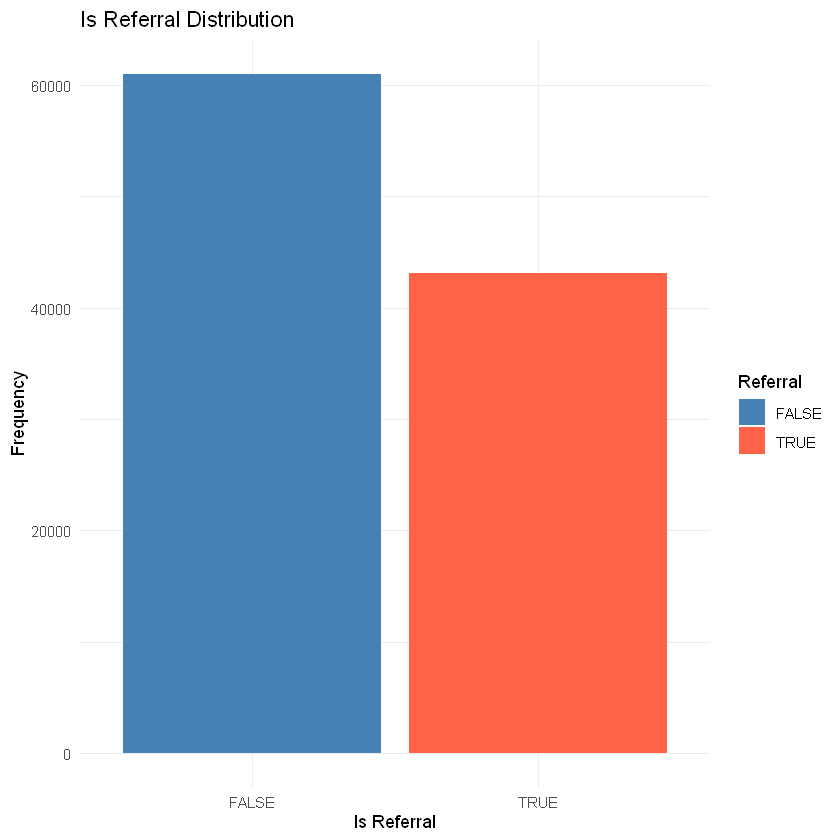

In [512]:
# is_referral distribution
ggplot(data, aes(x = as.factor(is_referral),
                 fill = as.factor(is_referral))) +
  geom_bar() +
  scale_fill_manual(values = c("FALSE" = "steelblue", "TRUE" = "tomato")) +
  labs(
    title = "Is Referral Distribution",
    x = "Is Referral",
    y = "Frequency",
    fill = "Referral"
  ) +
  theme_minimal()

In [513]:
is_referral_percentage <- round(sum(data$is_referral == TRUE, na.rm = TRUE) / nrow(data) * 100, 2)
print(paste("Percentage of users who are referrals:", is_referral_percentage, "%"))

[1] "Percentage of users who are referrals: 41.4 %"


It can be observed that 41.4% of users accessed the platform through a referral system, indicating that this acquisition channel has a significant presence within the user base.

The quantitative variables are now examined.

In [514]:
str(data)

'data.frame':	104143 obs. of  18 variables:
 $ device                               : chr  "samsung" "xiaomi" "xiaomi" "oneplus" ...
 $ first_payment_amount                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ age                                  : int  20 20 20 20 20 20 20 20 20 20 ...
 $ city                                 : chr  "ahmedabad" "surat" "kullu" "mumbai" ...
 $ number_of_cards                      : int  2 1 1 2 2 0 0 0 0 0 ...
 $ payments_initiated                   : int  1 1 2 4 1 1 1 17 1 1 ...
 $ payments_failed                      : int  0 0 1 1 0 0 0 0 0 0 ...
 $ payments_completed                   : int  1 1 1 2 1 1 1 12 1 1 ...
 $ payments_completed_amount_first_7days: int  0 0 0 322 0 0 0 143 0 0 ...
 $ reward_purchase_count_first_7days    : int  NA NA 0 2 0 0 0 6 0 NA ...
 $ coins_redeemed_first_7days           : int  0 0 0 20 0 0 0 190 0 0 ...
 $ is_referral                          : logi  FALSE TRUE TRUE FALSE FALSE TRUE ...
 $ visits_feature_1              

The quantitative variables are: `first_payment_amount`, `age`, `number_of_cards`, `payments_initiated`, `payments_failed`, `payments_completed`, `payments_completed_amount_first_7days`, `reward_purchase_count_first_7days`, `coins_redeemed_first_7days`, `visits_feature_1`, and `visits_feature_2`.

As can be seen, `user_id` is excluded because it is merely an identifier and does not contain relevant information for the analysis.

In [515]:
# save only the numeric variables in a new data frame
numeric_data <- data %>%
  select(
    first_payment_amount,
    age,
    number_of_cards,
    payments_initiated,
    payments_failed,
    payments_completed,
    payments_completed_amount_first_7days,
    reward_purchase_count_first_7days,
    coins_redeemed_first_7days,
    visits_feature_1,
    visits_feature_2
  )

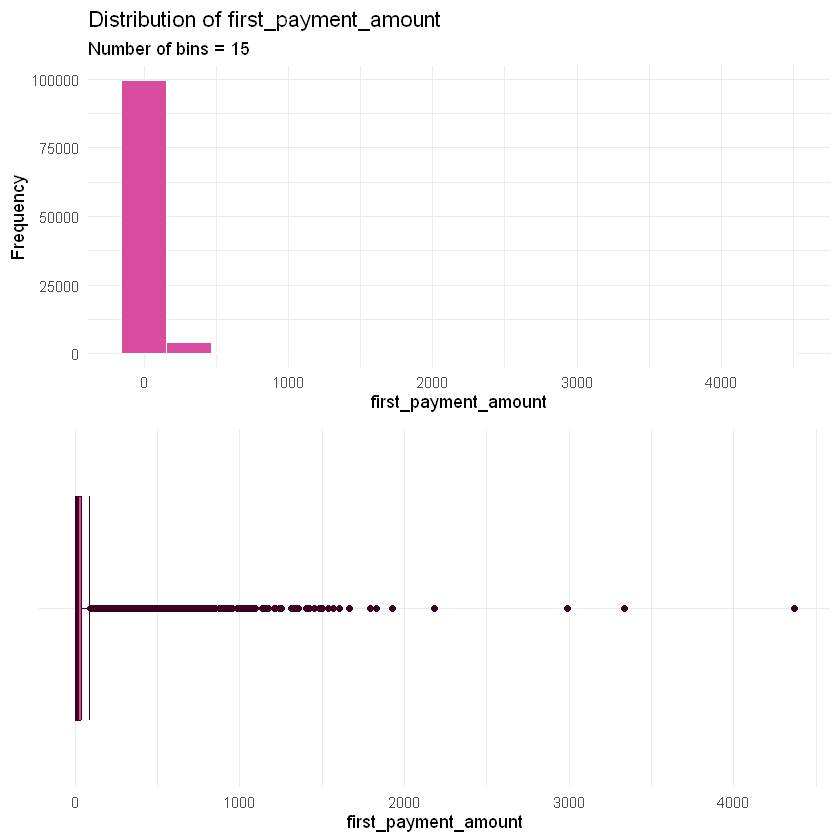

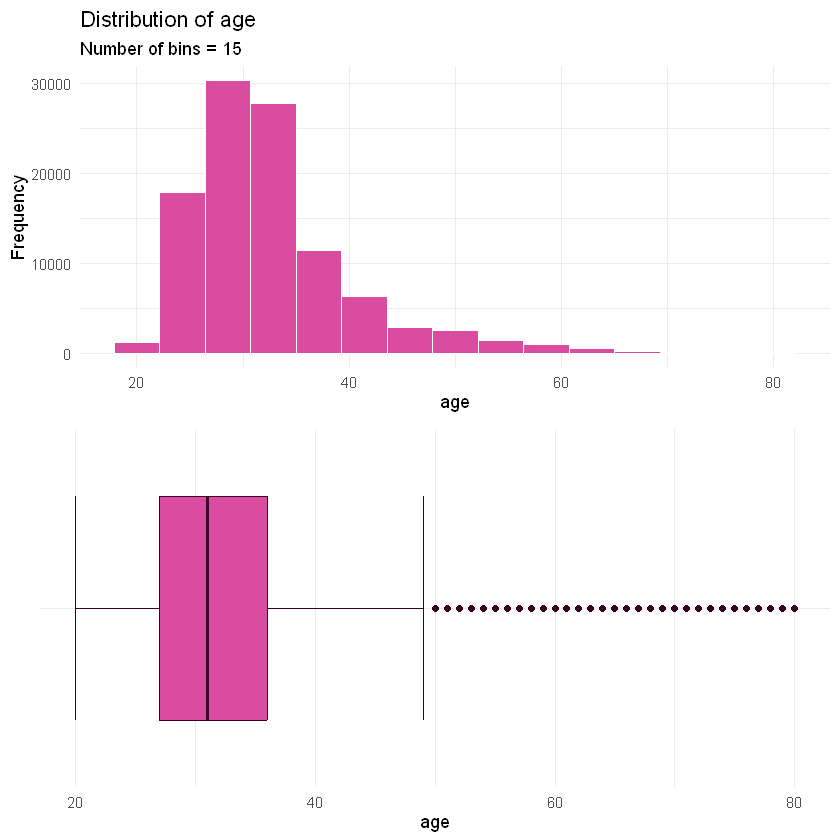

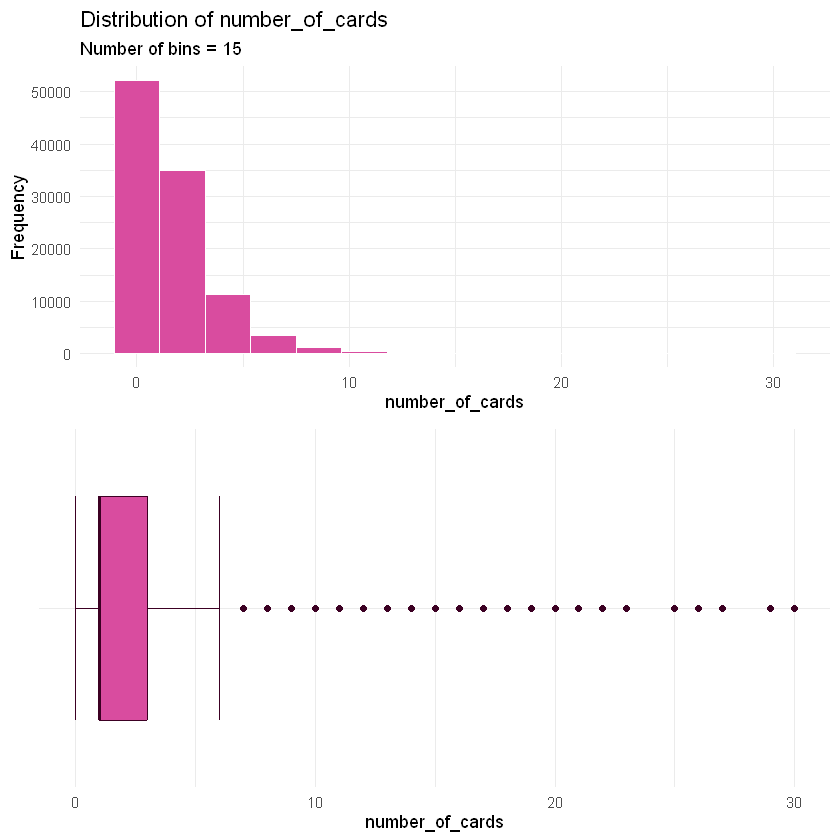

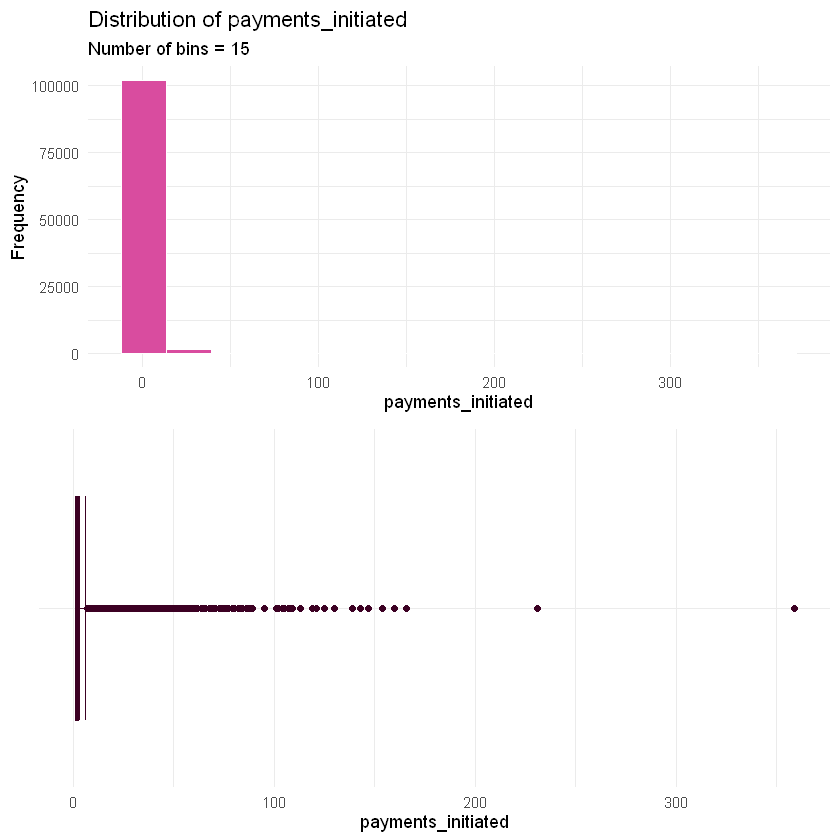

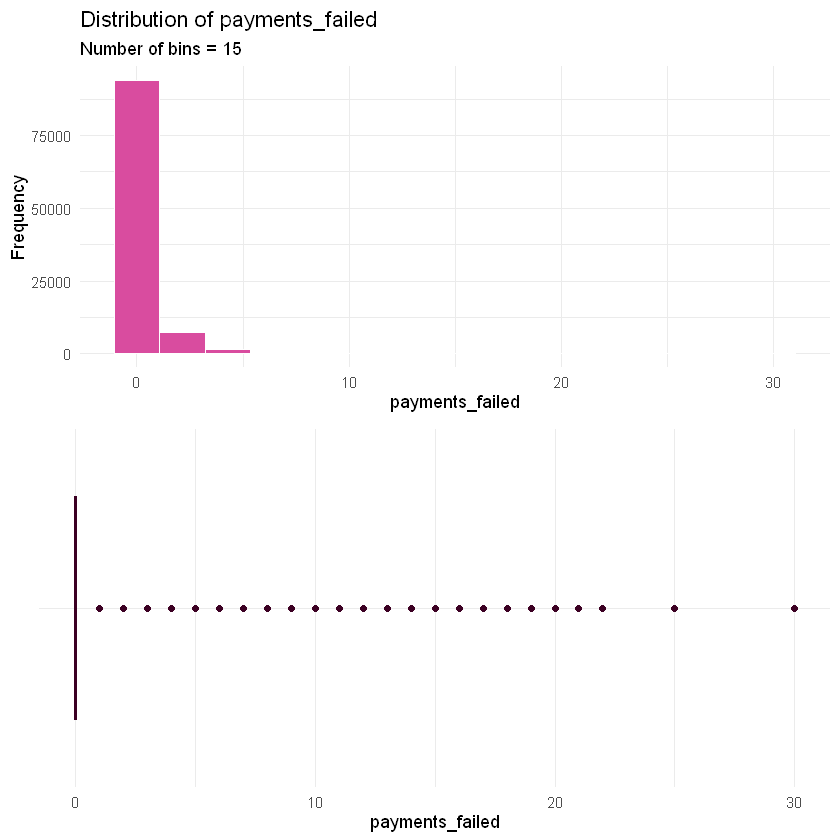

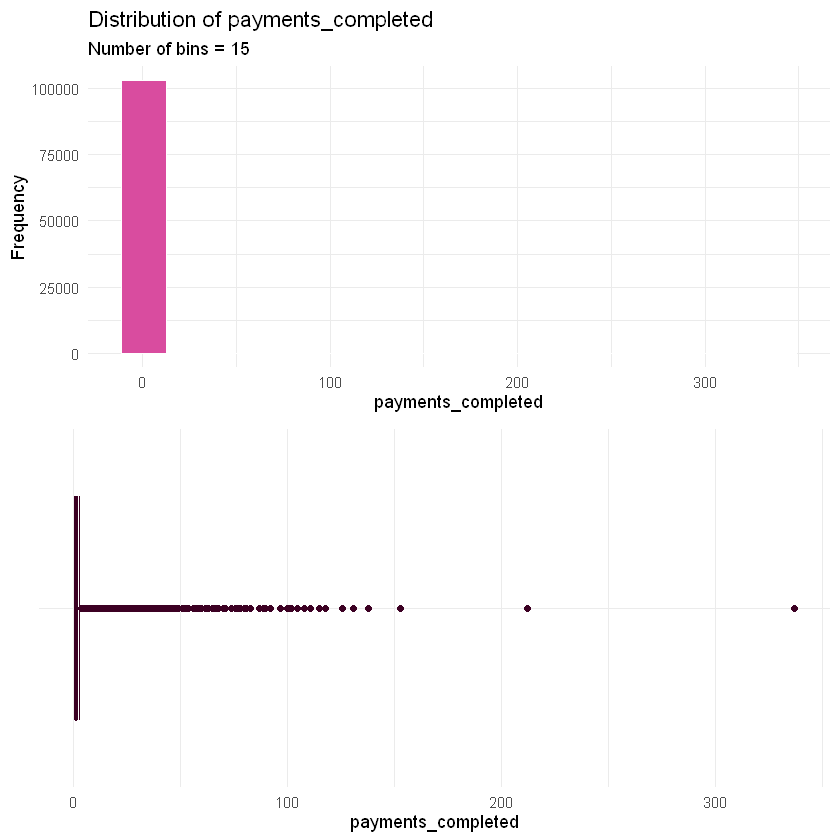

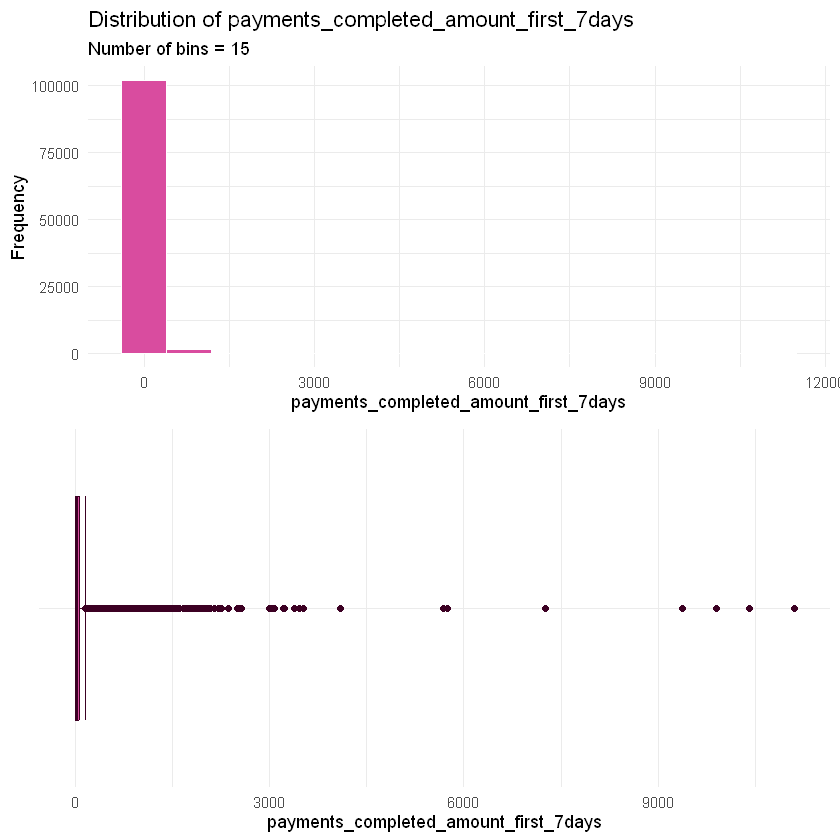

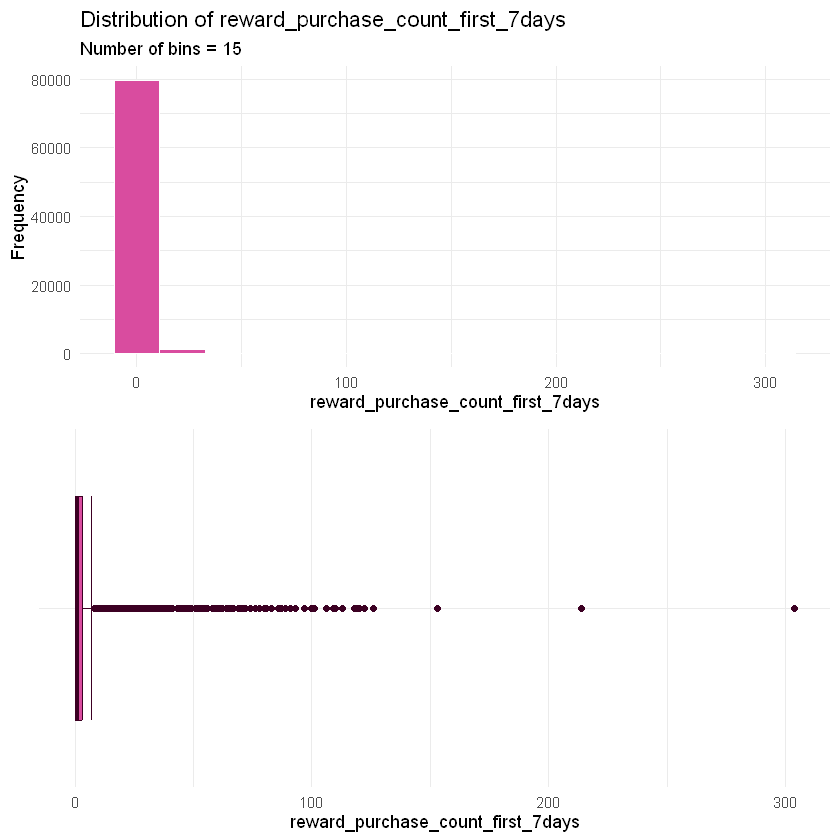

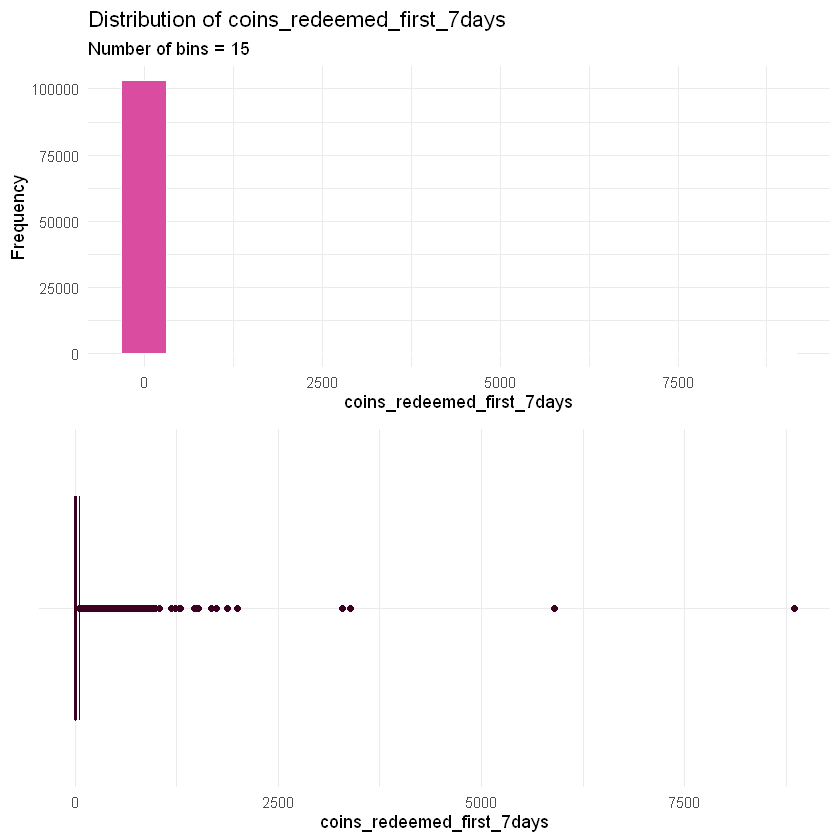

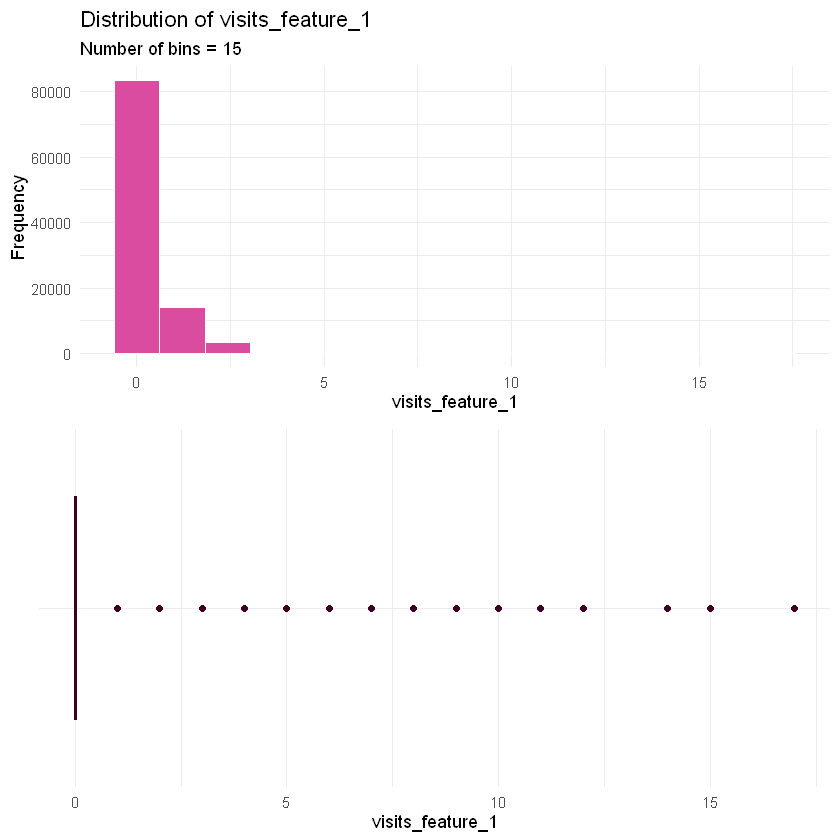

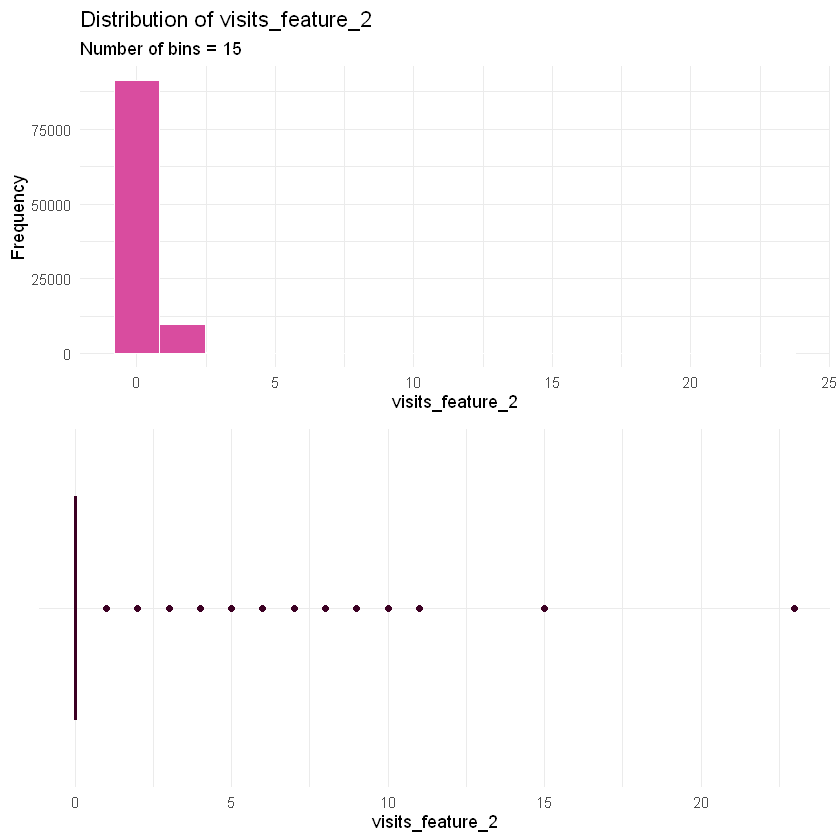

In [516]:
# generate histograms and boxplots for each numeric variable
plots <- map(names(numeric_data), function(variable) {

  a <- ggplot(data, aes(x = .data[[variable]])) +
    geom_histogram(
      bins = 15,
      fill = "#d94c9f",
      color = "white",
      na.rm = TRUE
    ) +
    labs(
      title = paste("Distribution of", variable),
      subtitle = "Number of bins = 15",
      x = variable,
      y = "Frequency"
    ) +
    theme_minimal()

  b <- ggplot(data, aes(x = "", y = .data[[variable]])) +
    stat_boxplot(
      geom = "errorbar",
      color = "#3c0023",
      na.rm = TRUE
    ) +
    geom_boxplot(
      fill = "#d94c9f",
      color = "#3c0023",
      na.rm = TRUE
    ) +
    coord_flip() +
    labs(x = "", y = variable) +
    theme_minimal()

  grid.arrange(a, b, ncol = 1)
})

Strong positive skewness can be observed in the histograms of the quantitative variables, with a high concentration of observations close to zero and a long tail extending towards higher values. This distribution is also reflected in the boxplots, where relatively narrow boxes and a large number of points above the upper whiskers stand out. This indicates a high concentration of low values and a small proportion of observations with considerably higher values.

The only variable that does not exhibit such strong skewness is `age`, where the minimum age appears to be 20 years. This makes sense given that the dataset contains customers of a telecommunications company, so individuals under the age of 18 would not be expected.

### Relationships between the independent and dependent variables

#### Qualitative Variables

First, an analysis is conducted to examine how the categorical variables relate to `is_churned`.

In [517]:
device_churn_rate <- data %>%
  group_by(device) %>%
  summarise(
    total_users = n(),
    churn_rate = mean(is_churned, na.rm = TRUE)
  ) %>%
  arrange(desc(total_users))

print(device_churn_rate)

# A tibble: 76 × 3
   device     total_users churn_rate
   <chr>            <int>      <dbl>
 1 xiaomi           25009      0.296
 2 samsung          16657      0.313
 3 apple            15811      0.245
 4 oneplus          14613      0.202
 5 vivo              8523      0.394
 6 oppo              7093      0.359
 7 realme            3615      0.228
 8 motorola          3378      0.286
 9 huawei            3226      0.290
10 hmd global        1745      0.270
# ℹ 66 more rows


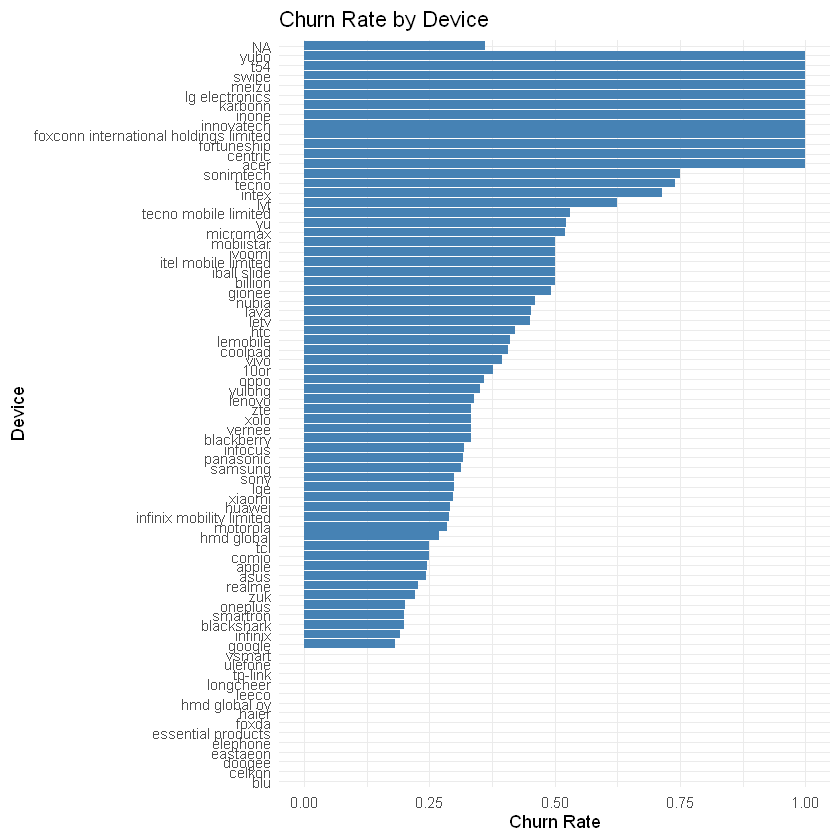

In [518]:
ggplot(device_churn_rate, aes(x = reorder(device, churn_rate), y = churn_rate)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Churn Rate by Device",
    x = "Device",
    y = "Churn Rate"
  ) +
  theme_minimal()

It can be observed that some brands have a very high *churn rate*. However, it is necessary to check whether this is due to the small number of users associated with those brands.

In [519]:
device_churn_rate_1 <- device_churn_rate %>%
    filter(churn_rate == 1)

print(device_churn_rate_1)

# A tibble: 12 × 3
   device                                 total_users churn_rate
   <chr>                                        <int>      <dbl>
 1 meizu                                            4          1
 2 acer                                             2          1
 3 foxconn international holdings limited           2          1
 4 lg electronics                                   2          1
 5 centric                                          1          1
 6 fortuneship                                      1          1
 7 innovatech                                       1          1
 8 inone                                            1          1
 9 karbonn                                          1          1
10 swipe                                            1          1
11 t54                                              1          1
12 yuho                                             1          1


It is confirmed that these brands have a very low number of users, meaning that their high churn rates could simply be due to chance. It would therefore be misleading to generalize these results to all users of these brands.

`geom_smooth()` using formula = 'y ~ x'


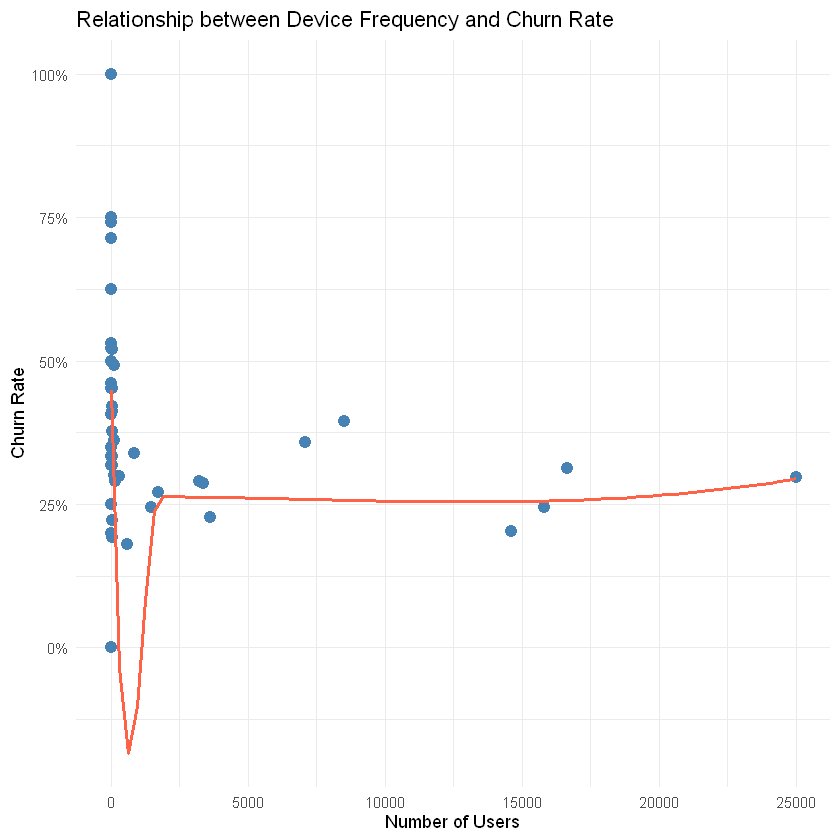

In [520]:
ggplot(device_churn_rate,
       aes(x = total_users, y = churn_rate)) +
  geom_point(size = 3, color = "steelblue") +
  geom_smooth(method = "loess", se = FALSE, color = "tomato") +
  labs(
    title = "Relationship between Device Frequency and Churn Rate",
    x = "Number of Users",
    y = "Churn Rate"
  ) +
  scale_y_continuous(labels = scales::percent) +
  theme_minimal()

This chart is particularly interesting because it shows that, for devices with a large number of users, the *churn rate* remains relatively stable. In contrast, for devices with fewer users, the *churn rate* becomes highly variable due to the small sample size.

Since the `city` variable follows a similar pattern, the same methodology is applied.

In [521]:
city_churn_rate <- data %>%
  group_by(city) %>%
  summarise(
    total_users = n(),
    churn_rate = mean(is_churned, na.rm = TRUE)
  ) %>%
  arrange(desc(total_users))

print(city_churn_rate)

# A tibble: 723 × 3
   city      total_users churn_rate
   <chr>           <int>      <dbl>
 1 ncr             14642      0.237
 2 bangalore       13696      0.196
 3 mumbai          10480      0.222
 4 hyderabad        9746      0.271
 5 NA               5842      0.425
 6 pune             4484      0.233
 7 ahmedabad        3643      0.449
 8 surat            3262      0.614
 9 chennai          2517      0.264
10 kolkata          2102      0.235
# ℹ 713 more rows


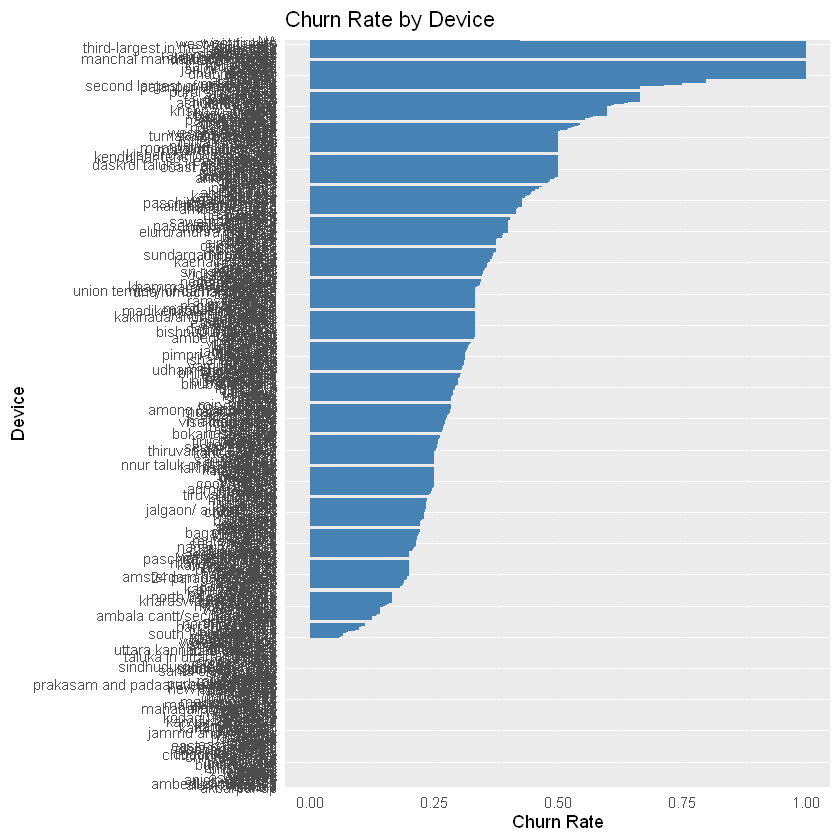

In [522]:
ggplot(city_churn_rate, aes(x = reorder(city, churn_rate), y = churn_rate)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Churn Rate by Device",
    x = "Device",
    y = "Churn Rate"
  ) +
  theme_minimal()

`geom_smooth()` using formula = 'y ~ x'


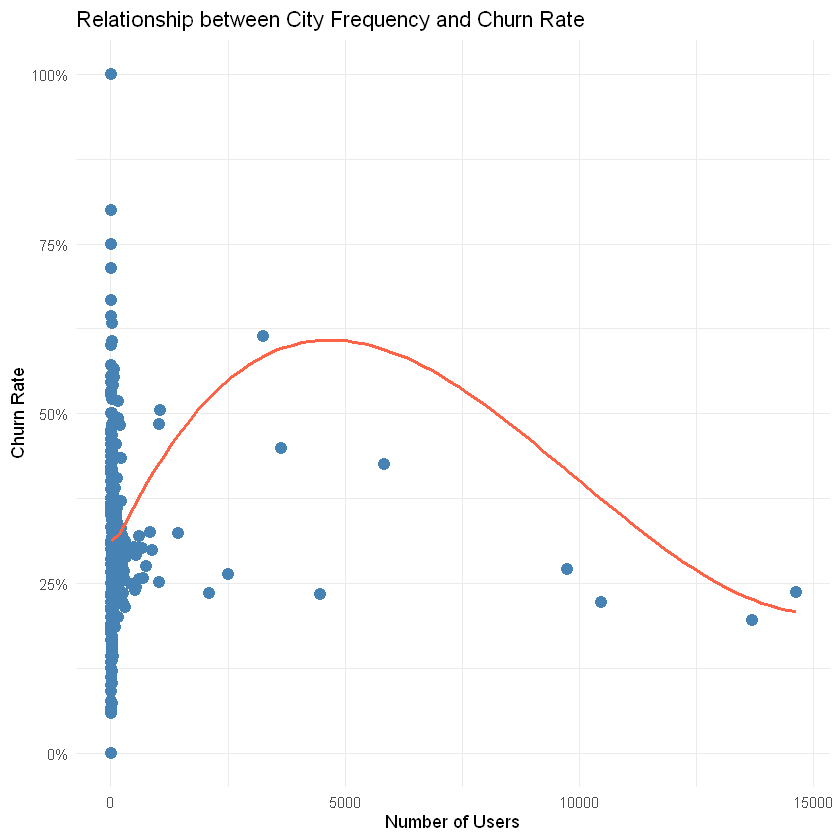

In [523]:
ggplot(city_churn_rate,
       aes(x = total_users, y = churn_rate)) +
  geom_point(size = 3, color = "steelblue") +
  geom_smooth(method = "loess", se = FALSE, color = "tomato") +
  labs(
    title = "Relationship between City Frequency and Churn Rate",
    x = "Number of Users",
    y = "Churn Rate"
  ) +
  scale_y_continuous(labels = scales::percent) +
  theme_minimal()

For the `city` variable, exactly the same pattern can be observed: high variability in the *churn rate* for cities with very few users. Furthermore, the large number of distinct cities makes this issue even more significant.

In summary, it is very difficult to establish a relationship between churn and the `city` and `device` variables due to the large number of existing categories and the low frequency of many of them.

Next, the relationship between `is_referral` and churn is examined. This is an interesting relationship to explore, given the large proportion of users acquired through referrals.

In [524]:
is_referral_churn <- data %>%
  group_by(is_referral) %>%
  summarise(
    total_users = n(),
    churn_rate = mean(is_churned, na.rm = TRUE)
  ) %>%
  arrange(desc(total_users))

print(is_referral_churn)

# A tibble: 2 × 3
  is_referral total_users churn_rate
  <lgl>             <int>      <dbl>
1 FALSE             61024      0.245
2 TRUE              43119      0.346


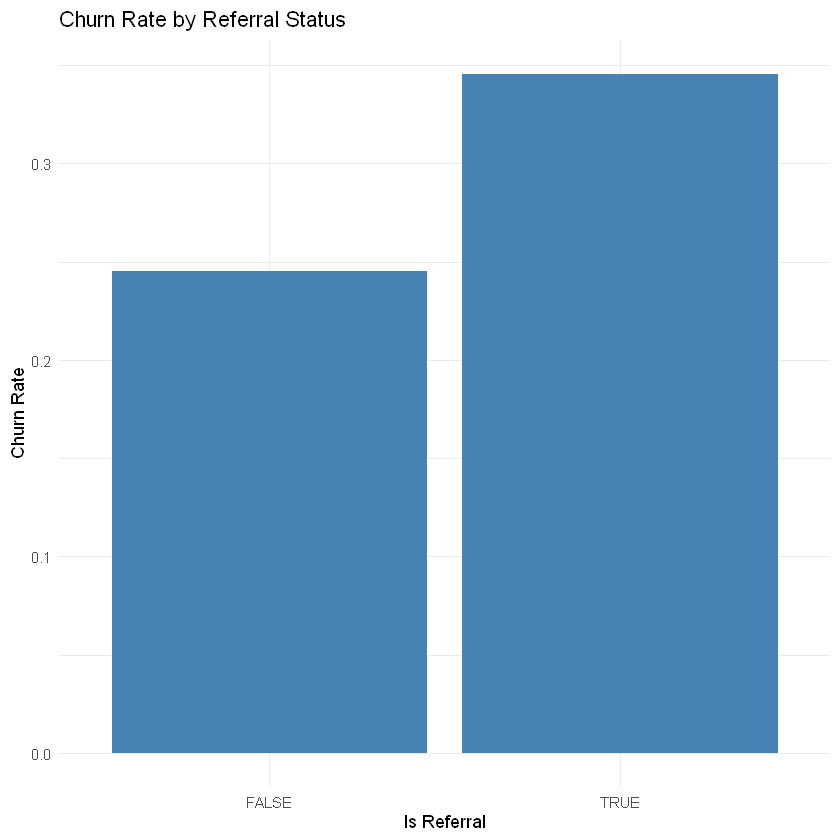

In [525]:
ggplot(is_referral_churn, aes(x = as.factor(is_referral), y = churn_rate)) +
  geom_col(fill = "steelblue") +
  labs(
    title = "Churn Rate by Referral Status",
    x = "Is Referral",
    y = "Churn Rate"
  ) +
  theme_minimal()

In [526]:
difference_in_churn_rate_percentage <- abs(diff(is_referral_churn$churn_rate)) * 100
print(paste("Difference in churn rate between referral and non-referral users:", round(difference_in_churn_rate_percentage, 2), "%"))

[1] "Difference in churn rate between referral and non-referral users: 10.04 %"


A significant difference can be observed in churn rates depending on the acquisition channel. Users acquired through referrals show a churn rate of 34.6%, compared to 24.5% for users who were not acquired through this channel. This represents a difference of 10.04 percentage points.

Furthermore, both categories have a high number of observations (61,024 non-referred users and 43,119 referred users), allowing for a more robust comparison of their churn rates.

This result is interesting, as it seems to indicate that the acquisition channel may be related to users' churn behavior.

Next, the relationships between churn and the permission variables `given_permission_1` and `given_permission_2` are examined.

Four possible cases can be distinguished:

1. The user has neither permission.
2. The user has permission 1 only.
3. The user has permission 2 only.
4. The user has both permissions.

In [527]:
permissions <- data %>%
  mutate(
    permission_group = case_when(
      given_permission_1 == FALSE & given_permission_2 == FALSE ~ "None",
      given_permission_1 == TRUE & given_permission_2 == FALSE ~ "Only permission 1",
      given_permission_1 == FALSE & given_permission_2 == TRUE ~ "Only permission 2",
      given_permission_1 == TRUE & given_permission_2 == TRUE ~ "Both permissions",
      TRUE ~ NA_character_
    )
  )

head(permissions)

,device,first_payment_amount,age,city,number_of_cards,payments_initiated,payments_failed,payments_completed,payments_completed_amount_first_7days,reward_purchase_count_first_7days,coins_redeemed_first_7days,is_referral,visits_feature_1,visits_feature_2,given_permission_1,given_permission_2,user_id,is_churned,permission_group
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<lgl>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>
1,samsung,0,20,ahmedabad,2,1,0,1,0,NA,0,FALSE,3,0,1,0,269438,0,Only permission 1
2,xiaomi,0,20,surat,1,1,0,1,0,NA,0,TRUE,0,0,1,0,139521,0,Only permission 1
3,xiaomi,0,20,kullu,1,2,1,1,0,0,0,TRUE,0,0,0,1,307352,0,Only permission 2
4,oneplus,0,20,mumbai,2,4,1,2,322,2,20,FALSE,0,0,1,1,456424,0,Both permissions
5,apple,0,20,pune,2,1,0,1,0,0,0,FALSE,0,1,1,1,398779,0,Both permissions
6,oppo,0,20,ahmedabad,0,1,0,1,0,0,0,TRUE,0,0,1,1,136656,0,Both permissions


In [528]:
permission_churn <- permissions %>%
  group_by(permission_group) %>%
  summarise(
    total_users = n(),
    churn_rate = mean(is_churned, na.rm = TRUE) * 100
  ) %>%
  arrange(desc(churn_rate))

print(permission_churn)

# A tibble: 4 × 3
  permission_group  total_users churn_rate
  <chr>                   <int>      <dbl>
1 None                     7610       44.4
2 Only permission 1       21203       34.9
3 Only permission 2        7770       30.8
4 Both permissions        67560       24.7


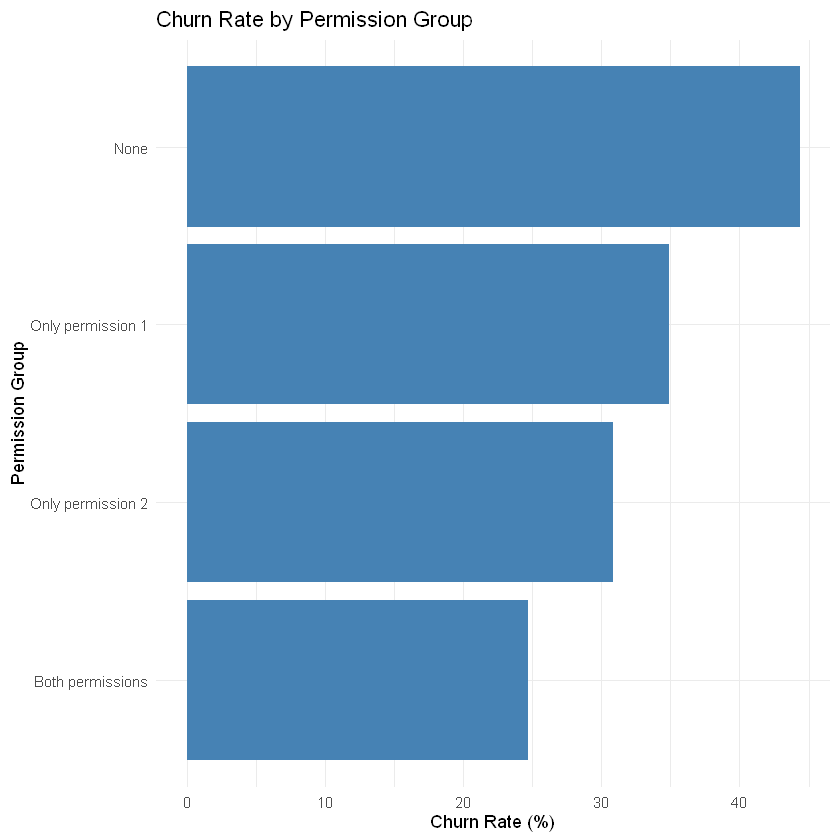

In [529]:
ggplot(permission_churn,
       aes(x = reorder(permission_group, churn_rate),
           y = churn_rate)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Churn Rate by Permission Group",
    x = "Permission Group",
    y = "Churn Rate (%)"
  ) +
  theme_minimal()

When analyzing the chart, a progressive reduction in the churn rate can be observed as the number of permissions granted increases. Particularly noteworthy is that users who have granted both permissions show a churn rate close to half that of users who have not granted either permission.

A difference can also be observed between the two individual permissions, with the churn rate of users who have granted only permission 2 being lower than that of users who have granted only permission 1.

These results could indicate an association between the number of permissions granted and users' churn behavior. However, they do not establish a causal relationship or allow us to conclude that granting more permissions directly reduces the probability of churn.

It is worth noting that the four groups have different sample sizes. Although this does not invalidate the comparison, it is important to consider the size of each group when interpreting the churn rates, since estimates based on smaller samples may have greater uncertainty.

To conclude the analysis of the relationships between the categorical variables and `is_churned`, the `age` variable is converted into categories to examine whether different age groups are associated with churn.

In [530]:
age_cathegorical <- data %>%
  mutate(
    age_category = case_when(
      age >= 18 & age <= 25 ~ "18-25",
      age >= 26 & age <= 35 ~ "26-35",
      age >= 36 & age <= 45 ~ "36-45",
      age >= 46 & age <= 55 ~ "46-55",
      age >= 56 & age <= 65 ~ "56-65",
      age > 65 ~ "Over 65",
      TRUE ~ NA_character_
    )
  )

head(age_cathegorical)

,device,first_payment_amount,age,city,number_of_cards,payments_initiated,payments_failed,payments_completed,payments_completed_amount_first_7days,reward_purchase_count_first_7days,coins_redeemed_first_7days,is_referral,visits_feature_1,visits_feature_2,given_permission_1,given_permission_2,user_id,is_churned,age_category
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<lgl>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>
1,samsung,0,20,ahmedabad,2,1,0,1,0,NA,0,FALSE,3,0,1,0,269438,0,18-25
2,xiaomi,0,20,surat,1,1,0,1,0,NA,0,TRUE,0,0,1,0,139521,0,18-25
3,xiaomi,0,20,kullu,1,2,1,1,0,0,0,TRUE,0,0,0,1,307352,0,18-25
4,oneplus,0,20,mumbai,2,4,1,2,322,2,20,FALSE,0,0,1,1,456424,0,18-25
5,apple,0,20,pune,2,1,0,1,0,0,0,FALSE,0,1,1,1,398779,0,18-25
6,oppo,0,20,ahmedabad,0,1,0,1,0,0,0,TRUE,0,0,1,1,136656,0,18-25


In [531]:
age_cathegories_churn <- age_cathegorical %>%
  group_by(age_category) %>%
  summarise(
    total_users = n(),
    churn_rate = mean(is_churned, na.rm = TRUE) * 100
  ) %>%
  arrange(desc(churn_rate))

print(age_cathegories_churn)

# A tibble: 7 × 3
  age_category total_users churn_rate
  <chr>              <int>      <dbl>
1 Over 65              408       43.1
2 56-65               1936       41.5
3 46-55               4919       39.5
4 NA                   142       36.6
5 36-45              19499       29.6
6 18-25              12741       29.1
7 26-35              64498       27.0


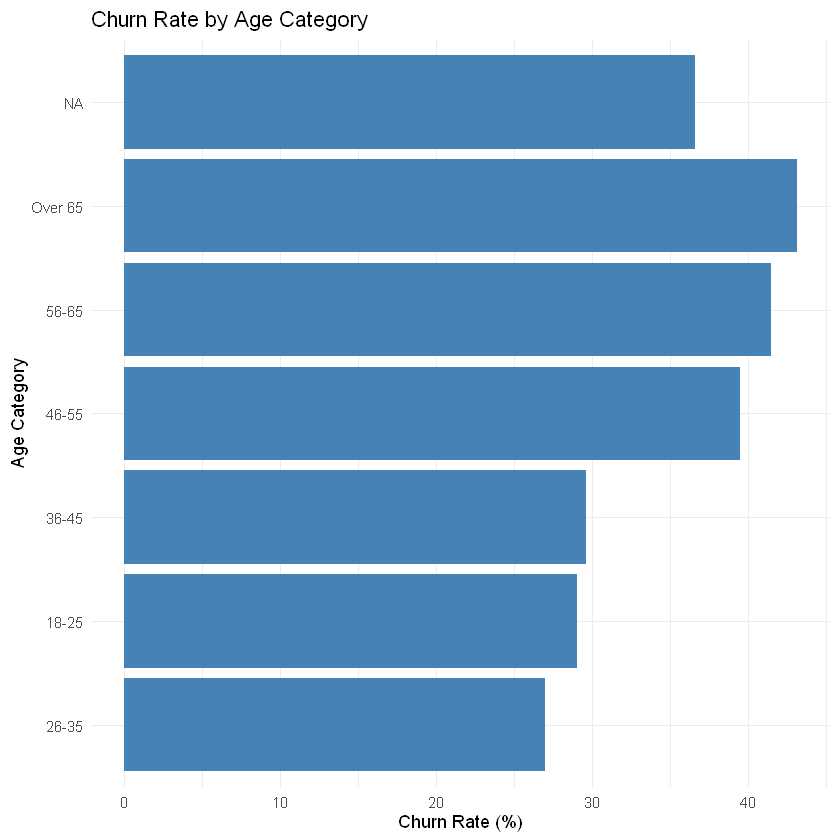

In [532]:
ggplot(age_cathegories_churn,
       aes(x = reorder(age_category, churn_rate),
           y = churn_rate)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Churn Rate by Age Category",
    x = "Age Category",
    y = "Churn Rate (%)"
  ) +
  theme_minimal()

A higher churn rate stands out among older users, while lower rates are observed in younger age groups. The age group with the highest *churn rate* is users over 65, whereas the group with the lowest *churn rate* is users aged 26–35.

#### Quantitative variables

The relationships between `is_churned` and the quantitative variables are examined using boxplots.

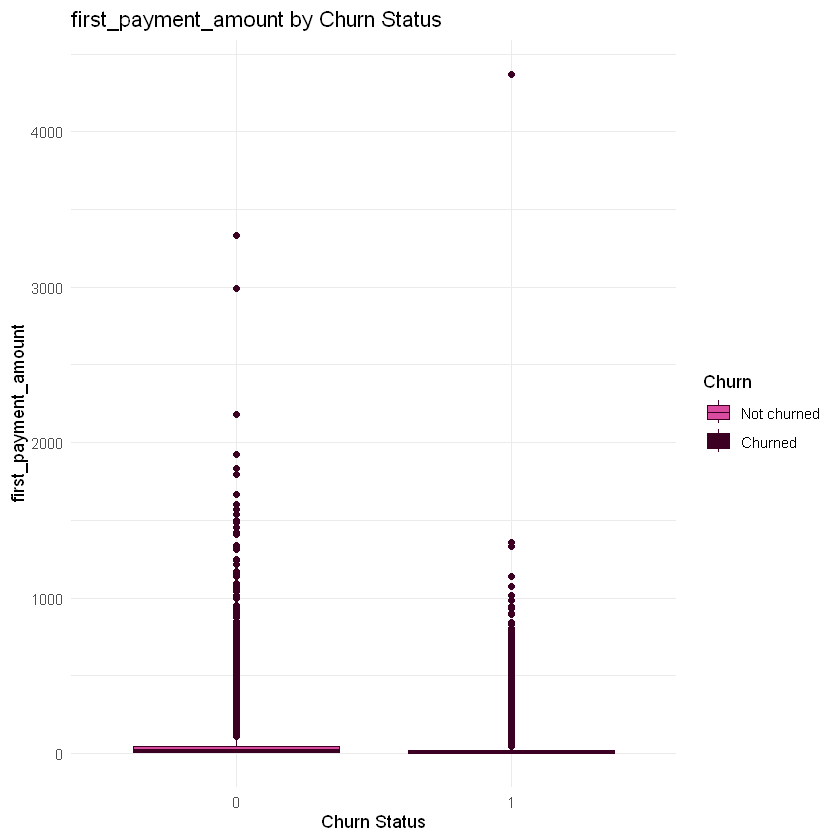

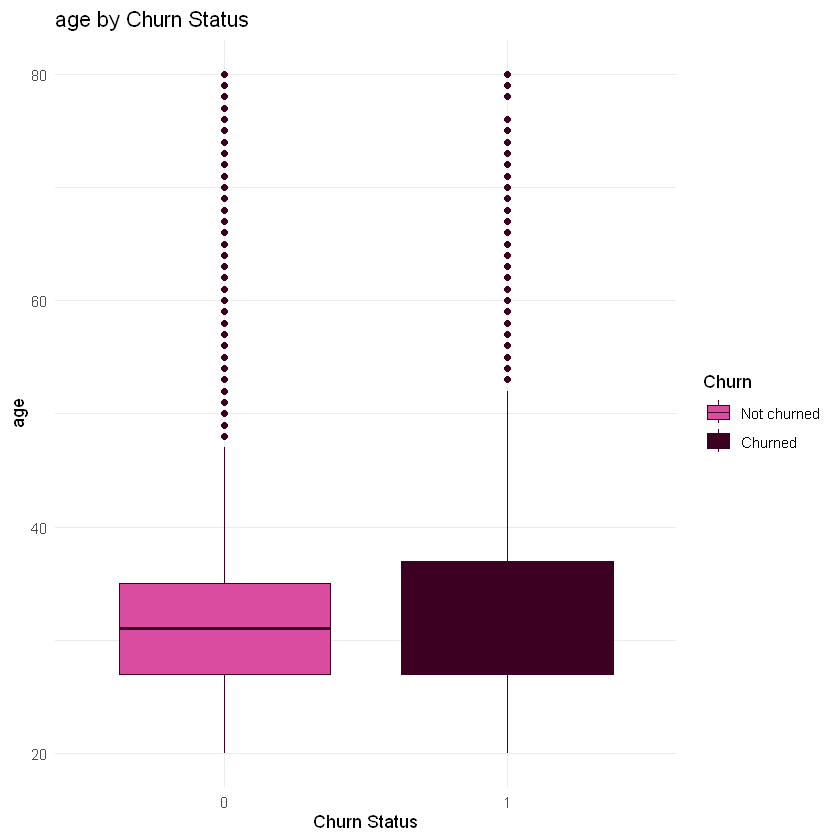

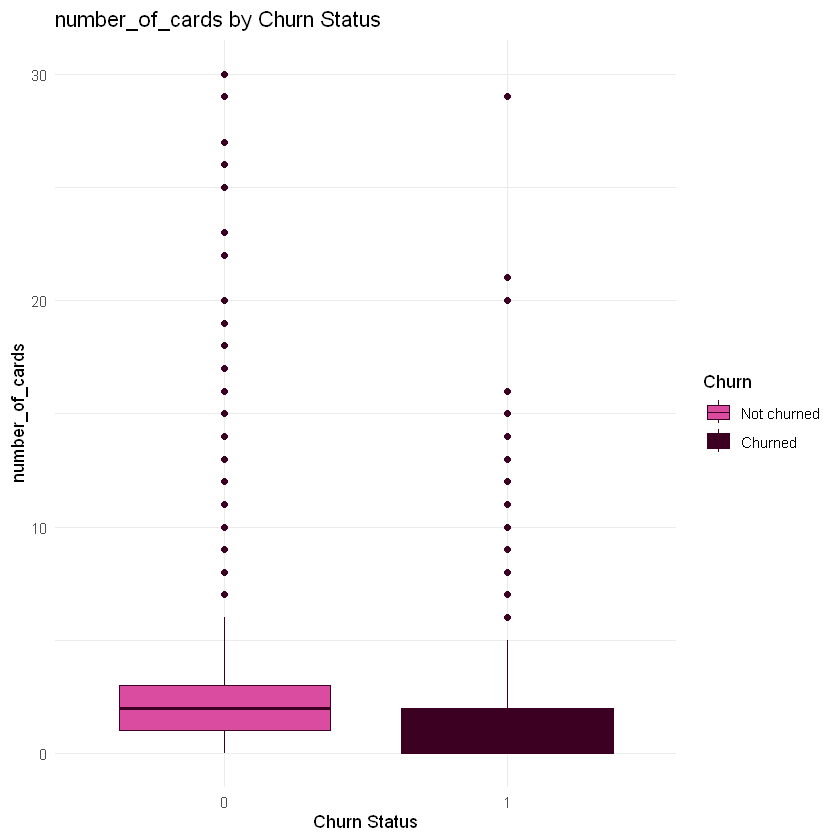

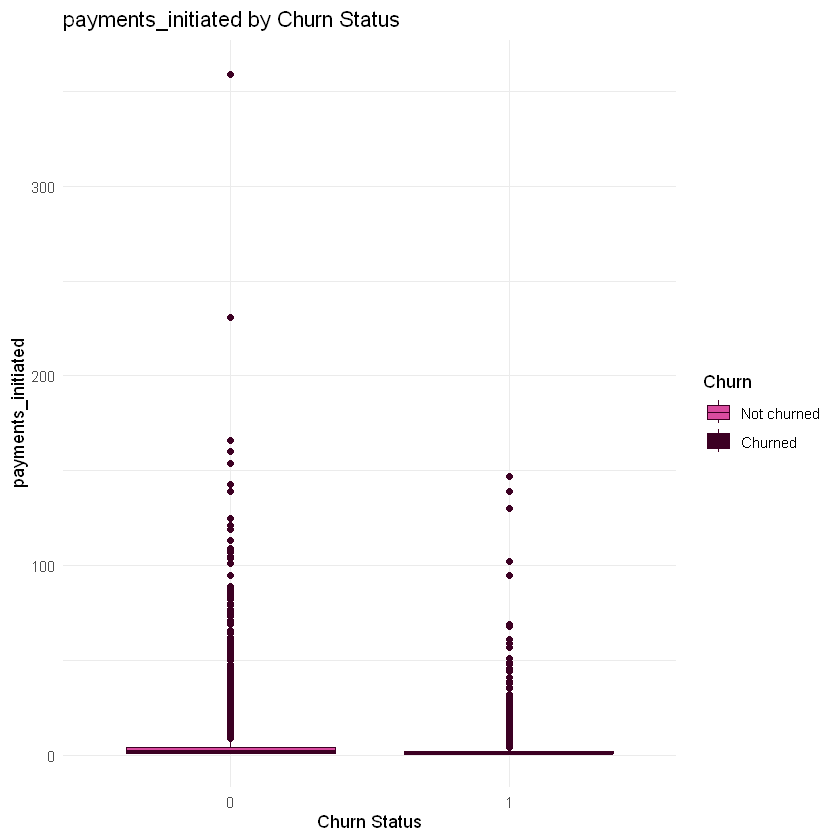

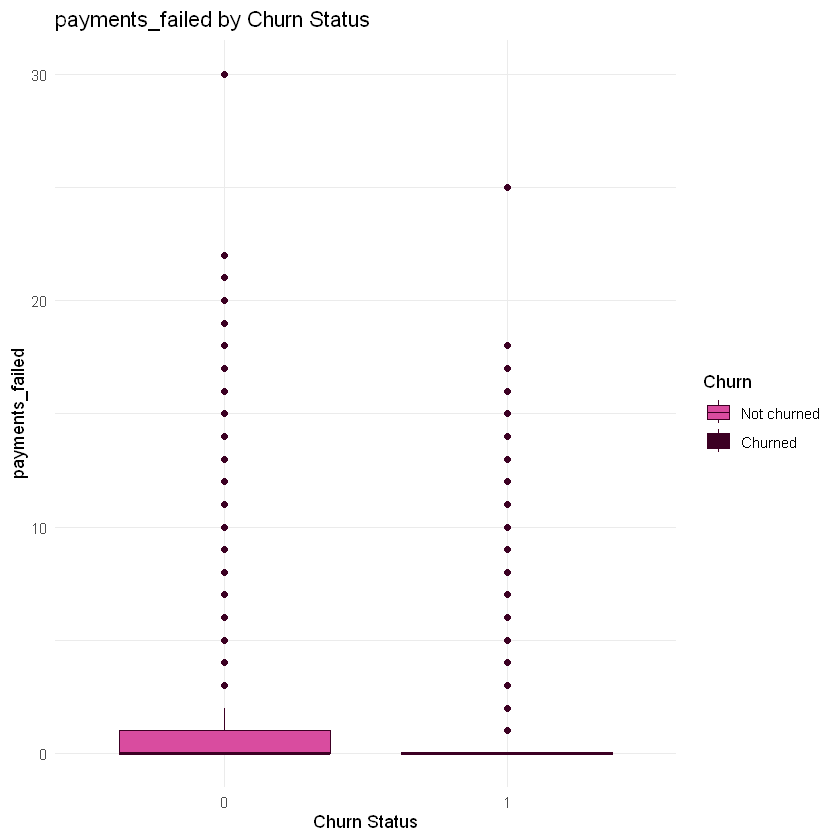

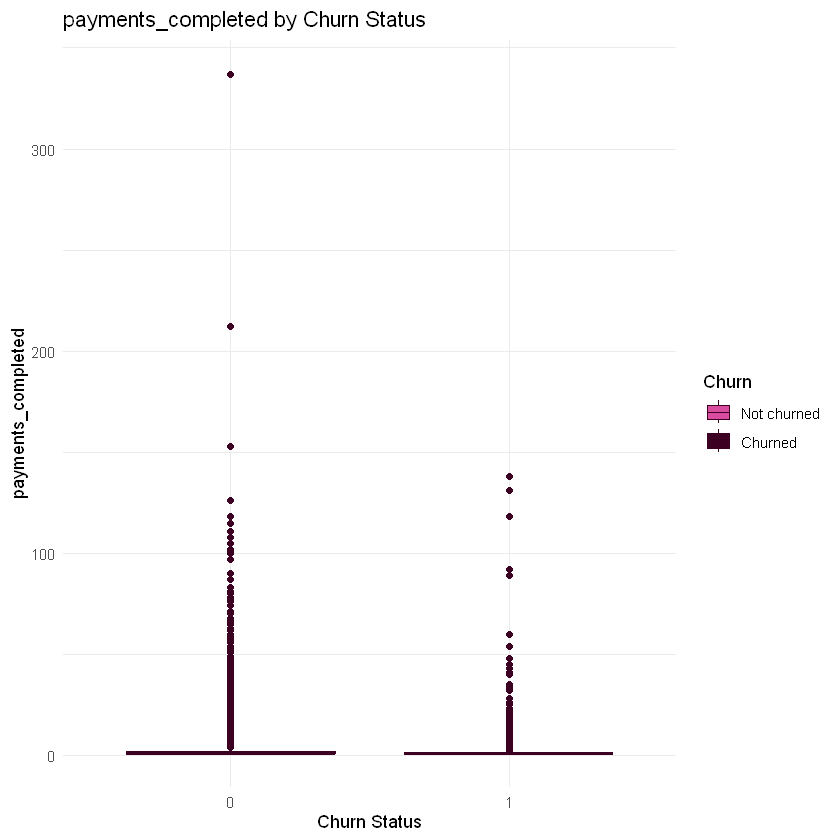

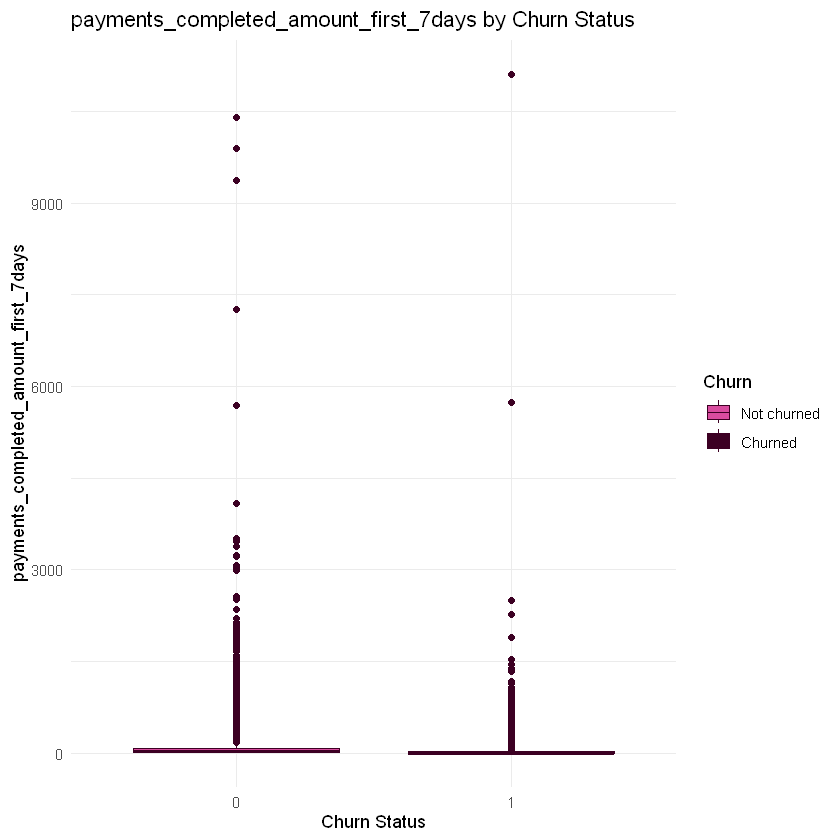

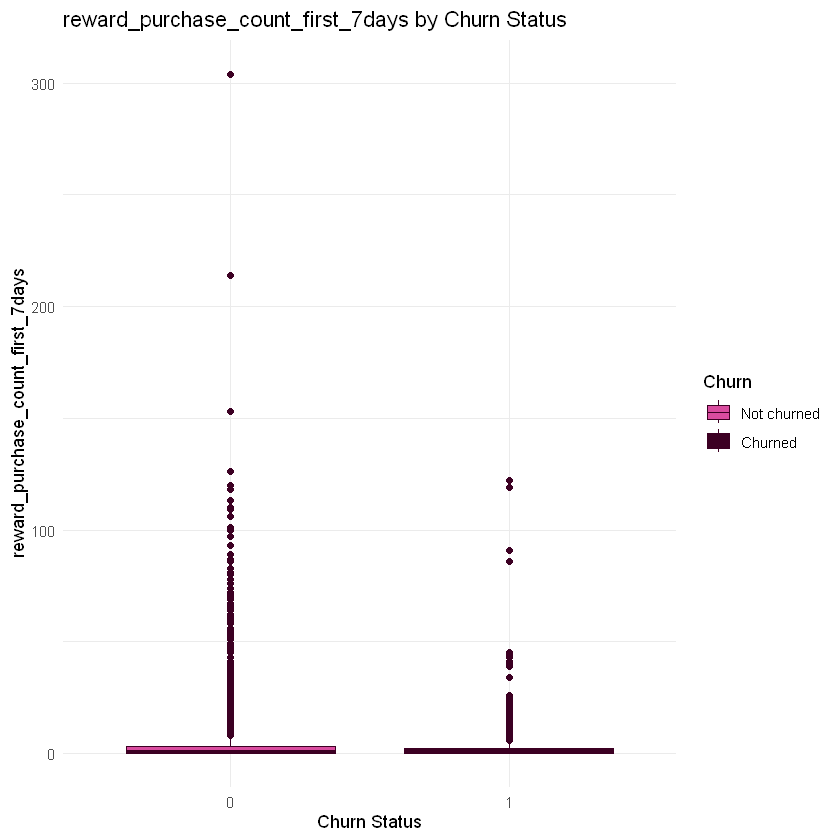

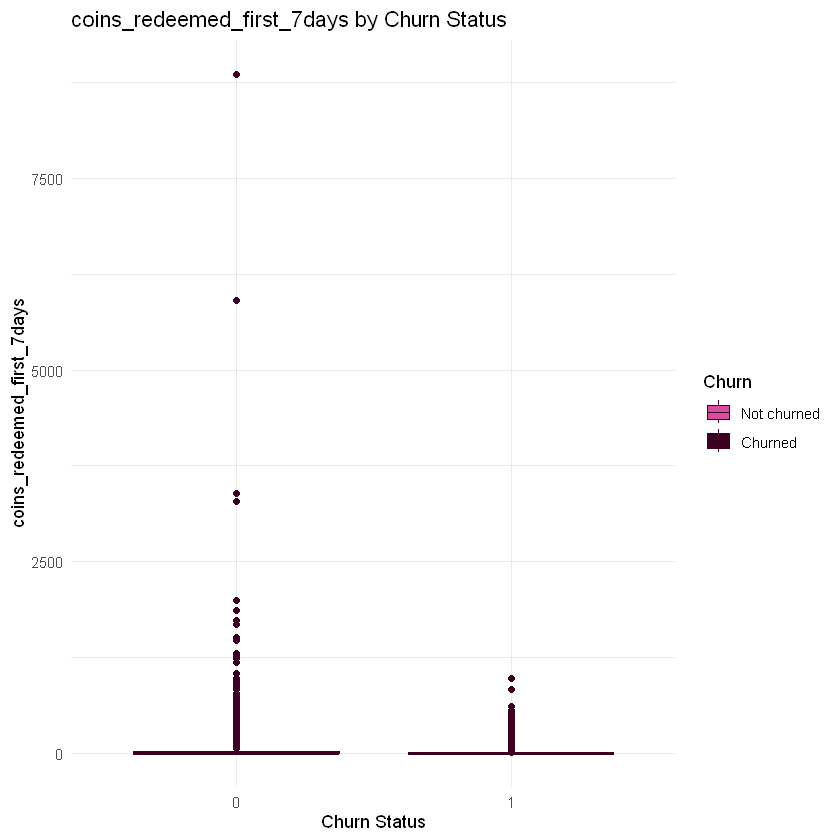

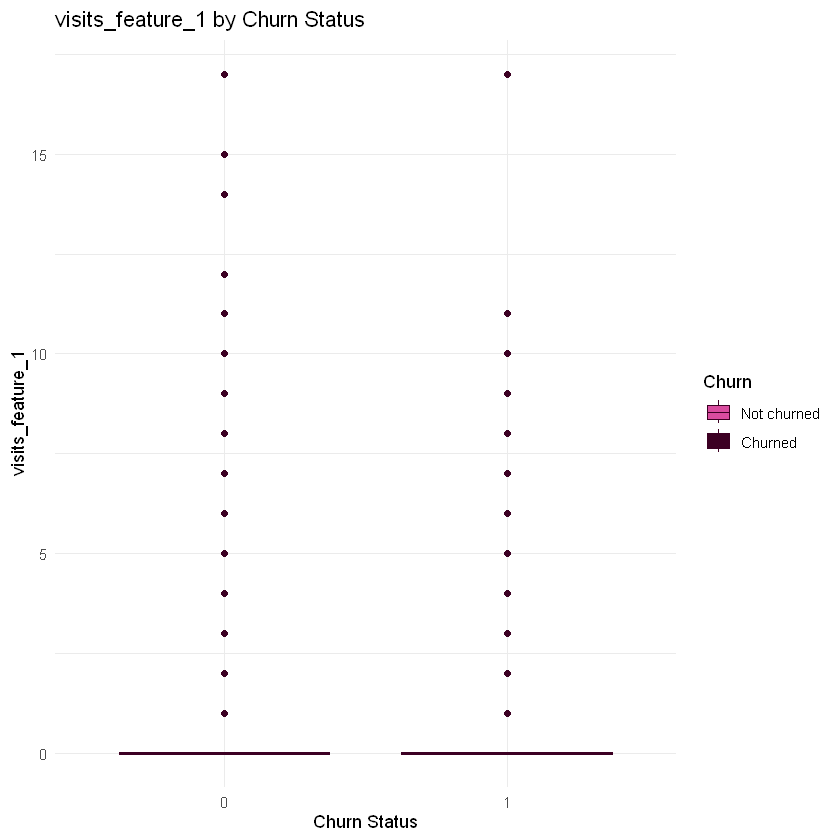

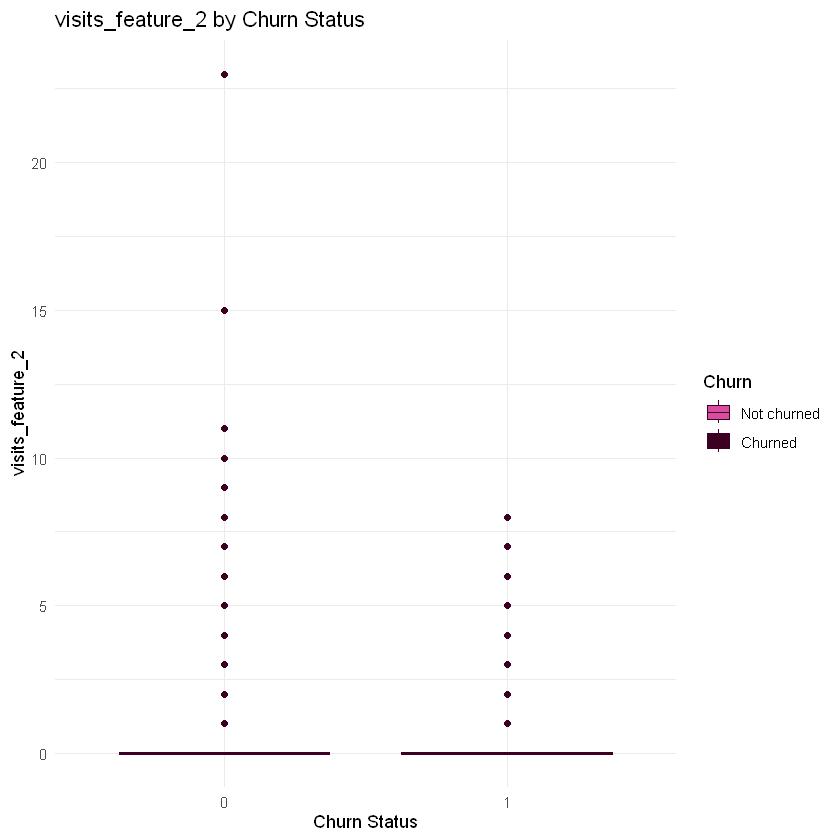

In [533]:
# Generate boxplots for each numeric variable by churn status
plots <- map(names(numeric_data), function(variable) {

  p <- ggplot(data, aes(
    x = as.factor(is_churned),
    y = .data[[variable]],
    fill = as.factor(is_churned)
  )) +
    geom_boxplot(
      color = "#3c0023",
      na.rm = TRUE
    ) +
    scale_fill_manual(
      values = c("0" = "#d94c9f", "1" = "#3c0023"),
      labels = c("Not churned", "Churned")
    ) +
    labs(
      title = paste(variable, "by Churn Status"),
      x = "Churn Status",
      y = variable,
      fill = "Churn"
    ) +
    theme_minimal()

  print(p)
})

When comparing the quantitative variables using boxplots, it can be observed that, due to the strong skewness identified earlier and the presence of outliers, the distributions become highly compressed, making it difficult to visualize potential differences between the two churn classes.

Next, relative frequency histograms are generated to compare the distributions of the quantitative variables between the two classes of `is_churned` and identify potential differences in their distribution patterns.

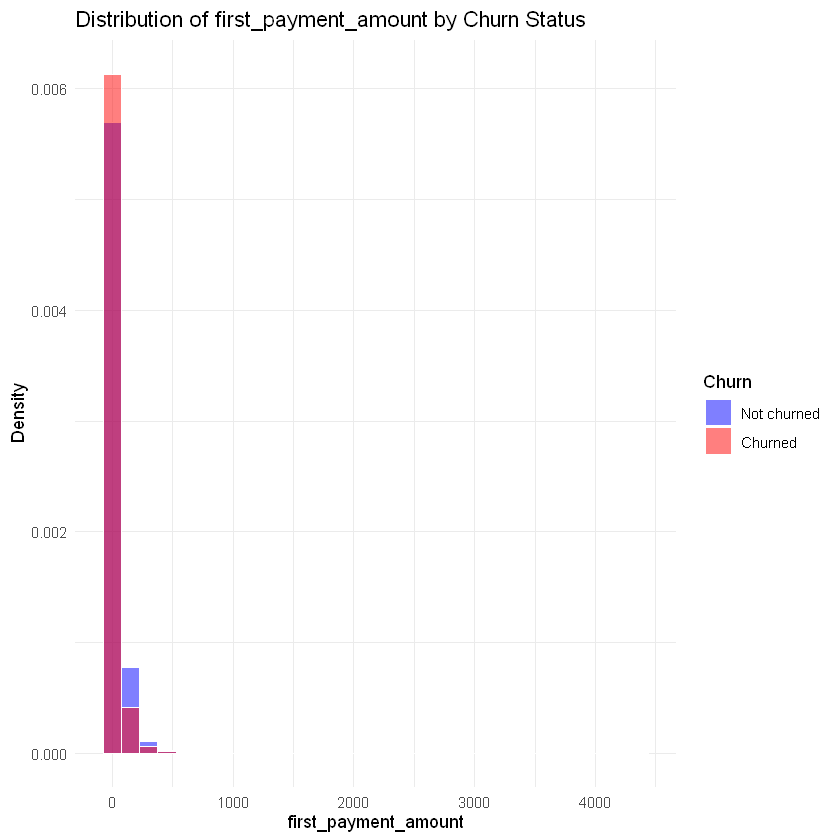

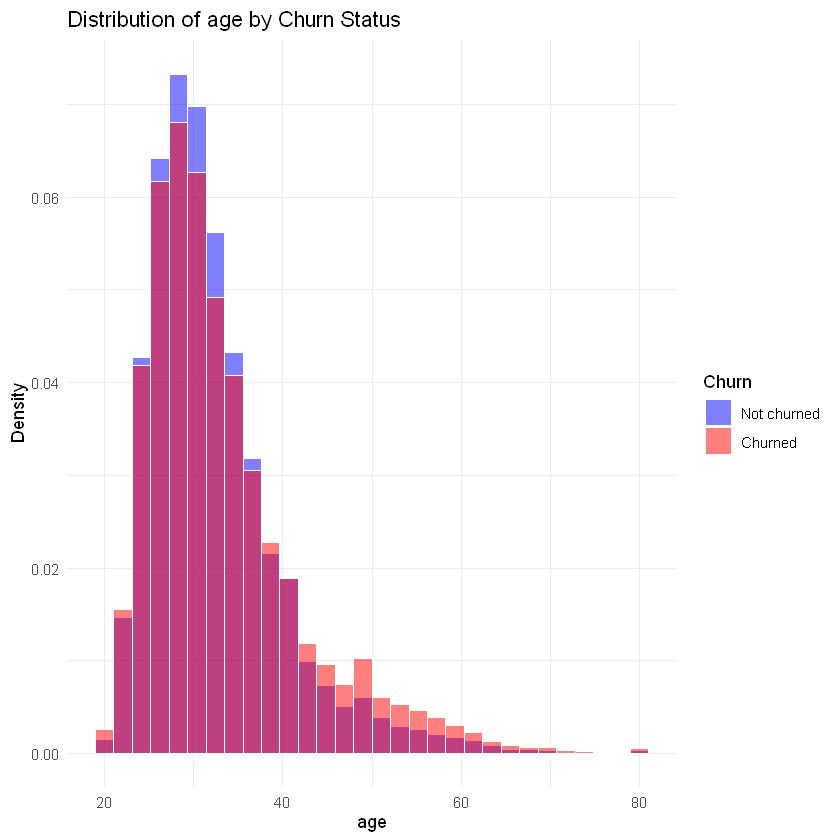

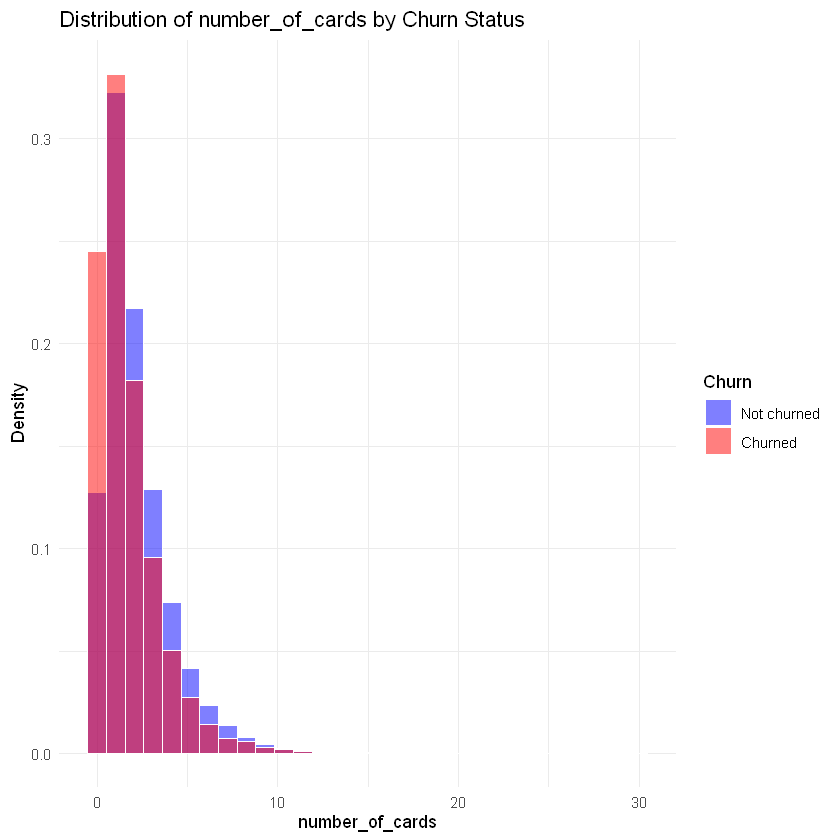

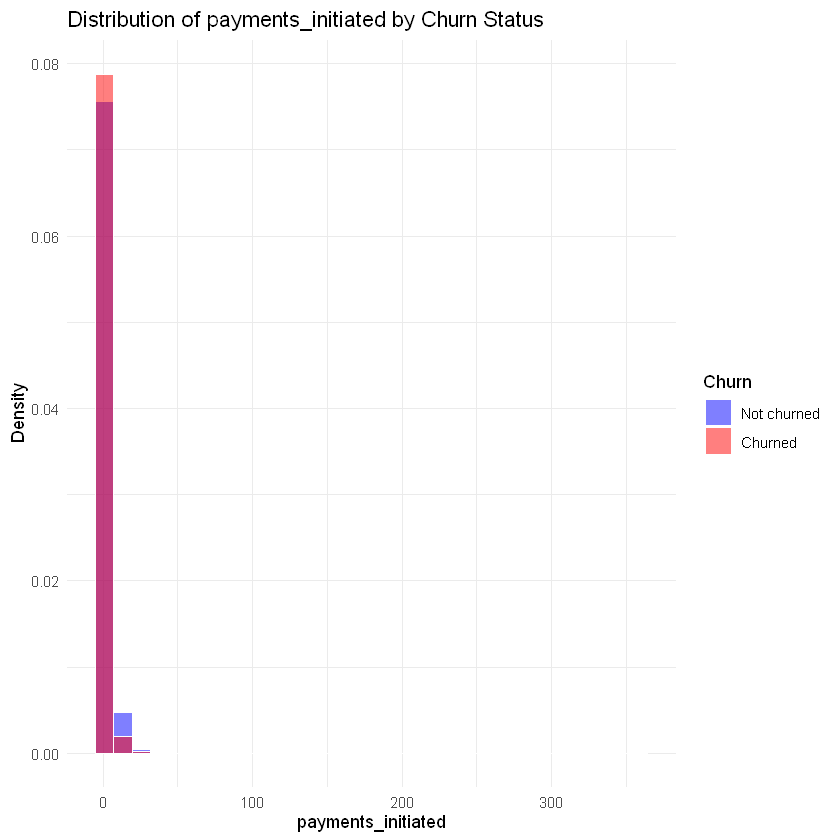

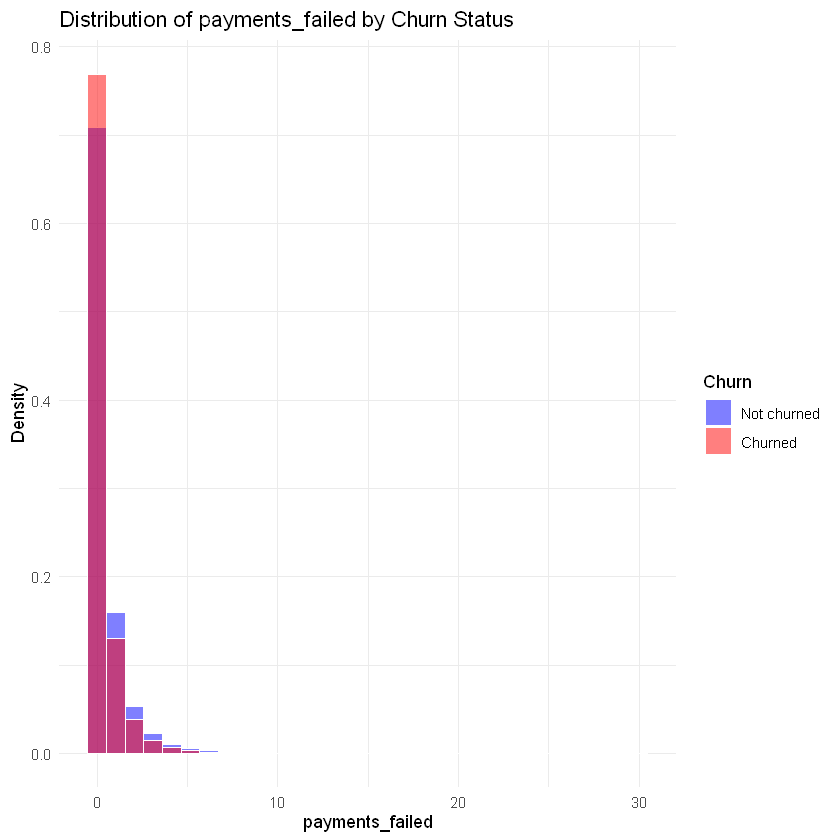

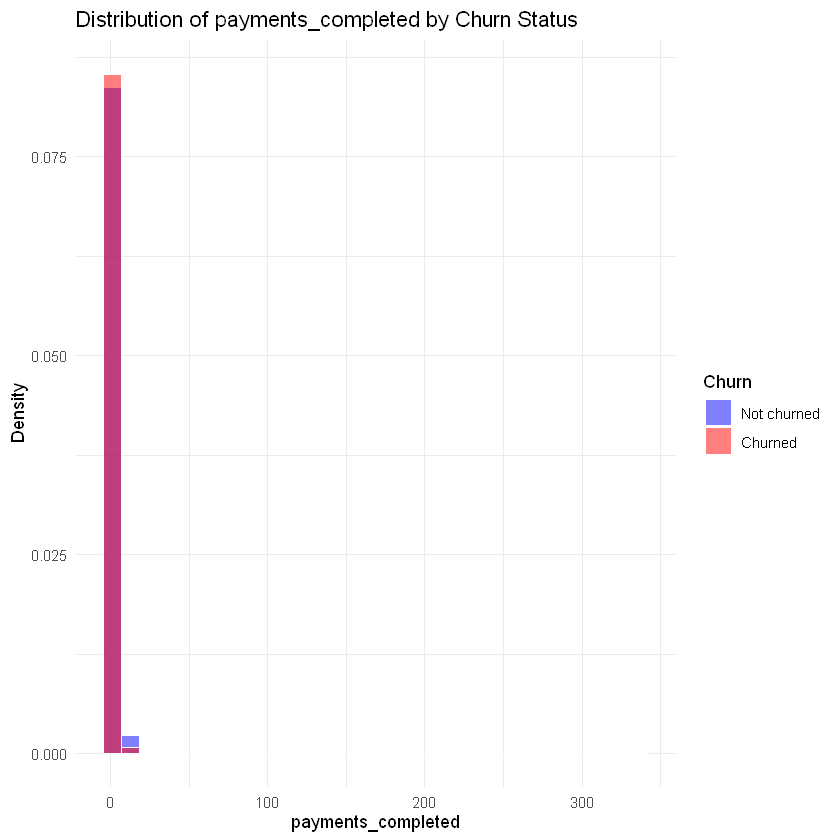

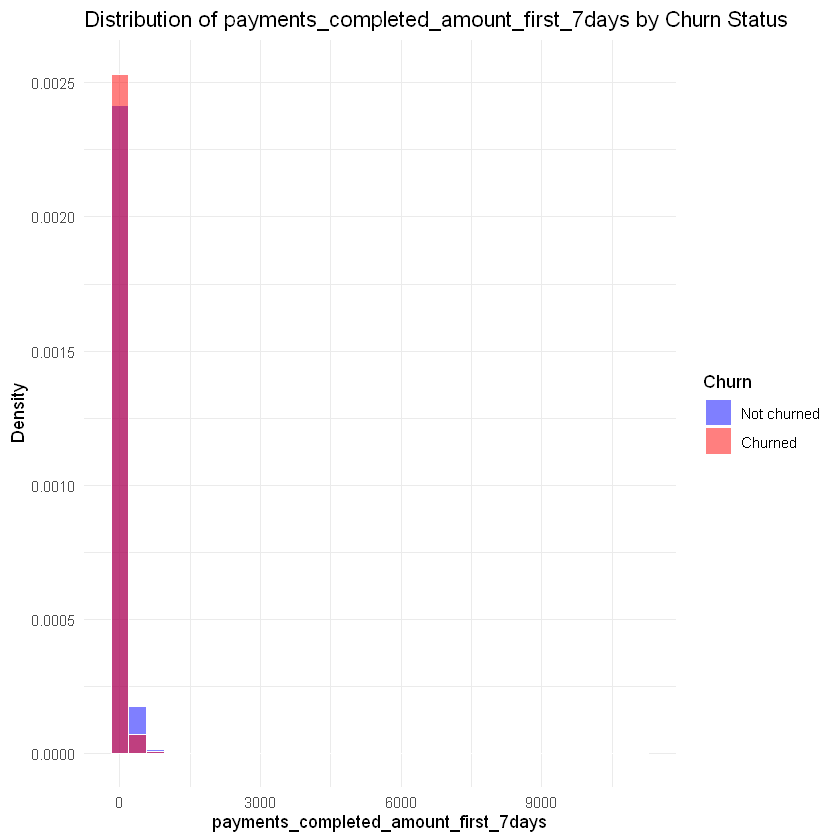

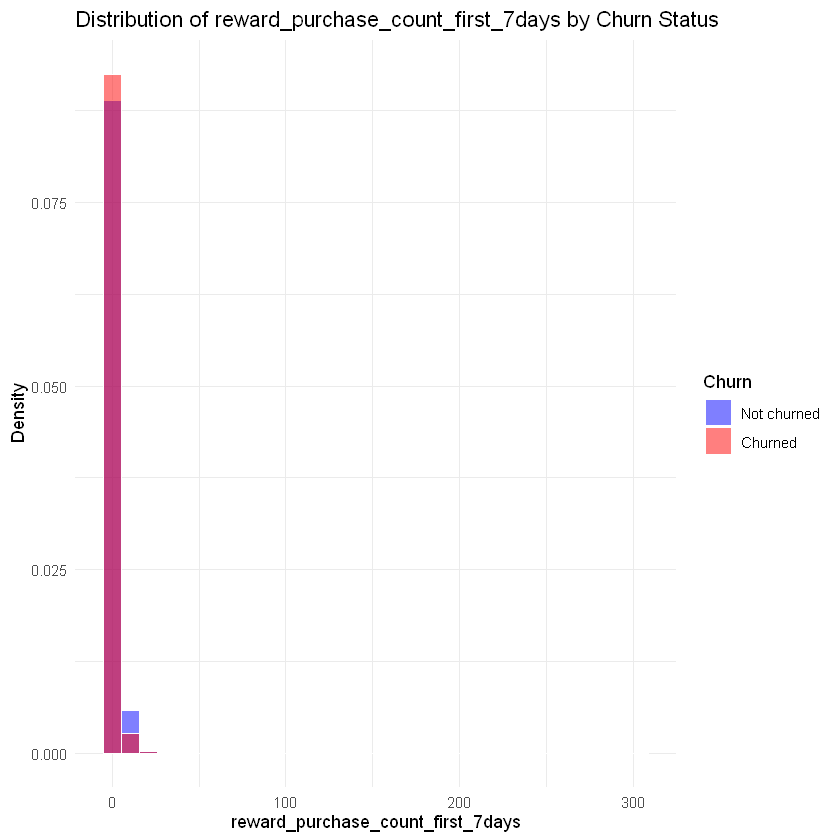

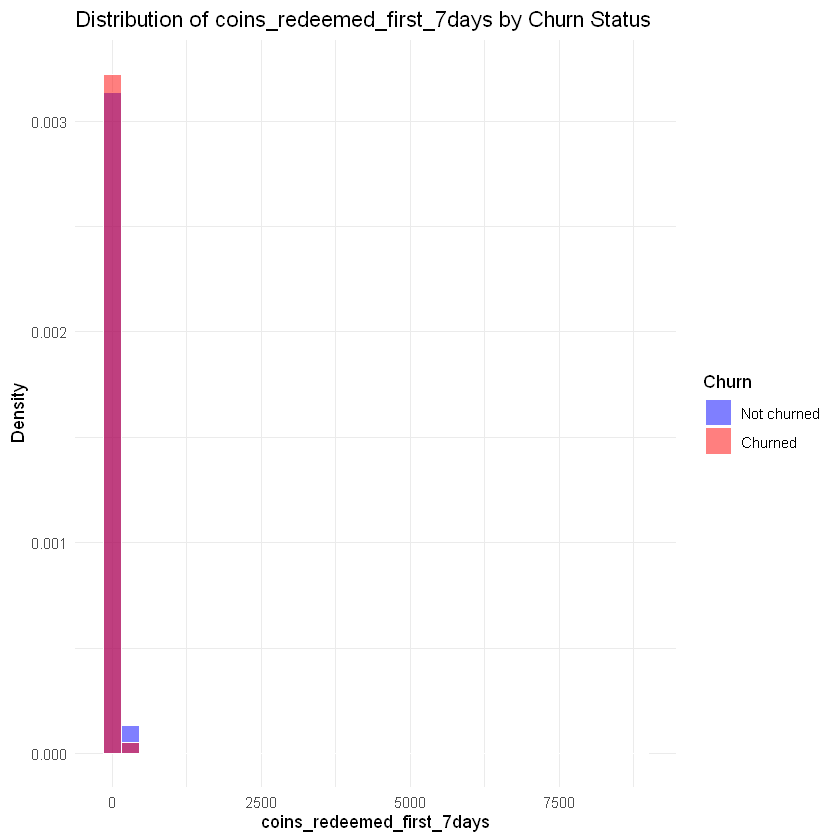

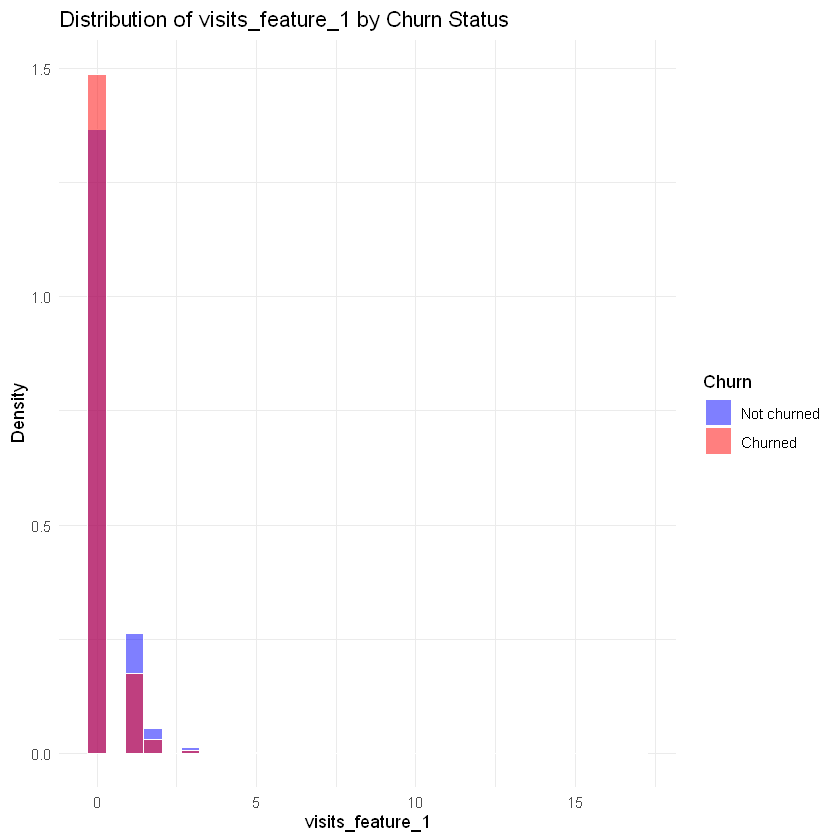

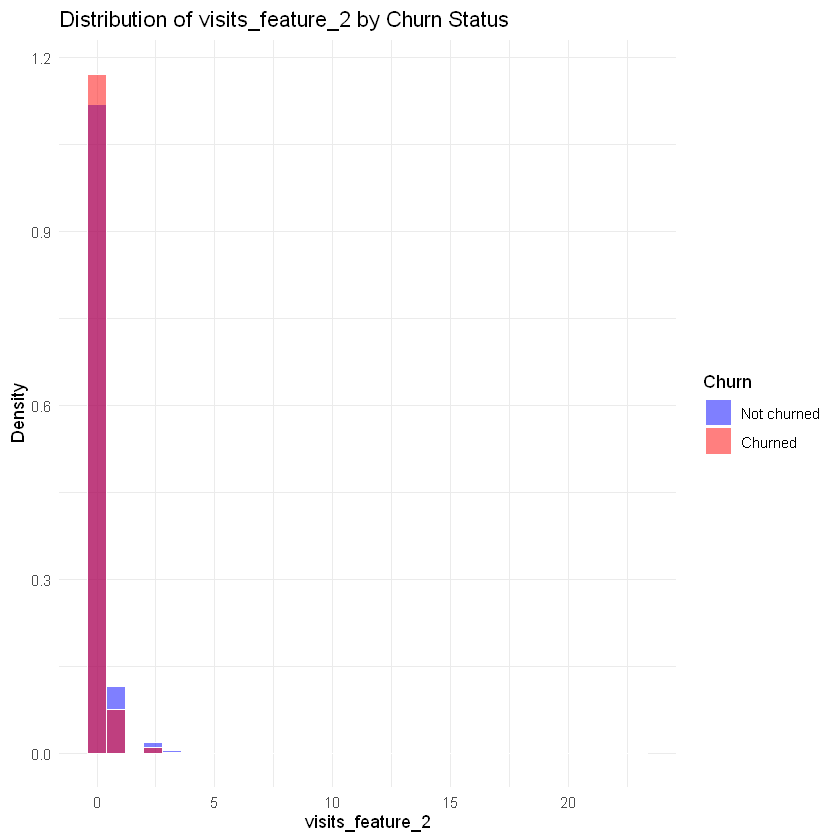

In [534]:
# Generate histograms for each numeric variable by churn status
plots <- map(names(numeric_data), function(variable) {

  p <- ggplot(data, aes(
    x = .data[[variable]],
    y = after_stat(density),
    fill = as.factor(is_churned)
  )) +
    geom_histogram(
      bins = 30,
      alpha = 0.5,
      position = "identity",
      color = "white",
      na.rm = TRUE
    ) +
    scale_fill_manual(
      values = c("0" = "blue", "1" = "red"),
      labels = c("Not churned", "Churned")
    ) +
    labs(
      title = paste("Distribution of", variable, "by Churn Status"),
      x = variable,
      y = "Density",
      fill = "Churn"
    ) +
    theme_minimal()

  print(p)
})

After generating the boxplots and histograms, it is difficult to identify significant visual differences between the distributions of the quantitative variables across the two churn classes. However, this does not necessarily mean that these variables lack predictive power, as non-linear relationships or interactions may exist that cannot be identified through these visualizations.

### Section conclusions

The initial exploratory analysis has made it possible to identify different characteristics of the dataset and detect several aspects that should be taken into account during the subsequent stages of the project.

First, missing values have been identified in 12 variables, as well as duplicate categories in `city` due to formatting differences. Regarding the target variable, a certain degree of class imbalance has been observed: 71.32% of users have not churned, compared to 28.68% who have.

Regarding the categorical variables, there is a high concentration of users within certain device brands and cities. However, both variables contain numerous categories with very few observations, making it difficult to draw reliable conclusions about their relationship with churn.

Some interesting associations with the churn rate have also been identified. Users acquired through referrals have a churn rate of 34.6%, compared to 24.5% for other users. Similarly, a lower churn rate is observed among users who have granted both permissions. Finally, the group of users over 65 has the highest churn rate, while the 26–35 age group has the lowest.

Finally, the quantitative variables exhibit highly skewed distributions and extreme values. This, together with the similarity observed between the distributions of both classes in the boxplots and histograms, makes it difficult to visually identify potential relationships with churn.

## 2. Data Analysis Using Statistical Techniques

Among the following techniques covered in class (Correlation, PCA, ANOVA, and Mutual Information), at least two must be selected as the basis for the analysis.

For each selected technique, the following aspects must be addressed:

- **Theoretical background:** What is the technique? What is it used for? Why are these techniques chosen over others?
- **Application to the dataset:** Apply the technique to the dataset, analyze the results obtained, and explain their implications.

### Selection of Statistical Techniques

Since only the theoretical background of two statistical techniques is required, PCA and Mutual Information have been selected for the following reasons:

1. **Correlation Analysis:** Using Pearson's correlation coefficient, this technique makes it possible to study linear relationships between quantitative variables. Although it is not the most suitable tool for directly examining the relationship between the explanatory variables and the binary target variable, it is useful for detecting potential multicollinearity issues among the independent quantitative variables. However, PCA has been selected instead, as it allows us to analyze the correlation structure among these variables and, additionally, reduce the dimensionality of the dataset.

2. **PCA:** Principal Component Analysis makes it possible to reduce the dimensionality of the dataset by creating new variables known as principal components. These components combine information from the original variables and help identify correlation structures and potential redundancies through the analysis of their loadings. Furthermore, the principal components are uncorrelated with each other. Therefore, PCA not only allows us to examine the structure of the quantitative variables but also offers the possibility of reducing the dimensionality of the dataset, which represents an advantage over correlation analysis.

3. **ANOVA:** This technique could be useful for determining whether there are statistically significant differences between the mean values of the independent quantitative variables according to the target variable `is_churned`. However, it has not been selected because the analysis should also include a technique capable of examining the relationship between the independent categorical variables and the target variable. In this regard, PCA will be used to analyze the structure of the quantitative variables, while Mutual Information will be used to study the dependence between the explanatory variables and churn.

4. **Mutual Information:** This technique makes it possible to quantify the statistical dependence between two variables, whether quantitative or qualitative. Therefore, it is particularly useful for examining the relationship between independent categorical variables, such as `is_referral`, and the target variable `is_churned`. It also makes it possible to identify which variables contain more information about customer churn behavior.

### Handling missing values

Before carrying out the selected analyses, it is necessary to handle the missing values in the dataset to prevent them from affecting either PCA or Mutual Information analysis. To do so, it is important to revisit the information previously obtained about the variables containing missing values.

In [535]:
missing_values <- data %>%
  summarise(
    across(
      everything(),
      list(
        frequency = ~ sum(is.na(.)),
        percentage = ~ mean(is.na(.)) * 100
      )
    )
  ) %>%
  pivot_longer(
    cols = everything(),
    names_to = c("variable", ".value"),
    names_pattern = "(.*)_(frequency|percentage)"
  ) %>%
  arrange(desc(percentage))

missing_values

variable,frequency,percentage
<chr>,<int>,<dbl>
reward_purchase_count_first_7days,23264,22.338515
city,5842,5.609594
visits_feature_1,2646,2.540737
visits_feature_2,2646,2.540737
number_of_cards,472,0.453223
payments_initiated,472,0.453223
payments_failed,472,0.453223
payments_completed,472,0.453223
payments_completed_amount_first_7days,472,0.453223


As can be observed, the percentage of missing values is relatively low for most variables, meaning that their potential impact on the analysis should be limited. However, the `reward_purchase_count_first_7days` variable stands out, as its missing values account for 22.34% of all observations. For this reason, it will be examined individually before deciding how to handle its missing values.

The following strategy will be applied:

* **Quantitative variables:** Missing values will be imputed using the median. This decision is justified because, as observed during the exploratory analysis, the distributions exhibit strong skewness and numerous outliers. The median is a robust measure of central tendency and is less sensitive to extreme values than the arithmetic mean.

* **Categorical variables `device` and `city`:** The ten most frequent categories of each variable will be retained, while the remaining categories will be grouped into a single category called `other`. A new `unknown` category will initially be created for missing values, avoiding the assignment of a category that we do not know and preserving information about the missingness pattern.

* **Variable `reward_purchase_count_first_7days`:** A specific analysis will be conducted to investigate the origin and meaning of its missing values. Based on the results, the most appropriate treatment will be selected.

In [536]:
# Impute missing values with median for numeric variables
median_imputation_variables <- c(
  "visits_feature_1",
  "visits_feature_2",
  "number_of_cards",
  "payments_initiated",
  "payments_failed",
  "payments_completed",
  "payments_completed_amount_first_7days",
  "coins_redeemed_first_7days",
  "age"
)

data <- data %>%
  mutate(
    across(
      all_of(median_imputation_variables),
      ~ replace(.x, is.na(.x), median(.x, na.rm = TRUE))
    )
  )

In [537]:
# Impute missing values with unknown for categorical variables
group_categories <- function(x, n = 10) {
  x <- as.character(x)

  top_categories <- names(
    sort(table(x, useNA = "no"), decreasing = TRUE)
  )[1:n]

  case_when(
    is.na(x) ~ "unknown",
    x %in% top_categories ~ x,
    TRUE ~ "other"
  )
}

data <- data %>%
  mutate(
    device = group_categories(device),
    city = group_categories(city)
  )

Next, the `reward_purchase_count_first_7days` variable is analyzed.

In [538]:
missing_by_churn <- data %>%
  group_by(is_churned) %>%
  summarise(
    total = n(),
    missing = sum(is.na(reward_purchase_count_first_7days)),
    missing_percentage = missing / total * 100
  )

missing_by_churn

is_churned,total,missing,missing_percentage
<int>,<int>,<int>,<dbl>
0,74274,7653,10.30374
1,29869,15611,52.26489


It can be observed that missing values (**NA**) are not distributed homogeneously across the two categories of `is_churned`. Specifically, the percentage of missing values is considerably higher among users who leave the service (`is_churned = 1`), at 52.26%, compared to 10.30% among users who remain (`is_churned = 0`).

This difference suggests that the absence of information in `reward_purchase_count_first_7days` may be related to service churn. Therefore, it does not seem appropriate to treat these missing values as if they were randomly distributed.

To preserve this information without preventing PCA from being performed, a new variable called `reward_purchase_missing` will be added to the dataset, and the missing values will be imputed using the median for the PCA analysis.

In [539]:
data <- data %>%
    mutate(
        reward_purchase_missing = ifelse(is.na(reward_purchase_count_first_7days), 1, 0),
        across(
            reward_purchase_count_first_7days,
            ~ replace(.x, is.na(.x), median(.x, na.rm = TRUE))
        )
    )

In [540]:
str(data)
summary(data)

missing_values <- data %>%
  summarise(
    across(
      everything(),
      list(
        frequency = ~ sum(is.na(.)),
        percentage = ~ mean(is.na(.)) * 100
      )
    )
  ) %>%
  pivot_longer(
    cols = everything(),
    names_to = c("variable", ".value"),
    names_pattern = "(.*)_(frequency|percentage)"
  ) %>%
  arrange(desc(percentage))

missing_values

'data.frame':	104143 obs. of  19 variables:
 $ device                               : chr  "samsung" "xiaomi" "xiaomi" "oneplus" ...
 $ first_payment_amount                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ age                                  : int  20 20 20 20 20 20 20 20 20 20 ...
 $ city                                 : chr  "ahmedabad" "surat" "other" "mumbai" ...
 $ number_of_cards                      : int  2 1 1 2 2 0 0 0 0 0 ...
 $ payments_initiated                   : int  1 1 2 4 1 1 1 17 1 1 ...
 $ payments_failed                      : int  0 0 1 1 0 0 0 0 0 0 ...
 $ payments_completed                   : int  1 1 1 2 1 1 1 12 1 1 ...
 $ payments_completed_amount_first_7days: int  0 0 0 322 0 0 0 143 0 0 ...
 $ reward_purchase_count_first_7days    : int  1 1 0 2 0 0 0 6 0 1 ...
 $ coins_redeemed_first_7days           : int  0 0 0 20 0 0 0 190 0 0 ...
 $ is_referral                          : logi  FALSE TRUE TRUE FALSE FALSE TRUE ...
 $ visits_feature_1                 

       device       first_payment_amount      age               city       
 Length   :104143   Min.   :   0.00      Min.   :20.00   Length   :104143  
 N.unique :    12   1st Qu.:   2.00      1st Qu.:27.00   N.unique :    12  
 N.blank  :     0   Median :  12.00      Median :31.00   N.blank  :     0  
 Min.nchar:     4   Mean   :  34.77      Mean   :32.69   Min.nchar:     3  
 Max.nchar:    10   3rd Qu.:  37.00      3rd Qu.:36.00   Max.nchar:     9  
                    Max.   :4370.00      Max.   :80.00                     
 number_of_cards  payments_initiated payments_failed   payments_completed
 Min.   : 0.000   Min.   :  1.000    Min.   : 0.0000   Min.   :  1.000   
 1st Qu.: 1.000   1st Qu.:  1.000    1st Qu.: 0.0000   1st Qu.:  1.000   
 Median : 1.000   Median :  2.000    Median : 0.0000   Median :  1.000   
 Mean   : 1.985   Mean   :  2.844    Mean   : 0.4379   Mean   :  1.827   
 3rd Qu.: 3.000   3rd Qu.:  3.000    3rd Qu.: 0.0000   3rd Qu.:  2.000   
 Max.   :30.000   Max.  

variable,frequency,percentage
<chr>,<int>,<dbl>
device,0,0
first_payment_amount,0,0
age,0,0
city,0,0
number_of_cards,0,0
payments_initiated,0,0
payments_failed,0,0
payments_completed,0,0
payments_completed_amount_first_7days,0,0


It is confirmed that the transformations have been applied successfully and that there are no longer any missing values (`NA`) in the dataset.

### PCA

The quantitative variables must first be retrieved, since PCA can only be applied to these variables.

In [541]:
numeric_data <- data %>%
  select(
    first_payment_amount,
    age,
    number_of_cards,
    payments_initiated,
    payments_failed,
    payments_completed,
    payments_completed_amount_first_7days,
    reward_purchase_count_first_7days,
    coins_redeemed_first_7days,
    visits_feature_1,
    visits_feature_2
  )

head(numeric_data)

,first_payment_amount,age,number_of_cards,payments_initiated,payments_failed,payments_completed,payments_completed_amount_first_7days,reward_purchase_count_first_7days,coins_redeemed_first_7days,visits_feature_1,visits_feature_2
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,0,20,2,1,0,1,0,1,0,3,0
2,0,20,1,1,0,1,0,1,0,0,0
3,0,20,1,2,1,1,0,0,0,0,0
4,0,20,2,4,1,2,322,2,20,0,0
5,0,20,2,1,0,1,0,0,0,0,1
6,0,20,0,1,0,1,0,0,0,0,0


Importance of components:
                         Comp.1   Comp.2    Comp.3     Comp.4     Comp.5
Standard deviation     1.809899 1.356982 1.1169094 1.04747263 0.95068100
Proportion of Variance 0.297794 0.167400 0.1134079 0.09974536 0.08216312
Cumulative Proportion  0.297794 0.465194 0.5786019 0.67834726 0.76051038
                           Comp.6     Comp.7     Comp.8    Comp.9    Comp.10
Standard deviation     0.91888056 0.86254726 0.75891682 0.5233157 0.37711012
Proportion of Variance 0.07675832 0.06763525 0.05235952 0.0248963 0.01292837
Cumulative Proportion  0.83726870 0.90490395 0.95726347 0.9821598 0.99508814
                           Comp.11
Standard deviation     0.232444462
Proportion of Variance 0.004911857
Cumulative Proportion  1.000000000

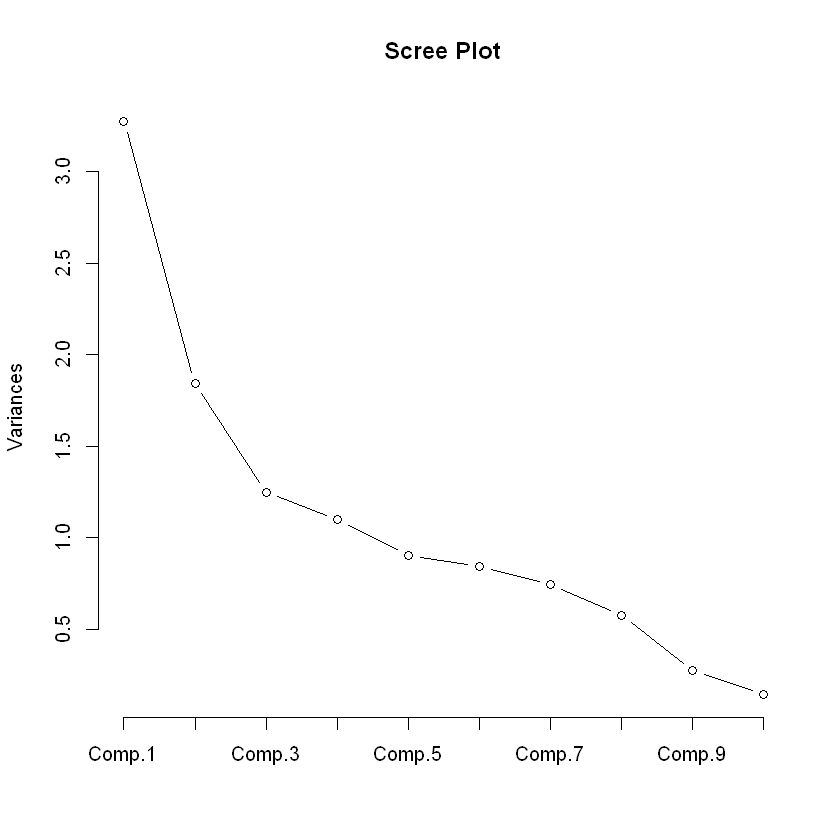

In [542]:
acp <- princomp(numeric_data, cor = TRUE)
summary(acp)
plot(acp, main = "Scree Plot", type = "lines")

In [543]:
loadings(acp)


Loadings:
                                      Comp.1 Comp.2 Comp.3 Comp.4 Comp.5 Comp.6
first_payment_amount                   0.155  0.572         0.108  0.188       
age                                                 -0.220 -0.701  0.171  0.626
number_of_cards                        0.125  0.102 -0.118 -0.618 -0.368 -0.659
payments_initiated                     0.469 -0.323                0.114       
payments_failed                        0.258 -0.171        -0.115  0.802 -0.341
payments_completed                     0.456 -0.310               -0.199  0.128
payments_completed_amount_first_7days  0.316  0.522                            
reward_purchase_count_first_7days      0.483 -0.128               -0.270  0.154
coins_redeemed_first_7days             0.354  0.366               -0.141       
visits_feature_1                                     0.699                     
visits_feature_2                                     0.663 -0.262         0.126
                             

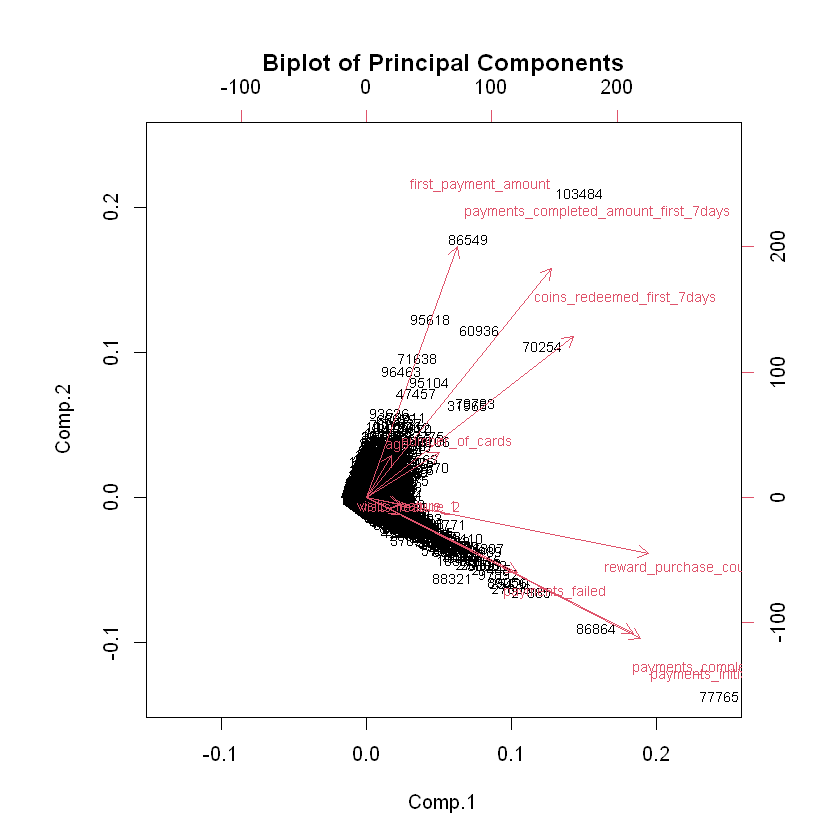

In [544]:
biplot(acp, main = "Biplot of Principal Components", cex = 0.7)

Based on the Principal Component Analysis (PCA), 11 principal components are obtained from the 14 original numerical variables. This indicates that some redundancy exists among the variables, although it is not possible to substantially reduce the dimensionality without losing an important proportion of the data's variability.

The first two principal components jointly explain 46.52% of the total variance. By adding a third component, this percentage increases to 57.86%. On the other hand, seven components are required to reach 90.49% of the explained variance. These results show that it is difficult to represent a high proportion of the original information using only a small number of components.

Regarding the interpretation of the components, the first component is particularly associated with `reward_purchase_count_first_7days`, which has the highest loading (0.483). In the second component, `first_payment_amount` stands out, with a loading of 0.572. Both components also show a significant contribution from variables related to payments and rewards, suggesting that these variables explain an important part of the dataset's variability.

The third component, in turn, is mainly associated with `visits_feature_1` and `visits_feature_2`, with loadings of 0.699 and 0.663, respectively. This suggests that both variables capture a dimension of variability related to visits to the application's features.

Overall, PCA makes it possible to identify two major groups of variables that contribute to explaining the structure of the data: those related to payments and rewards, and those related to visits to application features. However, given that seven components are required to explain more than 90% of the variance, it does not seem advisable to drastically reduce the number of variables based exclusively on this analysis.

### Mutual Information

Before conducting the analysis, a new variable called `permission_type` is added. It combines the information provided by both `given_permission_1` and `given_permission_2`.

In [545]:
data <- data %>%
    mutate(
        permission_type = case_when(
            given_permission_1 == FALSE & given_permission_2 == FALSE ~ "None",
            given_permission_1 == TRUE & given_permission_2 == FALSE ~ "Only permission 1",
            given_permission_1 == FALSE & given_permission_2 == TRUE ~ "Only permission 2",
            given_permission_1 == TRUE & given_permission_2 == TRUE ~ "Both permissions",
            TRUE ~ NA_character_
        )
    )

# eliminate the original permission columns since we have created a new categorical variable
data <- data %>%
  select(-given_permission_1, -given_permission_2)

head(data)

,device,first_payment_amount,age,city,number_of_cards,payments_initiated,payments_failed,payments_completed,payments_completed_amount_first_7days,reward_purchase_count_first_7days,coins_redeemed_first_7days,is_referral,visits_feature_1,visits_feature_2,user_id,is_churned,reward_purchase_missing,permission_type
,<chr>,<int>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<lgl>,<int>,<int>,<int>,<int>,<dbl>,<chr>
1,samsung,0,20,ahmedabad,2,1,0,1,0,1,0,FALSE,3,0,269438,0,1,Only permission 1
2,xiaomi,0,20,surat,1,1,0,1,0,1,0,TRUE,0,0,139521,0,1,Only permission 1
3,xiaomi,0,20,other,1,2,1,1,0,0,0,TRUE,0,0,307352,0,0,Only permission 2
4,oneplus,0,20,mumbai,2,4,1,2,322,2,20,FALSE,0,0,456424,0,0,Both permissions
5,apple,0,20,pune,2,1,0,1,0,0,0,FALSE,0,1,398779,0,0,Both permissions
6,oppo,0,20,ahmedabad,0,1,0,1,0,0,0,TRUE,0,0,136656,0,0,Both permissions


Finally, to prepare the dataset for the Mutual Information analysis, the qualitative variables are converted to `factor`, and the `user_id` variable is permanently removed from the dataset.

In [546]:
data <- data %>%
  mutate(
    city = as.factor(city),
    device = as.factor(device),
    is_referral = as.factor(is_referral),
    reward_purchase_missing = as.factor(reward_purchase_missing),
    permission_type = as.factor(permission_type),
    is_churned = as.factor(is_churned)
  )

data <- data %>%
    select(-user_id)

str(data)

'data.frame':	104143 obs. of  17 variables:
 $ device                               : Factor w/ 12 levels "apple","hmd global",..: 9 12 12 5 1 6 9 12 5 9 ...
 $ first_payment_amount                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ age                                  : int  20 20 20 20 20 20 20 20 20 20 ...
 $ city                                 : Factor w/ 12 levels "ahmedabad","bangalore",..: 1 11 9 7 10 1 11 9 9 4 ...
 $ number_of_cards                      : int  2 1 1 2 2 0 0 0 0 0 ...
 $ payments_initiated                   : int  1 1 2 4 1 1 1 17 1 1 ...
 $ payments_failed                      : int  0 0 1 1 0 0 0 0 0 0 ...
 $ payments_completed                   : int  1 1 1 2 1 1 1 12 1 1 ...
 $ payments_completed_amount_first_7days: int  0 0 0 322 0 0 0 143 0 0 ...
 $ reward_purchase_count_first_7days    : int  1 1 0 2 0 0 0 6 0 1 ...
 $ coins_redeemed_first_7days           : int  0 0 0 20 0 0 0 190 0 0 ...
 $ is_referral                          : Factor w/ 2 levels "FALSE

It is verified that the transformations have been applied successfully, and the analysis proceeds.

In [547]:
i = information_gain(formula = is_churned ~ .
                     , data = data
                     , type = 'infogain')
i

attributes,importance
<chr>,<dbl>
device,0.006959631
first_payment_amount,0.058312681
age,0.002917836
city,0.017460888
number_of_cards,0.012401927
payments_initiated,0.018623981
payments_failed,0.002341623
payments_completed,0.027342213
payments_completed_amount_first_7days,0.073373983


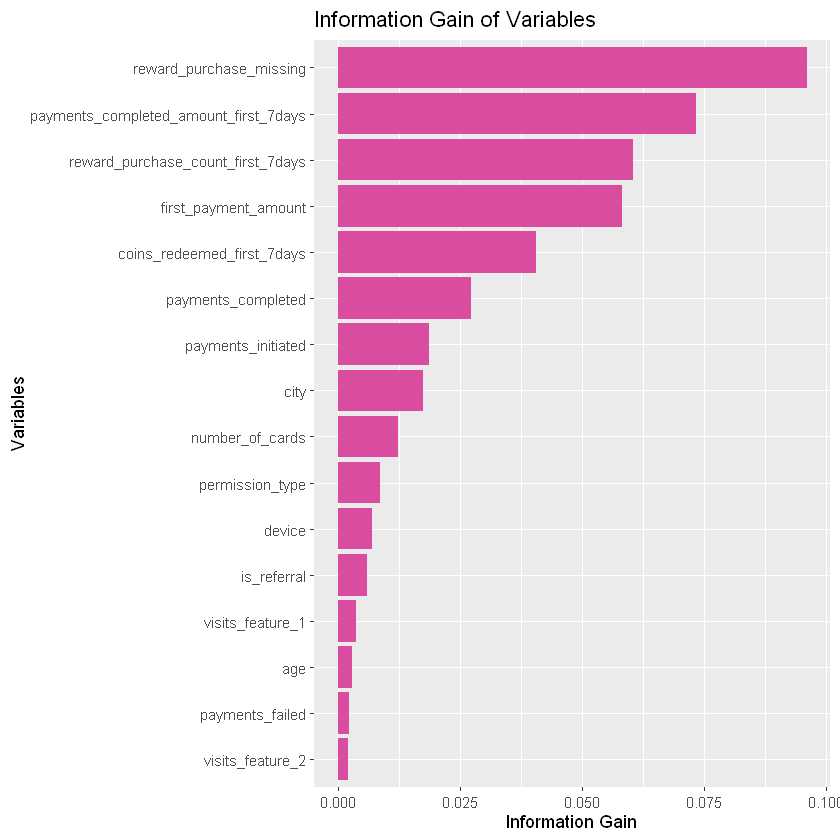

In [548]:
ggplot(i, aes(x = reorder(attributes, importance),
              y = importance)) +
  geom_col(fill = "#d94c9f") +
  coord_flip() +
  labs(
    title = "Information Gain of Variables",
    x = "Variables",
    y = "Information Gain"
  )

Before concluding the analysis, the `age` variable is also examined as a categorical variable by creating age intervals. This makes it possible to assess whether Information Gain is higher with this alternative treatment.

In [549]:
data <- data %>%
    mutate(
        age_category = case_when(
            age >= 18 & age <= 25 ~ "18-25",
            age >= 26 & age <= 35 ~ "26-35",
            age >= 36 & age <= 45 ~ "36-45",
            age >= 46 & age <= 55 ~ "46-55",
            age >= 56 & age <= 65 ~ "56-65",
            age > 65 ~ "Over 65",
            TRUE ~ NA_character_
        ),
        age_category = as.factor(age_category)
    ) 

str(data)

'data.frame':	104143 obs. of  18 variables:
 $ device                               : Factor w/ 12 levels "apple","hmd global",..: 9 12 12 5 1 6 9 12 5 9 ...
 $ first_payment_amount                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ age                                  : int  20 20 20 20 20 20 20 20 20 20 ...
 $ city                                 : Factor w/ 12 levels "ahmedabad","bangalore",..: 1 11 9 7 10 1 11 9 9 4 ...
 $ number_of_cards                      : int  2 1 1 2 2 0 0 0 0 0 ...
 $ payments_initiated                   : int  1 1 2 4 1 1 1 17 1 1 ...
 $ payments_failed                      : int  0 0 1 1 0 0 0 0 0 0 ...
 $ payments_completed                   : int  1 1 1 2 1 1 1 12 1 1 ...
 $ payments_completed_amount_first_7days: int  0 0 0 322 0 0 0 143 0 0 ...
 $ reward_purchase_count_first_7days    : int  1 1 0 2 0 0 0 6 0 1 ...
 $ coins_redeemed_first_7days           : int  0 0 0 20 0 0 0 190 0 0 ...
 $ is_referral                          : Factor w/ 2 levels "FALSE

In [550]:
i <- information_gain(formula = is_churned ~ .
                     , data = data
                     , type = 'infogain')

i

attributes,importance
<chr>,<dbl>
device,0.006959631
first_payment_amount,0.058312681
age,0.002917836
city,0.017460888
number_of_cards,0.012401927
payments_initiated,0.018623981
payments_failed,0.002341623
payments_completed,0.027342213
payments_completed_amount_first_7days,0.073373983


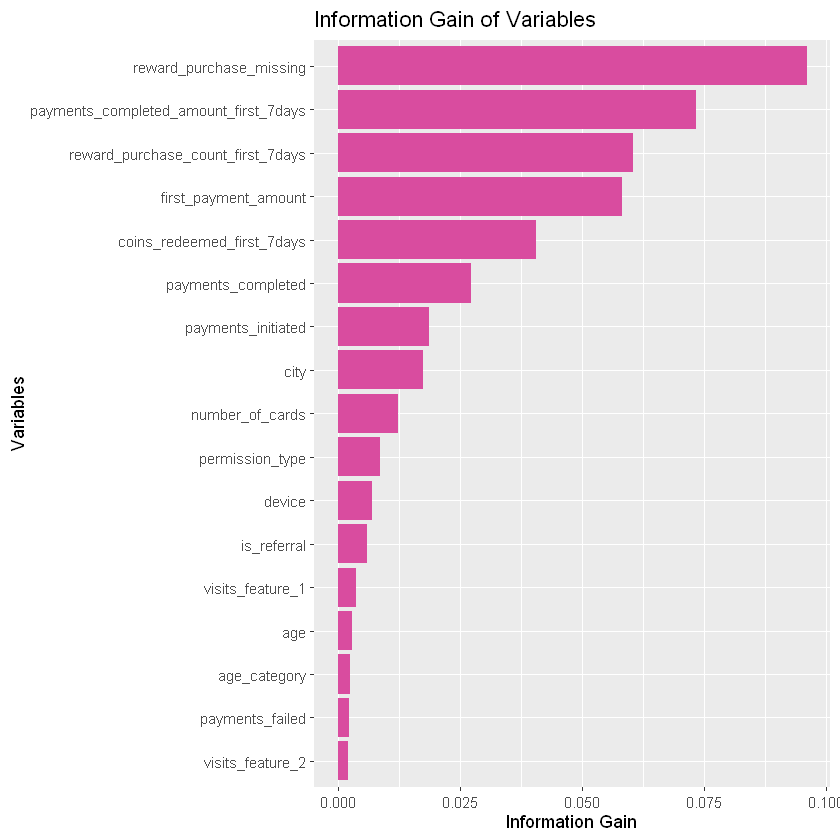

In [551]:
ggplot(i, aes(x = reorder(attributes, importance),
              y = importance)) +
  geom_col(fill = "#d94c9f") +
  coord_flip() +
  labs(
    title = "Information Gain of Variables",
    x = "Variables",
    y = "Information Gain"
  )

It can be observed that categorizing the `age` variable does not improve its Information Gain compared to its original numerical representation. For this reason, it is decided to retain the variable in its original format, since grouping ages into intervals results in information loss by treating values that were originally different as equivalent.

In [552]:
data <- data %>%
    select(-age_category)

str(data)

'data.frame':	104143 obs. of  17 variables:
 $ device                               : Factor w/ 12 levels "apple","hmd global",..: 9 12 12 5 1 6 9 12 5 9 ...
 $ first_payment_amount                 : int  0 0 0 0 0 0 0 0 0 0 ...
 $ age                                  : int  20 20 20 20 20 20 20 20 20 20 ...
 $ city                                 : Factor w/ 12 levels "ahmedabad","bangalore",..: 1 11 9 7 10 1 11 9 9 4 ...
 $ number_of_cards                      : int  2 1 1 2 2 0 0 0 0 0 ...
 $ payments_initiated                   : int  1 1 2 4 1 1 1 17 1 1 ...
 $ payments_failed                      : int  0 0 1 1 0 0 0 0 0 0 ...
 $ payments_completed                   : int  1 1 1 2 1 1 1 12 1 1 ...
 $ payments_completed_amount_first_7days: int  0 0 0 322 0 0 0 143 0 0 ...
 $ reward_purchase_count_first_7days    : int  1 1 0 2 0 0 0 6 0 1 ...
 $ coins_redeemed_first_7days           : int  0 0 0 20 0 0 0 190 0 0 ...
 $ is_referral                          : Factor w/ 2 levels "FALSE

Based on the Information Gain analysis, it can be observed that the variables providing the most information about the target variable `is_churned` are mainly related to payments and rewards made by users. This result is consistent with the observations obtained through PCA, where these variables also stood out in the first principal components.

The variable with the highest Information Gain is `reward_purchase_missing`, which was created during preprocessing to identify records in which `reward_purchase_count_first_7days` contained missing values. This result indicates that the absence of information in this variable is particularly strongly associated with users' churn status.

Other variables related to payment activity stand out next, such as `payments_completed_amount_first_7days`, `reward_purchase_count_first_7days`, and `first_payment_amount`. These are followed by variables such as `city`, `number_of_cards`, and `permission_type`, the latter having been manually created from two original variables.

On the other hand, it has been confirmed that categorizing the `age` variable does not improve its Information Gain compared to its original numerical representation. For this reason, it has been decided to retain the variable in its original format, avoiding the information loss that results from grouping ages into intervals.

Overall, the results suggest that payment and reward activity constitutes one of the most informative groups of variables for distinguishing between users who leave the service and those who remain. Furthermore, some variables created during preprocessing, such as `reward_purchase_missing` and `permission_type`, also provide relevant information.

## 3. Development of the Logistic Regression Model

The following aspects must be addressed:

- Development and justification of the variables used in the model.
- Selection and justification of the model optimization metric.
- Development of at least three models and comparison of their results using confusion matrices.

### Development and Justification of the Variables Used in the Model

To build the logistic regression models, it has been decided to combine the results obtained through PCA and Information Gain, with the aim of selecting variables that provide relevant information from different perspectives.

First, priority will be given to variables related to payments and rewards, as they stood out in both analyses. On the one hand, they have a significant presence in the first two principal components obtained through PCA, indicating that they contribute substantially to explaining the variability of the dataset. On the other hand, they also show high Information Gain values, meaning that they provide relevant information for distinguishing between users who leave the service and those who remain.

Second, variables created during preprocessing, such as `reward_purchase_missing` and `permission_type`, will be included. The former stands out for having the highest Information Gain of all the variables analyzed, while the latter also provides information about the target variable by combining the categories of two original variables.

Finally, some additional variables, such as `city` and `device`, will be considered. Although their Information Gain values are lower than those of the previously mentioned variables, it is considered interesting to evaluate whether their inclusion can improve the predictive performance of the models. Additionally, `is_referral` will also be included. Although no particularly high Information Gain was observed for this variable during the exploratory analysis, a churn rate difference of approximately 10 percentage points was identified between referred and non-referred users. Therefore, it is considered interesting to examine its contribution to the regression models.

Based on these criteria, progressive models will be developed, incorporating new groups of variables into each one. This approach will make it possible to analyze the contribution of each group and compare the performance of the different logistic regression models.

**Variables related to payments and rewards:**

- `reward_purchase_count_first_7days`
- `first_payment_amount`
- `payments_completed_amount_first_7days`
- `payments_completed`
- `coins_redeemed_first_7days`

**Variables created during preprocessing:**

- `reward_purchase_missing`
- `permission_type`

**Additional variables:**

- `city`
- `device`
- `is_referral`

The target variable will be `is_churned`.

### Selection and Justification of the Model Optimization Metrics

To compare the logistic regression models, the metrics Recall and ROC-AUC have been selected.

First, priority will be given to Recall, since the main objective of this problem is to correctly identify users who leave the service (`is_churned = 1`). This metric measures the proportion of actual churn cases detected by the model, making it particularly relevant to minimizing false negatives.

As a complementary metric, ROC-AUC will be used to evaluate the model's ability to discriminate between users who leave and those who remain, independently of the selected classification threshold.

Combining these two metrics will make it possible to compare both the model's ability to detect churn cases and its overall classification performance. Priority will be given to Recall, while still considering ROC-AUC to avoid selecting a model that achieves high sensitivity at the expense of poor discriminative ability.

### Development of Logistic Regression Models

First, the dataset is split into training and test sets.

In [553]:
set.seed(123)

index <- createDataPartition(
  data$is_churned,
  p = 0.7,
  list = FALSE
)

train_data <- data[index, ]
test_data <- data[-index, ]

The first model only uses the variables with the highest loadings in the first two principal components obtained through PCA.

In [554]:
m1 <- glm(is_churned ~ reward_purchase_count_first_7days + first_payment_amount, data = train_data, family = binomial)
summary(m1)

Warning message:
"glm.fit: fitted probabilities numerically 0 or 1 occurred"



Call:
glm(formula = is_churned ~ reward_purchase_count_first_7days + 
    first_payment_amount, family = binomial, data = train_data)

Coefficients:
                                    Estimate Std. Error z value Pr(>|z|)    
(Intercept)                       -0.5212695  0.0117516  -44.36   <2e-16 ***
reward_purchase_count_first_7days -0.1548169  0.0054170  -28.58   <2e-16 ***
first_payment_amount              -0.0050634  0.0002025  -25.01   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 87375  on 72900  degrees of freedom
Residual deviance: 85005  on 72898  degrees of freedom
AIC: 85011

Number of Fisher Scoring iterations: 5


In [555]:
predictions <- predict(m1, newdata = test_data, type = "response")

predicted_class <- ifelse(predictions >= 0.5, 1, 0)

In [556]:
confusionMatrix(
  factor(predicted_class, levels = c(0, 1)),
  factor(test_data$is_churned, levels = c(0, 1)),
  positive = "1"
)

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 22282  8960
         1     0     0
                                          
               Accuracy : 0.7132          
                 95% CI : (0.7082, 0.7182)
    No Information Rate : 0.7132          
    P-Value [Acc > NIR] : 0.5028          
                                          
                  Kappa : 0               
                                          
 Mcnemar's Test P-Value : <2e-16          
                                          
            Sensitivity : 0.0000          
            Specificity : 1.0000          
         Pos Pred Value :    NaN          
         Neg Pred Value : 0.7132          
             Prevalence : 0.2868          
         Detection Rate : 0.0000          
   Detection Prevalence : 0.0000          
      Balanced Accuracy : 0.5000          
                                          
       'Positive' Class : 1               
                  

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Area under the curve: 0.6467

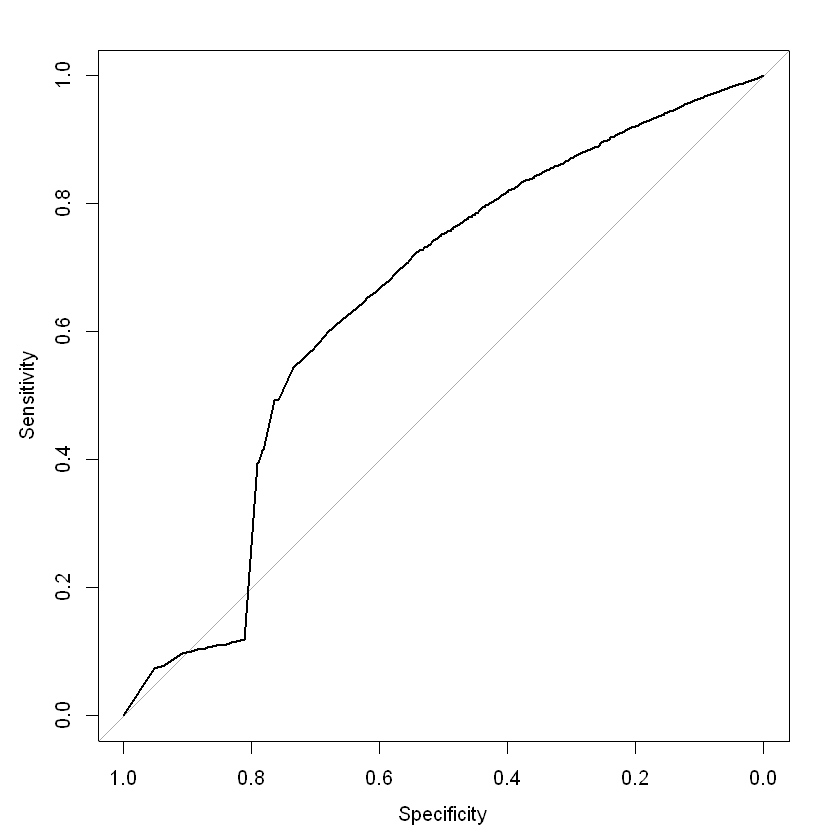

In [557]:
roc_m1 <- roc(
  test_data$is_churned,
  predictions
)

auc(roc_m1)
plot(roc_m1)

| Model | Variables | Number of Variables | Deviance Reduction | Recall | ROC-AUC |
| :---: | :--- | :---: | :---: | :---: | :---: |
| 1 | `reward_purchase_count_first_7days`, `first_payment_amount` | 2 | 2370 | 0 | 0.65 |

When implementing this first model, it can be observed that both predictor variables are statistically significant and that the residual deviance decreases compared to the null deviance, indicating an improvement in the model's fit compared to the null model.

However, when analyzing the confusion matrix, it is found that the model fails to identify any users who churn (Recall = 0%). This indicates that, with the selected variables and using a classification threshold of 0.5, the model is unable to correctly detect churn cases.

For this reason, the next model includes `reward_purchase_missing` and `permission_type` as additional predictor variables, with the aim of providing complementary information and improving the model's ability to detect users who leave the service.

In [558]:
m2 <- glm(is_churned ~ reward_purchase_count_first_7days + first_payment_amount + reward_purchase_missing + permission_type, data = train_data, family = binomial)
summary(m2)


Call:
glm(formula = is_churned ~ reward_purchase_count_first_7days + 
    first_payment_amount + reward_purchase_missing + permission_type, 
    family = binomial, data = train_data)

Coefficients:
                                    Estimate Std. Error z value Pr(>|z|)    
(Intercept)                       -1.4733037  0.0167100 -88.169  < 2e-16 ***
reward_purchase_count_first_7days -0.0667184  0.0052753 -12.647  < 2e-16 ***
first_payment_amount              -0.0026059  0.0001846 -14.117  < 2e-16 ***
reward_purchase_missing1           2.1158454  0.0205265 103.079  < 2e-16 ***
permission_typeNone                0.7127157  0.0336909  21.155  < 2e-16 ***
permission_typeOnly permission 1   0.3822851  0.0228519  16.729  < 2e-16 ***
permission_typeOnly permission 2   0.2278420  0.0348302   6.541 6.09e-11 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 87375  on 72900  degrees of freedom
Resi

In [559]:
predictions <- predict(m2, newdata = test_data, type = "response")

predicted_class <- ifelse(predictions >= 0.5, 1, 0)

In [560]:
confusionMatrix(
  factor(predicted_class, levels = c(0, 1)),
  factor(test_data$is_churned, levels = c(0, 1)),
  positive = "1"
)

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 20021  4243
         1  2261  4717
                                          
               Accuracy : 0.7918          
                 95% CI : (0.7873, 0.7963)
    No Information Rate : 0.7132          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.4551          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.5265          
            Specificity : 0.8985          
         Pos Pred Value : 0.6760          
         Neg Pred Value : 0.8251          
             Prevalence : 0.2868          
         Detection Rate : 0.1510          
   Detection Prevalence : 0.2234          
      Balanced Accuracy : 0.7125          
                                          
       'Positive' Class : 1               
                  

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Area under the curve: 0.7555

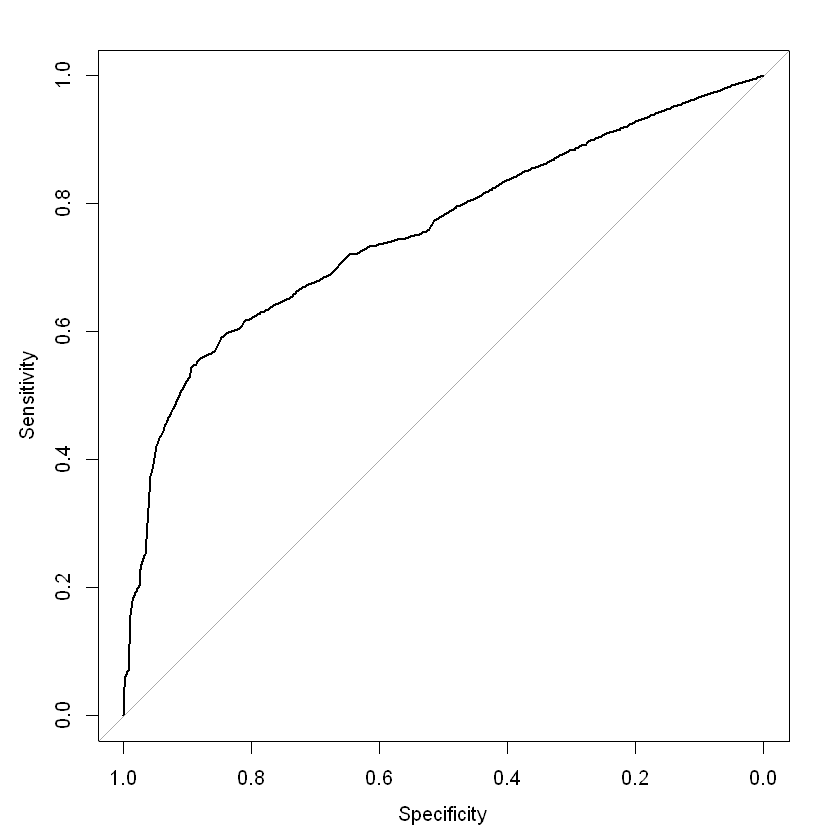

In [561]:
roc_m2 <- roc(
  test_data$is_churned,
  predictions
)

auc(roc_m2)
plot(roc_m2)

| Model | Variables | Number of Variables | Deviance Reduction | Recall | ROC-AUC |
| :---: | :--- | :---: | :---: | :---: | :---: |
| 1 | `reward_purchase_count_first_7days`, `first_payment_amount` | 2 | 2370 | 0 | 0.65 |
| **2** | **`reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type`** | 4 | **15006** | **0.5265** | **0.76** |

Compared to the first model, a considerable improvement can be observed. All the variables added in this second model have a p-value below 0.05, meaning that they provide statistically significant information to the model. Furthermore, there is a substantial reduction in the *residual deviance*, from 87,375 to 72,369, indicating an improvement in model fit.

On the other hand, the model is now able to identify users who churn, achieving a Recall of 52.65%. Although this represents a significant improvement over the first model, there is still room for improvement, as the model fails to detect approximately 47% of churn cases.

Finally, the model achieves a ROC-AUC of 0.76, indicating an acceptable ability to discriminate between users who churn and those who remain.

In the following model, `city` and `device` are also introduced.

In [562]:
m3 <- glm(is_churned ~ reward_purchase_count_first_7days + first_payment_amount + reward_purchase_missing + permission_type + device + city, data = train_data, family = binomial)
summary(m3)


Call:
glm(formula = is_churned ~ reward_purchase_count_first_7days + 
    first_payment_amount + reward_purchase_missing + permission_type + 
    device + city, family = binomial, data = train_data)

Coefficients:
                                    Estimate Std. Error z value Pr(>|z|)    
(Intercept)                       -1.1042890  0.0531966 -20.759  < 2e-16 ***
reward_purchase_count_first_7days -0.0650925  0.0052409 -12.420  < 2e-16 ***
first_payment_amount              -0.0018594  0.0001791 -10.382  < 2e-16 ***
reward_purchase_missing1           2.0606915  0.0208331  98.914  < 2e-16 ***
permission_typeNone                0.6708374  0.0344051  19.498  < 2e-16 ***
permission_typeOnly permission 1   0.3413600  0.0232233  14.699  < 2e-16 ***
permission_typeOnly permission 2   0.2546749  0.0351617   7.243 4.39e-13 ***
devicehmd global                   0.0964110  0.0771438   1.250 0.211389    
devicehuawei                       0.2815061  0.0579322   4.859 1.18e-06 ***
devicemotorola 

In [563]:
predictions <- predict(m3, newdata = test_data, type = "response")

predicted_class <- ifelse(predictions >= 0.5, 1, 0)

In [564]:
confusionMatrix(
  factor(predicted_class, levels = c(0, 1)),
  factor(test_data$is_churned, levels = c(0, 1)),
  positive = "1"
)

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 20144  4316
         1  2138  4644
                                          
               Accuracy : 0.7934          
                 95% CI : (0.7889, 0.7979)
    No Information Rate : 0.7132          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.4554          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.5183          
            Specificity : 0.9040          
         Pos Pred Value : 0.6848          
         Neg Pred Value : 0.8235          
             Prevalence : 0.2868          
         Detection Rate : 0.1486          
   Detection Prevalence : 0.2171          
      Balanced Accuracy : 0.7112          
                                          
       'Positive' Class : 1               
                  

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Area under the curve: 0.7644

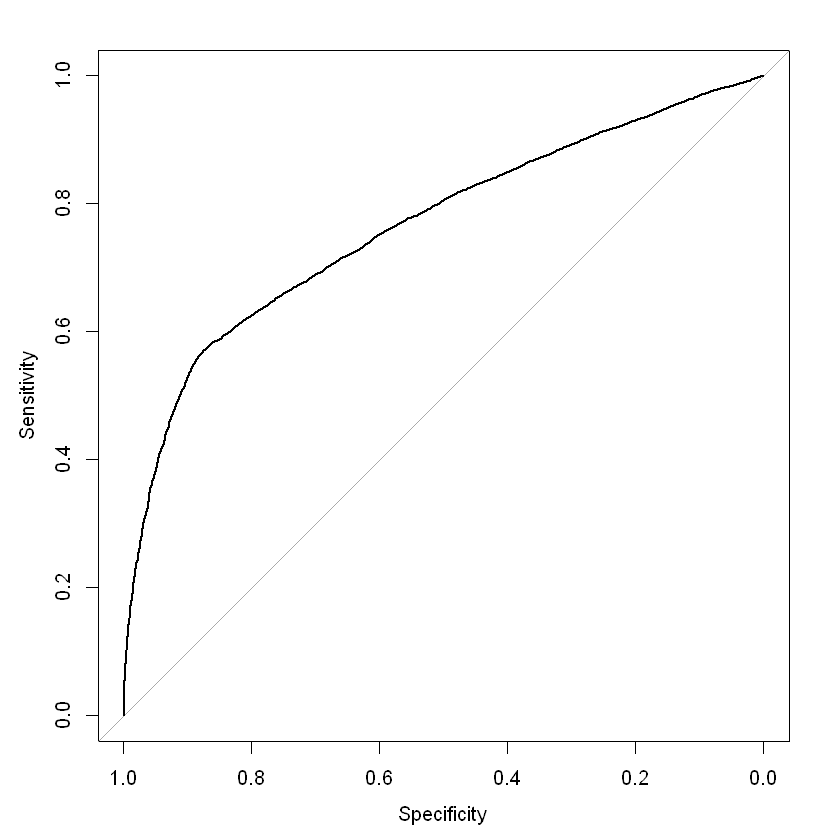

In [565]:
roc_m3 <- roc(
  test_data$is_churned,
  predictions
)

auc(roc_m3)
plot(roc_m3)

| Model | Variables | Number of variables | Deviance reduction | Recall | ROC-AUC |
| :---: | :--- | :---: | :---: | :---: | :---: |
| 1 | `reward_purchase_count_first_7days`, `first_payment_amount` | 2 | 2370 | 0 | 0.65 |
| **2** | **`reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type`** | **4** | **15006** | **0.5265** | **0.76** |
| 3 | `reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type`, `city`, `device` | 6 | 16429 | 0.5183 | 0.76 |

The third model presents an improvement in statistical fit through the incorporation of the variables `device` and `city`, which provide additional information to the model. However, when evaluating its predictive capacity on the test set, we observe that Recall decreases slightly compared to the second model (from 52.65% to 51.83%). Although there is also a small increase in ROC-AUC (from 0.7555 to 0.7644), this improvement is relatively minor.

Given that the main objective of the project is to detect users who churn, it is decided to keep the second model and discard `device` and `city`, prioritizing a simpler model that achieves a slightly higher Recall.

Next, different combinations of predictor variables will be explored, replacing some of the current variables with others that showed relevant weights in the PCA analysis. The objective will be to verify whether these combinations allow improving the predictive capacity of the model.

For this reason, `first_payment_amount` is swapped for `payments_completed_amount_first_7days`, which had a lower weight in the component but presented higher Information Gain.

In [566]:
m4 <- glm(is_churned ~ reward_purchase_count_first_7days + payments_completed_amount_first_7days + reward_purchase_missing + permission_type, data = train_data, family = binomial)
summary(m4)

Warning message:
"glm.fit: fitted probabilities numerically 0 or 1 occurred"



Call:
glm(formula = is_churned ~ reward_purchase_count_first_7days + 
    payments_completed_amount_first_7days + reward_purchase_missing + 
    permission_type, family = binomial, data = train_data)

Coefficients:
                                        Estimate Std. Error z value Pr(>|z|)
(Intercept)                           -1.4697286  0.0163610 -89.831  < 2e-16
reward_purchase_count_first_7days     -0.0363989  0.0054065  -6.732 1.67e-11
payments_completed_amount_first_7days -0.0027894  0.0001526 -18.278  < 2e-16
reward_purchase_missing1               2.0973351  0.0205753 101.935  < 2e-16
permission_typeNone                    0.7149474  0.0337542  21.181  < 2e-16
permission_typeOnly permission 1       0.3877080  0.0228856  16.941  < 2e-16
permission_typeOnly permission 2       0.2244498  0.0348394   6.442 1.18e-10
                                         
(Intercept)                           ***
reward_purchase_count_first_7days     ***
payments_completed_amount_first_7days ***


In [567]:
predictions <- predict(m4, newdata = test_data, type = "response")

predicted_class <- ifelse(predictions >= 0.5, 1, 0)

In [568]:
confusionMatrix(
  factor(predicted_class, levels = c(0, 1)),
  factor(test_data$is_churned, levels = c(0, 1)),
  positive = "1"
)

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 20053  4255
         1  2229  4705
                                          
               Accuracy : 0.7925          
                 95% CI : (0.7879, 0.7969)
    No Information Rate : 0.7132          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.4559          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.5251          
            Specificity : 0.9000          
         Pos Pred Value : 0.6785          
         Neg Pred Value : 0.8250          
             Prevalence : 0.2868          
         Detection Rate : 0.1506          
   Detection Prevalence : 0.2219          
      Balanced Accuracy : 0.7125          
                                          
       'Positive' Class : 1               
                  

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Area under the curve: 0.7623

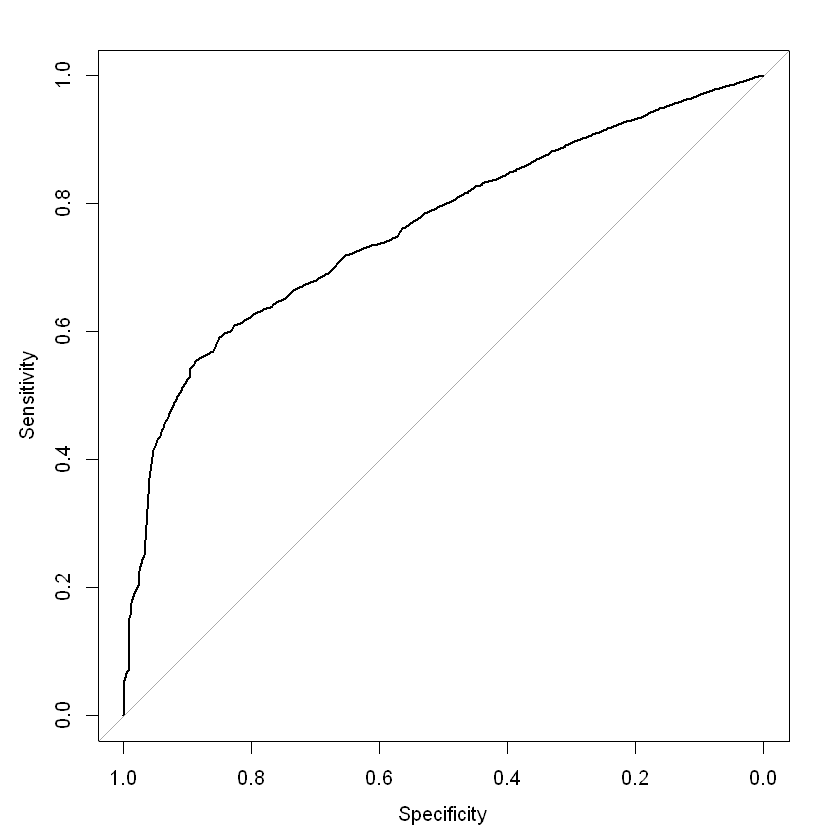

In [569]:
roc_m4 <- roc(
  test_data$is_churned,
  predictions
)

auc(roc_m4)
plot(roc_m4)

| Model | Variables | Number of variables | Deviance reduction | Recall | ROC-AUC |
| :---: | :--- | :---: | :---: | :---: | :---: |
| 1 | `reward_purchase_count_first_7days`, `first_payment_amount` | 2 | 2370 | 0 | 0.65 |
| **2** | **`reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type`** | **4** | **15006** | **0.5265** | **0.76** |
| 3 | `reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type`, `city`, `device` | 6 | 16429 | 0.5183 | 0.76 |
| 4 | `reward_purchase_count_first_7days`, `payments_completed_amount_first_7days`, `reward_purchase_missing`, `permission_type` | 4 | 15183 | 0.5251 | 0.76 |

After replacing `first_payment_amount` with `payments_completed_amount_first_7days`, we observe a slight improvement in the model's fit compared to model 2, reflected in the reduction of the *residual deviance* and the AIC. Furthermore, all the predictor variables remain statistically significant.

Regarding predictive capacity, Recall decreases slightly from 52.65% to 52.51%, meaning it does not improve the detection of users who churn. However, ROC-AUC increases from 0.7555 to 0.7623, indicating a slight improvement in the model's discrimination capability.

Therefore, the results show that the substitution provides a small improvement in fit and overall discrimination, although it does not improve the priority metric, Recall; for this reason, it is decided to continue with model 2.

In the following model, it is studied whether `reward_purchase_count_first_7days` is truly necessary, given that the variable `reward_purchase_missing` also exists.

In [570]:
m5 <- glm(is_churned ~ first_payment_amount + reward_purchase_missing + permission_type, data = train_data, family = binomial) 
summary(m5)


Call:
glm(formula = is_churned ~ first_payment_amount + reward_purchase_missing + 
    permission_type, family = binomial, data = train_data)

Coefficients:
                                   Estimate Std. Error  z value Pr(>|z|)    
(Intercept)                      -1.5865801  0.0145537 -109.016  < 2e-16 ***
first_payment_amount             -0.0028951  0.0001847  -15.673  < 2e-16 ***
reward_purchase_missing1          2.1658000  0.0202771  106.810  < 2e-16 ***
permission_typeNone               0.7235601  0.0336644   21.493  < 2e-16 ***
permission_typeOnly permission 1  0.3838500  0.0228190   16.822  < 2e-16 ***
permission_typeOnly permission 2  0.2373139  0.0348174    6.816 9.36e-12 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 87375  on 72900  degrees of freedom
Residual deviance: 72577  on 72895  degrees of freedom
AIC: 72589

Number of Fisher Scoring iterations: 4


In [571]:
predictions <- predict(m5, newdata = test_data, type = "response")

predicted_class <- ifelse(predictions >= 0.5, 1, 0)

In [572]:
confusionMatrix(
  factor(predicted_class, levels = c(0, 1)),
  factor(test_data$is_churned, levels = c(0, 1)),
  positive = "1"
)

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 20031  4245
         1  2251  4715
                                          
               Accuracy : 0.7921          
                 95% CI : (0.7875, 0.7966)
    No Information Rate : 0.7132          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.4555          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.5262          
            Specificity : 0.8990          
         Pos Pred Value : 0.6769          
         Neg Pred Value : 0.8251          
             Prevalence : 0.2868          
         Detection Rate : 0.1509          
   Detection Prevalence : 0.2230          
      Balanced Accuracy : 0.7126          
                                          
       'Positive' Class : 1               
                  

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Area under the curve: 0.7527

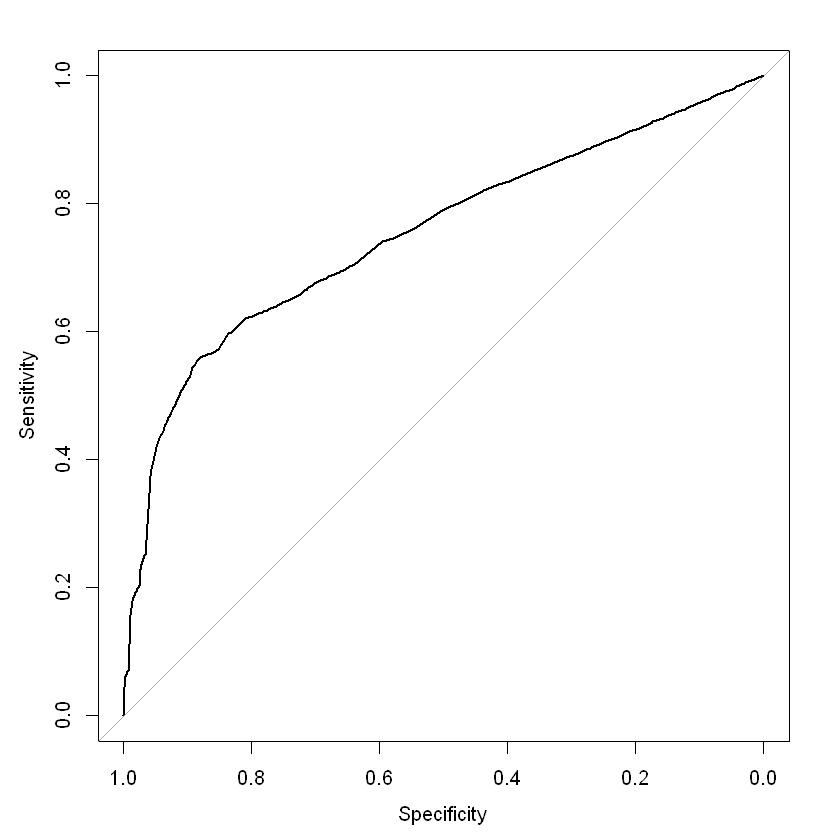

In [573]:
roc_m5 <- roc(
  test_data$is_churned,
  predictions
)

auc(roc_m5)
plot(roc_m5)

| Model | Variables | Number of variables | Deviance reduction | Recall | ROC-AUC |
| :---: | :--- | :---: | :---: | :---: | :---: |
| 1 | `reward_purchase_count_first_7days`, `first_payment_amount` | 2 | 2370 | 0 | 0.65 |
| 2 | `reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type` | 4 | 15006 | 0.5265 | 0.76 |
| 3 | `reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type`, `city`, `device` | 6 | 16429 | 0.5183 | 0.76 |
| 4 | `reward_purchase_count_first_7days`, `payments_completed_amount_first_7days`, `reward_purchase_missing`, `permission_type` | 4 | 15183 | 0.5251 | 0.76 |
| **5** | **`first_payment_amount`, `reward_purchase_missing`, `permission_type`** | **3** | **14798** | **0.5262** | **0.75** |

It is decided to remove `reward_purchase_count_first_7days` because its absence is already represented by `reward_purchase_missing`. Upon removing it, Recall remains practically the same (52.62%), while ROC-AUC decreases slightly (0.7527). Therefore, a simpler model is prioritized without appreciably losing the ability to detect churn.

In the following model, now that the variable `reward_purchase_count_first_7days` has been removed, another payment-related variable will be introduced, specifically `coins_redeemed_first_7days`, due to the Information Gain it provides.

In [574]:
m6 <- glm(is_churned ~ coins_redeemed_first_7days + first_payment_amount + reward_purchase_missing + permission_type, data = train_data, family = binomial)
summary(m6)


Call:
glm(formula = is_churned ~ coins_redeemed_first_7days + first_payment_amount + 
    reward_purchase_missing + permission_type, family = binomial, 
    data = train_data)

Coefficients:
                                   Estimate Std. Error  z value Pr(>|z|)    
(Intercept)                      -1.5672313  0.0150518 -104.123  < 2e-16 ***
coins_redeemed_first_7days       -0.0012118  0.0002527   -4.796 1.61e-06 ***
first_payment_amount             -0.0025487  0.0001962  -12.988  < 2e-16 ***
reward_purchase_missing1          2.1403109  0.0209067  102.374  < 2e-16 ***
permission_typeNone               0.7218633  0.0336585   21.447  < 2e-16 ***
permission_typeOnly permission 1  0.3839565  0.0228207   16.825  < 2e-16 ***
permission_typeOnly permission 2  0.2347001  0.0348167    6.741 1.57e-11 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 87375  on 72900  degrees of freedom
Residual de

In [575]:
predictions <- predict(m6, newdata = test_data, type = "response")

predicted_class <- ifelse(predictions >= 0.5, 1, 0)

In [576]:
confusionMatrix(
  factor(predicted_class, levels = c(0, 1)),
  factor(test_data$is_churned, levels = c(0, 1)),
  positive = "1"
)

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 20020  4243
         1  2262  4717
                                          
               Accuracy : 0.7918          
                 95% CI : (0.7872, 0.7963)
    No Information Rate : 0.7132          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.455           
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.5265          
            Specificity : 0.8985          
         Pos Pred Value : 0.6759          
         Neg Pred Value : 0.8251          
             Prevalence : 0.2868          
         Detection Rate : 0.1510          
   Detection Prevalence : 0.2234          
      Balanced Accuracy : 0.7125          
                                          
       'Positive' Class : 1               
                  

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Area under the curve: 0.7554

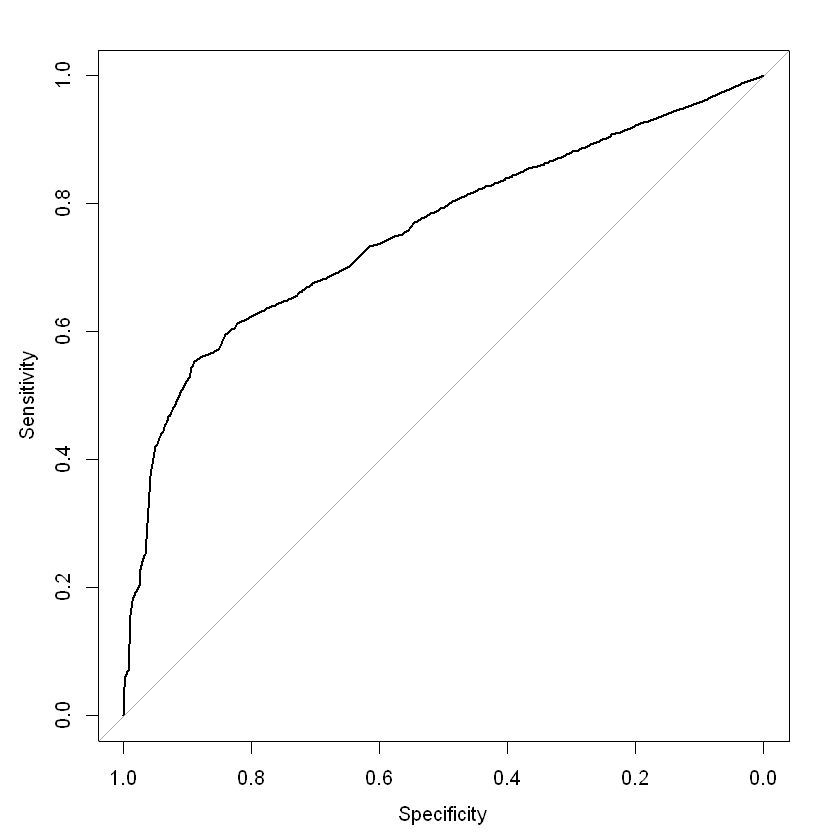

In [577]:
roc_m6 <- roc(
  test_data$is_churned,
  predictions
)

auc(roc_m6)
plot(roc_m6)

| Model | Variables | Number of variables | Deviance reduction | Recall | ROC-AUC |
| :---: | :--- | :---: | :---: | :---: | :---: |
| 1 | `reward_purchase_count_first_7days`, `first_payment_amount` | 2 | 2370 | 0 | 0.65 |
| 2 | `reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type` | 4 | 15006 | 0.5265 | 0.76 |
| 3 | `reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type`, `city`, `device` | 6 | 16429 | 0.5183 | 0.76 |
| 4 | `reward_purchase_count_first_7days`, `payments_completed_amount_first_7days`, `reward_purchase_missing`, `permission_type` | 4 | 15183 | 0.5251 | 0.76 |
| **5** | **`first_payment_amount`, `reward_purchase_missing`, `permission_type`** | **3** | **14798** | **0.5262** | **0.75** |
| 6 | `coins_redeemed_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type` | 4 | 14824 | 0.5265 | 0.76 |

It was decided not to incorporate `coins_redeemed_first_7days` into the final model, since its inclusion did not produce significant improvements in the evaluation metrics. Although a slight reduction in AIC and a small increase in ROC-AUC and Recall were observed, the differences were practically negligible. Therefore, it was decided to keep the simpler model.

In the final model, the variable `is_referral` is added, selected based on the observations made during the exploratory data analysis (EDA). In this way, the aim is to verify whether this variable provides additional predictive information and improves the model's performance, regardless of the results obtained through Information Gain.

In [578]:
m7 <- glm(is_churned ~ first_payment_amount + reward_purchase_missing + permission_type + is_referral, data = train_data, family = binomial)
summary(m7)


Call:
glm(formula = is_churned ~ first_payment_amount + reward_purchase_missing + 
    permission_type + is_referral, family = binomial, data = train_data)

Coefficients:
                                   Estimate Std. Error  z value Pr(>|z|)    
(Intercept)                      -1.7414802  0.0168756 -103.195  < 2e-16 ***
first_payment_amount             -0.0026228  0.0001827  -14.355  < 2e-16 ***
reward_purchase_missing1          2.1556452  0.0203394  105.984  < 2e-16 ***
permission_typeNone               0.6940431  0.0337388   20.571  < 2e-16 ***
permission_typeOnly permission 1  0.3625191  0.0229097   15.824  < 2e-16 ***
permission_typeOnly permission 2  0.2165394  0.0349520    6.195 5.82e-10 ***
is_referralTRUE                   0.3625806  0.0187088   19.380  < 2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 87375  on 72900  degrees of freedom
Residual deviance: 72202  on 72

In [579]:
predictions <- predict(m7, newdata = test_data, type = "response")
predicted_class <- ifelse(predictions >= 0.5, 1, 0)

In [580]:
confusionMatrix(
  factor(predicted_class, levels = c(0, 1)),
  factor(test_data$is_churned, levels = c(0, 1)),
  positive = "1"
)

Confusion Matrix and Statistics

          Reference
Prediction     0     1
         0 20038  4257
         1  2244  4703
                                          
               Accuracy : 0.7919          
                 95% CI : (0.7874, 0.7964)
    No Information Rate : 0.7132          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.4547          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       
                                          
            Sensitivity : 0.5249          
            Specificity : 0.8993          
         Pos Pred Value : 0.6770          
         Neg Pred Value : 0.8248          
             Prevalence : 0.2868          
         Detection Rate : 0.1505          
   Detection Prevalence : 0.2224          
      Balanced Accuracy : 0.7121          
                                          
       'Positive' Class : 1               
                  

Setting levels: control = 0, case = 1

Setting direction: controls < cases



Area under the curve: 0.7571

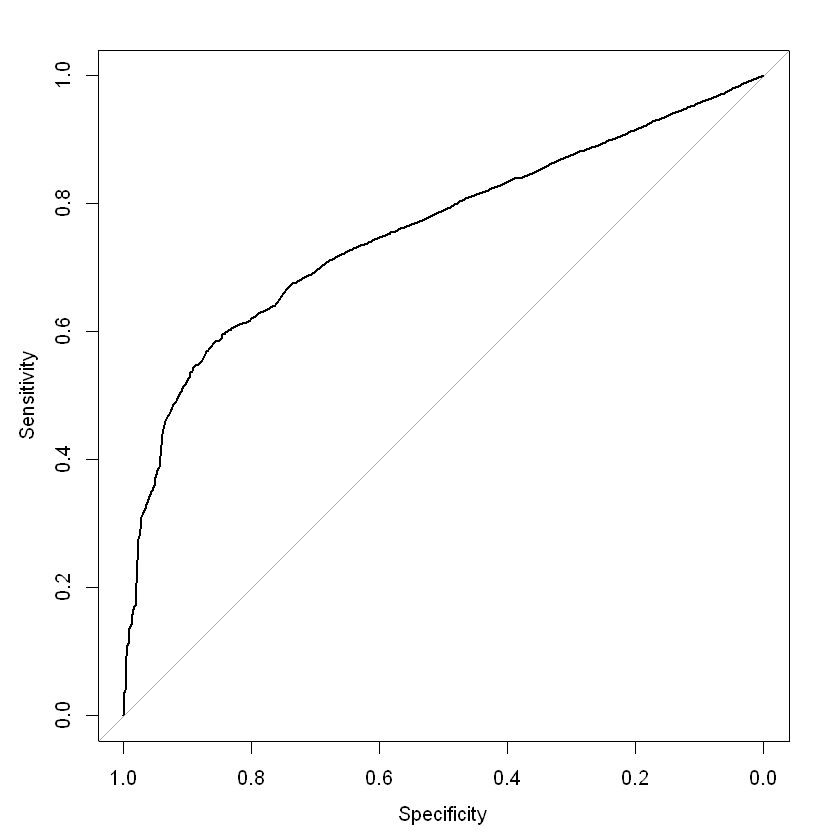

In [581]:
roc_m7 <- roc(
  test_data$is_churned,
  predictions
)

auc(roc_m7)
plot(roc_m7)

| Model | Variables | Number of variables | Deviance reduction | Recall | ROC-AUC |
| :---: | :--- | :---: | :---: | :---: | :---: |
| 1 | `reward_purchase_count_first_7days`, `first_payment_amount` | 2 | 2370 | 0 | 0.65 |
| 2 | `reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type` | 4 | 15006 | 0.5265 | 0.76 |
| 3 | `reward_purchase_count_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type`, `city`, `device` | 6 | 16429 | 0.5183 | 0.76 |
| 4 | `reward_purchase_count_first_7days`, `payments_completed_amount_first_7days`, `reward_purchase_missing`, `permission_type` | 4 | 15183 | 0.5251 | 0.76 |
| **5** | **`first_payment_amount`, `reward_purchase_missing`, `permission_type`** | **3** | **14798** | **0.5262** | **0.75** |
| 6 | `coins_redeemed_first_7days`, `first_payment_amount`, `reward_purchase_missing`, `permission_type` | 4 | 14824 | 0.5265 | 0.76 |
| 7 | `first_payment_amount`, `reward_purchase_missing`, `permission_type`, `is_referral` | 4 | 15173 | 0.5249 | 0.76 |

It was decided not to incorporate `is_referral` into the final model, since although it shows a statistically significant association with churn, its inclusion does not relevantly improve the predictive metrics. Furthermore, Recall decreases slightly; therefore, following the criterion of prioritizing the detection of users who churn, it is opted to keep the simpler model.

### Section conclusions

For the final selection, a balance between model sensitivity (Recall) and simplicity has been prioritized, avoiding the introduction of unnecessary complexity that does not provide significant improvements in performance.

Under this criterion, Model 5 (`first_payment_amount`, `reward_purchase_missing`, `permission_type`) is the most suitable option:

* **Simplicity:** It uses only 3 predictor variables, reducing model complexity and facilitating its interpretation. Furthermore, after observing a strong relationship between the different monetary metrics in the Principal Component Analysis (PCA), it was decided to avoid incorporating multiple payment-related variables that could provide redundant information. Nevertheless, it would be necessary to perform a specific multicollinearity analysis on the selected variables to confirm that this issue does not exist in the final model.
* **Competitive performance:** It achieves a Recall of 52.62%, virtually tied with the best model, which obtains 52.65%, and a ROC-AUC of 0.75, just one hundredth away from the highest recorded (0.76). In this way, it achieves a predictive capacity very similar to that of more complex alternatives, such as Model 3, using fewer predictor variables.

Regarding the selected model, the following conclusions are drawn:

1. **The value of missing information:** The most relevant finding at a business level is the weight of the `reward_purchase_missing` variable (which indicates the absence of records in `reward_purchase_count_first_7days`). With a z-value of 106, it presents high statistical evidence of association with churn, positioning itself as one of the most relevant variables in the model. This suggests that the absence of recorded reward purchase activity during the first 7 days constitutes an important signal of churn.
2. **Discriminative capacity vs. churn detection:** Although the model shows an acceptable overall capacity to distinguish between both classes (ROC-AUC of 0.75), a Recall of 52.62% implies that the system only manages to identify approximately 1 out of every 2 users who churn. In a real retention environment, this rate would mean failing to detect nearly half of the customers who ultimately leave. Therefore, although the model allows identifying certain risk profiles, it would still be necessary to improve its sensitivity before considering its use in production.
3. **Testing with other models:** Given that logistic regression with few variables offers good interpretability, yet presents limitations regarding sensitivity, it would be interesting to evaluate other Machine Learning algorithms to verify whether they allow improving churn detection.

## 4. Conclusions and Open Paths

- What recommendations would you give this company to reduce churn?
- How does the model you have calculated help you reach these conclusions?

Regarding the practical use of the developed tool, the main recommendation for the company is to employ the model as a detection system for users at risk of churn. When the model predicts a possible case of *churn*, the team will be able to conduct an individualized analysis of that user to decide whether it is worth investing in a retention campaign. However, given that the model still presents limitations in its detection capacity, these predictions should be used as a support tool rather than an automatic rule, always leaving the final decision to human judgment.

Regarding business actions to prevent this churn from occurring, the analysis has identified that the most relevant variables are related to payments, rewards, and permissions. Through the sign of the estimated coefficients of the logistic regression, it is possible to interpret the direction of the association between these variables and *churn*. First, the absence of reward purchase records presents a positive coefficient, indicating an association with higher probabilities of churn. Therefore, a possible measure would be to make it easier for users to obtain rewards for their purchases from the very first stages of using the platform.

On the other hand, the variables linked to payment show negative coefficients, indicating that a higher value of these variables is associated with lower probabilities of churn. Consequently, it could be worthwhile to study mechanisms or incentives that encourage users to complete their first payment. This measure could be related to the previous one, as offering rewards could incentivize making payments and help improve user engagement with the platform. However, the results obtained do not allow us to claim that these actions directly reduce churn, so it would be advisable to evaluate their effectiveness through controlled tests.

Likewise, permissions also show a relevant association with *churn*: users who do not have certain permissions show a higher tendency to churn according to the model's results. Although this exercise does not allow us to know how these permissions are obtained within the platform nor prove that granting them reduces churn, it would be interesting to investigate whether simplifying the process to obtain them can encourage user engagement.

In an integrated manner, the strategy to reduce *churn* should focus on three complementary fronts: incentivizing the acquisition of rewards from the earliest interactions, designing mechanisms that favor making the first payment, and facilitating the permission-granting process. These proposals should initially be implemented through controlled tests to verify whether they truly contribute to improving user retention.